Pada tahap sebelumnya, telah dilakukan pengolahan dan eksperimen awal menggunakan data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Juni 2026 dengan pendekatan prediksi visibility. Namun, seiring dengan perkembangan proses penelitian dan pertimbangan terhadap karakteristik data, pendekatan tersebut kemudian disesuaikan menjadi klasifikasi kondisi visibility. Oleh karena itu, notebook ini melanjutkan proses penelitian dengan berfokus pada penerapan model *machine learning* berbasis pohon keputusan untuk mengklasifikasikan kondisi visibility berdasarkan kategori jarak pandang yang telah ditentukan.

### Data Source & Acquisition

The dataset used in this notebook was collected via web scraping from **[Ogimet](https://www.ogimet.com/synops.phtml.en)**, a public meteorological archive that compiles global surface weather reports transmitted through the **World Meteorological Organization (WMO) Global Telecommunication System (GTS)**. Every hour, surface observations recorded by BMKG at Sultan Thaha Airport are encoded into international **SYNOP (`AAXX`)** messages and broadcast to the GTS network, making Ogimet a direct archive of official station records.

Using a custom Python scraper (`urllib` and `html.parser`), hourly SYNOP tables for **2025** were retrieved from Ogimet's query endpoint (`display_synops2.php`). The raw 5-digit WMO code blocks were decoded into tabular meteorological variables and mapped to match BMKG's standard column naming convention so the raw dataset is ready to be loaded and processed in this notebook.

* **Station:** Sultan Thaha Meteorological Station, Jambi (WMO ID: `96195` | ICAO: `WIJJ`)
* **Period:** January 1 – December 31, 2025 (Hourly resolution in **UTC**)
* **Raw Format:** Decoded Surface Synoptic Reports (`SYNOP / AAXX`) stored as CSV

# 1. Data Loading and Inspection

Tahap ini diawali dengan memuat data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025. Data tersebut digunakan sebagai dataset utama dalam penerapan model *machine learning* berbasis pohon keputusan untuk klasifikasi kondisi visibility. Pemeriksaan awal dilakukan untuk memahami struktur dan karakteristik dataset, meliputi jumlah baris dan kolom, tipe data setiap variabel, keberadaan missing value, konsistensi interval waktu pencatatan, serta distribusi dan rentang nilai setiap variabel. Hasil pemeriksaan ini menjadi dasar untuk menentukan langkah pengolahan data pada tahap selanjutnya.

## 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from scipy.stats import kruskal, randint, uniform, loguniform
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, ConfusionMatrixDisplay, precision_recall_fscore_support, balanced_accuracy_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.inspection import permutation_importance

## 1.2 Load Dataset

Dataset dimuat dari file CSV yang berisi data observasi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025. Dataset ini akan digunakan sebagai sumber data utama dalam proses klasifikasi kondisi visibility.

In [2]:
data_df = pd.read_csv('../visibility-dataset/stamet_jambi_hourly_full_2025.csv')
data_df.head()

,station_name,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,...,cloud_cover_oktas_m,rainfall_24h_rrrr,rainfall_mm,rainfall_period_h,ix_flag,phenomenon,weather_code_ww,visibility_vv,report_type,raw_synop
0,Stasiun Meteorologi Sultan Thaha,2025-01-01 00:00:00,300,5,1006.8,1009.8,25.8,24.8,25.1,94,...,7,NaN,0.0,NaN,1,Haze/Smoke/Dust,5.0,7.0,SM,AAXX 01004 96195 31457 73005 10258 20248 30068...
1,Stasiun Meteorologi Sultan Thaha,2025-01-01 01:00:00,310,9,1007.6,1010.6,26.7,24.8,25.3,89,...,7,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01014 96195 42460 73109 10267 20248 30076...
2,Stasiun Meteorologi Sultan Thaha,2025-01-01 02:00:00,310,8,1008.0,1011.0,28.0,24.8,25.6,83,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01024 96195 42460 63108 10280 20248 30080...
3,Stasiun Meteorologi Sultan Thaha,2025-01-01 03:00:00,350,10,1007.9,1010.9,29.5,24.5,25.8,75,...,6,NaN,0.0,NaN,2,Normal,NaN,10.0,SI,AAXX 01034 96195 32460 63510 10295 20245 30079...
4,Stasiun Meteorologi Sultan Thaha,2025-01-01 04:00:00,330,10,1007.3,1010.3,30.6,24.4,26.1,70,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01044 96195 42460 63310 10306 20244 30073...


## 1.3 Check Data Structure

Pemeriksaan awal dilakukan untuk mengetahui dimensi dataset, meliputi jumlah baris dan kolom, serta tipe data pada masing-masing kolom. Informasi ini digunakan untuk memahami struktur dataset dan mengidentifikasi variabel yang memerlukan penyesuaian tipe data sebelum proses pengolahan lebih lanjut.

In [3]:
data_df.shape

(8400, 21)

In [4]:
data_df.dtypes

station_name                   str
data_timestamp                 str
wind_dir_deg_dd              int64
wind_speed_ff                int64
pressure_qfe_mb_derived    float64
pressure_qff_mb_derived    float64
temp_drybulb_c_tttttt      float64
temp_dewpoint_c_tdtdtd     float64
temp_wetbulb_c             float64
relative_humidity_pc         int64
cloud_low_cover_1          float64
cloud_cover_oktas_m          int64
rainfall_24h_rrrr          float64
rainfall_mm                float64
rainfall_period_h          float64
ix_flag                      int64
phenomenon                     str
weather_code_ww            float64
visibility_vv              float64
report_type                    str
raw_synop                      str
dtype: object

**Notes:**

- Dataset terdiri dari **8.400 baris** dan **21 kolom**.
- Kolom `data_timestamp` masih terbaca sebagai tipe `str` (*string*), sehingga perlu dikonversi ke format `datetime` (`datetime64`) untuk memudahkan pengurutan kronologis dan ekstraksi fitur waktu (jam dan bulan).
- Seluruh parameter meteorologi utama sudah memiliki tipe numerik (`int64` dan `float64`) yang sesuai.

## 1.4 Check Missing Values

Pemeriksaan missing values dilakukan untuk mengetahui jumlah data yang kosong pada setiap variabel. Pemeriksaan ini bertujuan untuk mengevaluasi kelengkapan data serta mengidentifikasi variabel yang memerlukan penanganan pada tahap preprocessing. Perhatian khusus diberikan pada variabel phenomenon karena digunakan sebagai target dalam proses klasifikasi.

In [5]:
data_df.isna().sum()

station_name                  0
data_timestamp                0
wind_dir_deg_dd               0
wind_speed_ff                 0
pressure_qfe_mb_derived       0
pressure_qff_mb_derived       0
temp_drybulb_c_tttttt         0
temp_dewpoint_c_tdtdtd        0
temp_wetbulb_c                0
relative_humidity_pc          0
cloud_low_cover_1             4
cloud_cover_oktas_m           0
rainfall_24h_rrrr          8173
rainfall_mm                5841
rainfall_period_h          7865
ix_flag                       0
phenomenon                    0
weather_code_ww            3832
visibility_vv                 0
report_type                   0
raw_synop                     0
dtype: int64

**Notes:**

- `weather_code_ww` => 3.832

    Variabel `phenomenon` tidak memiliki missing value karena setiap observasi telah diberikan label berdasarkan hasil decoding kode cuaca dan informasi `ix_flag` pada tahap pembentukan dataset.
- `cloud_low_cover_1` => 4
- `rainfall_24h_rrrr` => 8.173
- `rainfall_mm` => 5.841
- `rainfall_period_h` => 7.865

## 1.5 Check Time Range and Interval Consistency

Kolom `data_timestamp` dikonversi ke format datetime agar rentang waktu pengamatan dan selisih waktu antarbaris dapat diperiksa. Pemeriksaan ini bertujuan untuk mengetahui konsistensi interval pencatatan data serta mengidentifikasi kemungkinan adanya lompatan waktu atau duplikasi timestamp.

In [6]:
temp_date = pd.to_datetime(data_df['data_timestamp'], errors='coerce')
temp_date = temp_date.sort_values().reset_index(drop=True)

In [7]:
print(temp_date.min())
print(temp_date.max())

2025-01-01 00:00:00
2025-12-31 23:00:00


In [8]:
interval = temp_date.diff()
print(interval.value_counts())

data_timestamp
0 days 01:00:00    8118
0 days 02:00:00     215
0 days 03:00:00      61
0 days 06:00:00       2
0 days 07:00:00       1
0 days 04:00:00       1
0 days 05:00:00       1
Name: count, dtype: int64


In [9]:
data_df.loc[interval > pd.Timedelta(hours=3), ['data_timestamp', 'report_type']].head(10)

,data_timestamp,report_type
2644,2025-04-23 12:00:00,SM
6553,2025-10-09 03:00:00,SI
7858,2025-12-05 06:00:00,SM
7859,2025-12-05 12:00:00,SM
7900,2025-12-10 17:00:00,SN


## 1.6 Check Missing Value Pattern in Cloud Cover Layer 1

Pemeriksaan dilakukan untuk mengetahui pola missing value pada variabel `cloud_low_cover_1` dengan membandingkannya terhadap total tutupan awan (`cloud_cover_oktas_m`). Analisis ini bertujuan mengidentifikasi hubungan antara nilai kosong pada lapisan awan rendah dengan kondisi total tutupan awan, sehingga dapat menentukan penanganan yang sesuai pada tahap preprocessing.

In [10]:
data_df.loc[data_df['cloud_low_cover_1'].isna(), ['cloud_low_cover_1', 'cloud_cover_oktas_m']]

,cloud_low_cover_1,cloud_cover_oktas_m
2813,NaN,9
2814,NaN,9
2815,NaN,9
3681,NaN,7


In [11]:
data_df.loc[(data_df['cloud_low_cover_1'].isna()) & (data_df['cloud_cover_oktas_m'] != 9), ['cloud_low_cover_1', 'cloud_cover_oktas_m', 'raw_synop']]

,cloud_low_cover_1,cloud_cover_oktas_m,raw_synop
3681,NaN,7,AAXX 07004 96195 11936 72701 10248 20243 30082...


In [12]:
print(data_df.loc[3681, 'raw_synop'])

AAXX 07004 96195 11936 72701 10248 20243 30082 40112 53013 60014 71022 86/71 333 20236 50260 55000 56900 59019 86360=


In [13]:
data_df.loc[data_df['cloud_cover_oktas_m'] == 9, ['cloud_low_cover_1', 'cloud_cover_oktas_m']]

,cloud_low_cover_1,cloud_cover_oktas_m
2813,NaN,9
2814,NaN,9
2815,NaN,9


In [14]:
data_df.loc[data_df['cloud_low_cover_1'] == 0, ['cloud_low_cover_1', 'cloud_cover_oktas_m']].head()

,cloud_low_cover_1,cloud_cover_oktas_m
523,0.0,7
692,0.0,7
714,0.0,7
715,0.0,7
891,0.0,7


**Notes:**

- 3 data dengan `cloud_cover_oktas_m` = 9 juga memiliki nilai kosong pada `cloud_low_cover_1`
- Kode 9 pada `cloud_cover_oktas_m` menunjukkan kondisi langit terhalang sehingga jumlah tutupan awan tidak dapat ditentukan.

## 1.7 Check Value Range (Min/Max)

Pemeriksaan nilai minimum dan maksimum dilakukan untuk mengetahui rentang nilai setiap variabel numerik serta mengidentifikasi kemungkinan nilai ekstrem, anomali, atau nilai yang memerlukan pemeriksaan lebih lanjut berdasarkan karakteristik masing-masing variabel.

Ringkasan nilai minimum dan maksimum seluruh variabel numerik

In [15]:
data_df.describe().T[['min', 'max']]

,min,max
wind_dir_deg_dd,0.00,360.0
wind_speed_ff,0.00,25.0
pressure_qfe_mb_derived,999.20,1012.2
pressure_qff_mb_derived,1002.20,1015.2
temp_drybulb_c_tttttt,21.60,35.2
temp_dewpoint_c_tdtdtd,19.40,26.8
temp_wetbulb_c,20.90,27.8
relative_humidity_pc,42.00,100.0
cloud_low_cover_1,0.00,8.0
cloud_cover_oktas_m,1.00,9.0


## 1.8 Check Unique Value Distribution

Pemeriksaan dilakukan dengan melihat nilai unik pada variabel tertentu beserta frekuensi kemunculannya untuk memahami pola distribusi data dan mengidentifikasi kemungkinan nilai anomali. Pemeriksaan pada variabel visibility juga digunakan untuk mengetahui sebaran nilai jarak pandang sebagai bahan pertimbangan dalam menentukan kategori kelas klasifikasi.

`RAINFALL`

In [16]:
data_df['rainfall_period_h'].sort_values().value_counts()

rainfall_period_h
6.0     308
24.0    227
Name: count, dtype: int64

In [17]:
data_df['rainfall_24h_rrrr'].value_counts().sort_index()

rainfall_24h_rrrr
0.05      32
0.10       6
0.20       7
0.30       6
0.40       6
0.50       1
0.60       4
0.70       4
0.80       1
0.90       3
1.00      12
2.00      17
3.00      13
4.00       7
5.00      17
6.00       5
7.00       8
8.00       5
9.00       5
10.00      3
11.00      2
12.00      2
14.00      4
15.00      4
16.00      2
17.00      4
18.00      2
19.00      1
20.00      2
21.00      3
22.00      1
23.00      2
24.00      2
25.00      2
26.00      1
27.00      2
29.00      3
30.00      1
31.00      2
32.00      1
33.00      2
34.00      1
35.00      1
38.00      1
40.00      1
45.00      1
46.00      1
48.00      1
51.00      2
52.00      1
53.00      2
59.00      1
66.00      1
69.00      2
76.00      1
77.00      1
84.00      1
133.00     1
Name: count, dtype: int64

In [18]:
data_df['rainfall_mm'].value_counts().sort_index()

rainfall_mm
0.00      2024
0.05       101
0.10        20
0.20        20
0.30        14
          ... 
76.00        3
77.00        1
81.00        1
84.00        2
133.00       1
Name: count, Length: 65, dtype: int64

`VISIBILITY`

In [19]:
data_df['visibility_vv'].value_counts().sort_index()

visibility_vv
0.1        1
0.2        9
0.3        7
0.4        4
0.5       10
0.6        4
0.7        7
0.8       10
0.9        4
1.0       33
1.1        5
1.2       14
1.3        7
1.4        3
1.5       47
1.6        7
1.7        7
1.8       10
1.9        7
2.0       98
2.1        3
2.2        7
2.3        8
2.4       12
2.5       70
2.6       11
2.7       11
2.8       12
2.9        9
3.0      242
3.1       10
3.2       11
3.3        8
3.4       14
3.5       59
3.6       12
3.7        9
3.8       11
3.9       11
4.0      285
4.1       12
4.2        7
4.3        8
4.4       10
4.5       33
4.6       10
4.7        8
4.8       14
4.9       11
5.0      946
6.0      562
7.0      914
8.0      588
9.0      311
10.0    3856
12.0       1
Name: count, dtype: int64

In [20]:
data_df.loc[data_df['visibility_vv'] == 0.1, ['data_timestamp']]

,data_timestamp
1117,2025-02-16 22:00:00


In [21]:
print(data_df.loc[1117, 'raw_synop'])

AAXX 16224 96195 41401 60000 10239 20235 30075 40105 74444 82521 333 56000 82614 84460=


In [22]:
data_df['phenomenon'].value_counts().sort_index()

phenomenon
Active Precipitation             754
Fog                               50
Haze/Smoke/Dust                 2643
Mist                             427
Normal                          4020
Other                             50
Recent/Distant Precipitation     456
Name: count, dtype: int64

## 1.9 Check Descriptive Statistics

Menampilkan ringkasan statistik yang meliputi jumlah data, rata-rata, standar deviasi, nilai minimum, maksimum, dan kuartil untuk variabel numerik. Pemeriksaan ini bertujuan untuk memahami karakteristik umum dan distribusi nilai setiap variabel dalam dataset.

In [23]:
data_df.describe()

,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,rainfall_24h_rrrr,rainfall_mm,rainfall_period_h,ix_flag,weather_code_ww,visibility_vv
count,8400.000000,8400.000000,8400.000000,8400.000000,8400.000000,8400.000000,8400.000000,8400.000000,8396.000000,8400.000000,227.000000,2559.000000,535.000000,8400.000000,4568.000000,8400.000000
mean,180.271429,3.595357,1006.419179,1009.434774,27.395190,24.081119,24.984762,83.192381,3.425083,6.956190,11.180617,1.663873,13.637383,1.456190,17.720884,7.647619
std,104.323024,2.295152,1.860301,1.864620,2.733065,0.882031,1.099540,11.905465,1.527741,0.970813,18.193312,7.673703,8.904577,0.498107,23.556050,2.636775
min,0.000000,0.000000,999.200000,1002.200000,21.600000,19.400000,20.900000,42.000000,0.000000,1.000000,0.050000,0.000000,6.000000,1.000000,1.000000,0.100000
25%,110.000000,2.000000,1005.100000,1008.200000,25.200000,23.500000,24.200000,74.000000,2.000000,7.000000,0.450000,0.000000,6.000000,1.000000,5.000000,5.000000
50%,170.000000,3.000000,1006.500000,1009.500000,26.800000,24.100000,25.000000,87.000000,3.000000,7.000000,4.000000,0.000000,6.000000,1.000000,5.000000,8.000000
75%,280.000000,5.000000,1007.800000,1010.800000,29.500000,24.700000,25.800000,94.000000,4.250000,8.000000,14.500000,0.000000,24.000000,2.000000,21.000000,10.000000
max,360.000000,25.000000,1012.200000,1015.200000,35.200000,26.800000,27.800000,100.000000,8.000000,9.000000,133.000000,133.000000,24.000000,2.000000,97.000000,12.000000


## 1.10 Check Duplicate Rows

Pemeriksaan dilakukan untuk mengetahui keberadaan baris data yang terduplikasi, sehingga setiap observasi dalam dataset dapat dipastikan tidak memiliki duplikasi secara keseluruhan.

In [24]:
print(data_df['data_timestamp'].duplicated().sum())

0


# 2. Exploratory Data Analysis (EDA)

Tahap eksplorasi data dilakukan untuk memahami karakteristik dataset sebelum proses preprocessing. Seluruh analisis pada tahap ini dilakukan pada salinan dataset (`eda_df`) sehingga data asli (`data_df`) tidak mengalami perubahan

## 2.1 Prepare EDA Copy

Salinan dataset dibuat untuk keperluan eksplorasi, kemudian ditambahkan beberapa kolom bantu berupa waktu dalam WIB, jam, bulan, dan selisih suhu dengan titik embun (dew point depression). Kolom bantu ini hanya digunakan untuk analisis dan belum menjadi bagian dari proses feature engineering. Daftar variabel numerik juga disiapkan pada tahap ini. Variabel arah angin tidak dimasukkan karena merupakan data sudut (0–360°), sehingga tidak sesuai dianalisis seperti variabel numerik biasa.

In [25]:
eda_df = data_df.copy()

In [26]:
eda_df['data_timestamp'] = pd.to_datetime(eda_df['data_timestamp'])
eda_df['datetime_wib'] = eda_df['data_timestamp'] + pd.Timedelta(hours=7)

In [27]:
eda_df['hour_wib'] = eda_df['datetime_wib'].dt.hour
eda_df['month_wib'] = eda_df['datetime_wib'].dt.month

In [28]:
eda_df['dewpoint_depression'] = eda_df['temp_drybulb_c_tttttt'] - eda_df['temp_dewpoint_c_tdtdtd']

In [29]:
num_cols = ['wind_speed_ff', 'pressure_qfe_mb_derived', 'pressure_qff_mb_derived',
            'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c',
            'relative_humidity_pc', 'cloud_low_cover_1', 'cloud_cover_oktas_m',
            'rainfall_24h_rrrr', 'rainfall_mm', 'visibility_vv', 'dewpoint_depression']

## 2.2 Target Distribution

Pemeriksaan distribusi variabel target `phenomenon` dilakukan untuk mengetahui jumlah dan proporsi data pada setiap kelas fenomena. Informasi ini digunakan untuk mengidentifikasi adanya ketidakseimbangan kelas yang perlu diperhatikan pada tahap pemodelan dan evaluasi.

In [30]:
eda_df['phenomenon'].value_counts()

phenomenon
Normal                          4020
Haze/Smoke/Dust                 2643
Active Precipitation             754
Recent/Distant Precipitation     456
Mist                             427
Fog                               50
Other                             50
Name: count, dtype: int64

In [31]:
eda_df['phenomenon'].value_counts(normalize=True).round(2)

phenomenon
Normal                          0.48
Haze/Smoke/Dust                 0.31
Active Precipitation            0.09
Recent/Distant Precipitation    0.05
Mist                            0.05
Fog                             0.01
Other                           0.01
Name: proportion, dtype: float64

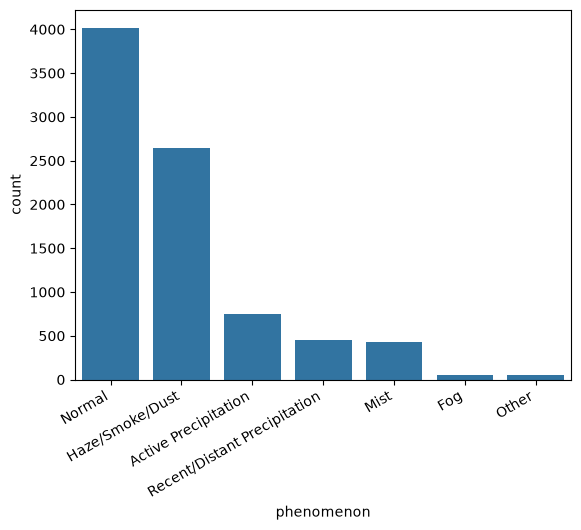

In [32]:
sns.countplot(data=eda_df, x='phenomenon', order=eda_df['phenomenon'].value_counts().index)
plt.xticks(rotation=30, ha='right')
plt.show()

**Notes:**

Dari hasil distribusi target, terlihat bahwa jumlah data pada setiap kelas `phenomenon` tidak merata (*class imbalance*). Kelas **Normal** memiliki jumlah data paling banyak, yaitu **4.020 data (48%)**, diikuti oleh **Haze/Smoke/Dust** sebanyak **2.643 data (31%)**. Sementara itu, kelas **Fog** dan **Other** memiliki jumlah data paling sedikit, masing-masing hanya **50 data (sekitar 1%)**.

Perbedaan proporsi yang cukup ekstrem ini perlu diperhatikan pada tahap pemodelan karena model cenderung lebih mudah mengenali kelas mayoritas dibandingkan kelas minoritas. Oleh karena itu, perlu dipertimbangkan strategi penanganan ketidakseimbangan kelas serta pemilihan metrik evaluasi yang dapat merepresentasikan performa prediksi pada setiap kelas secara menyeluruh (seperti *precision*, *recall*, *F1-score*, dan *macro average*).

## 2.3 Numeric Feature Distribution

Distribusi setiap variabel numerik ditampilkan dalam bentuk histogram untuk mengetahui bentuk sebaran data, seperti kecenderungan miring (skewed), penumpukan pada nilai tertentu, serta keberadaan nilai yang tampak ekstrem. Pemeriksaan ini membantu menentukan perlunya penanganan lebih lanjut pada tahap preprocessing.

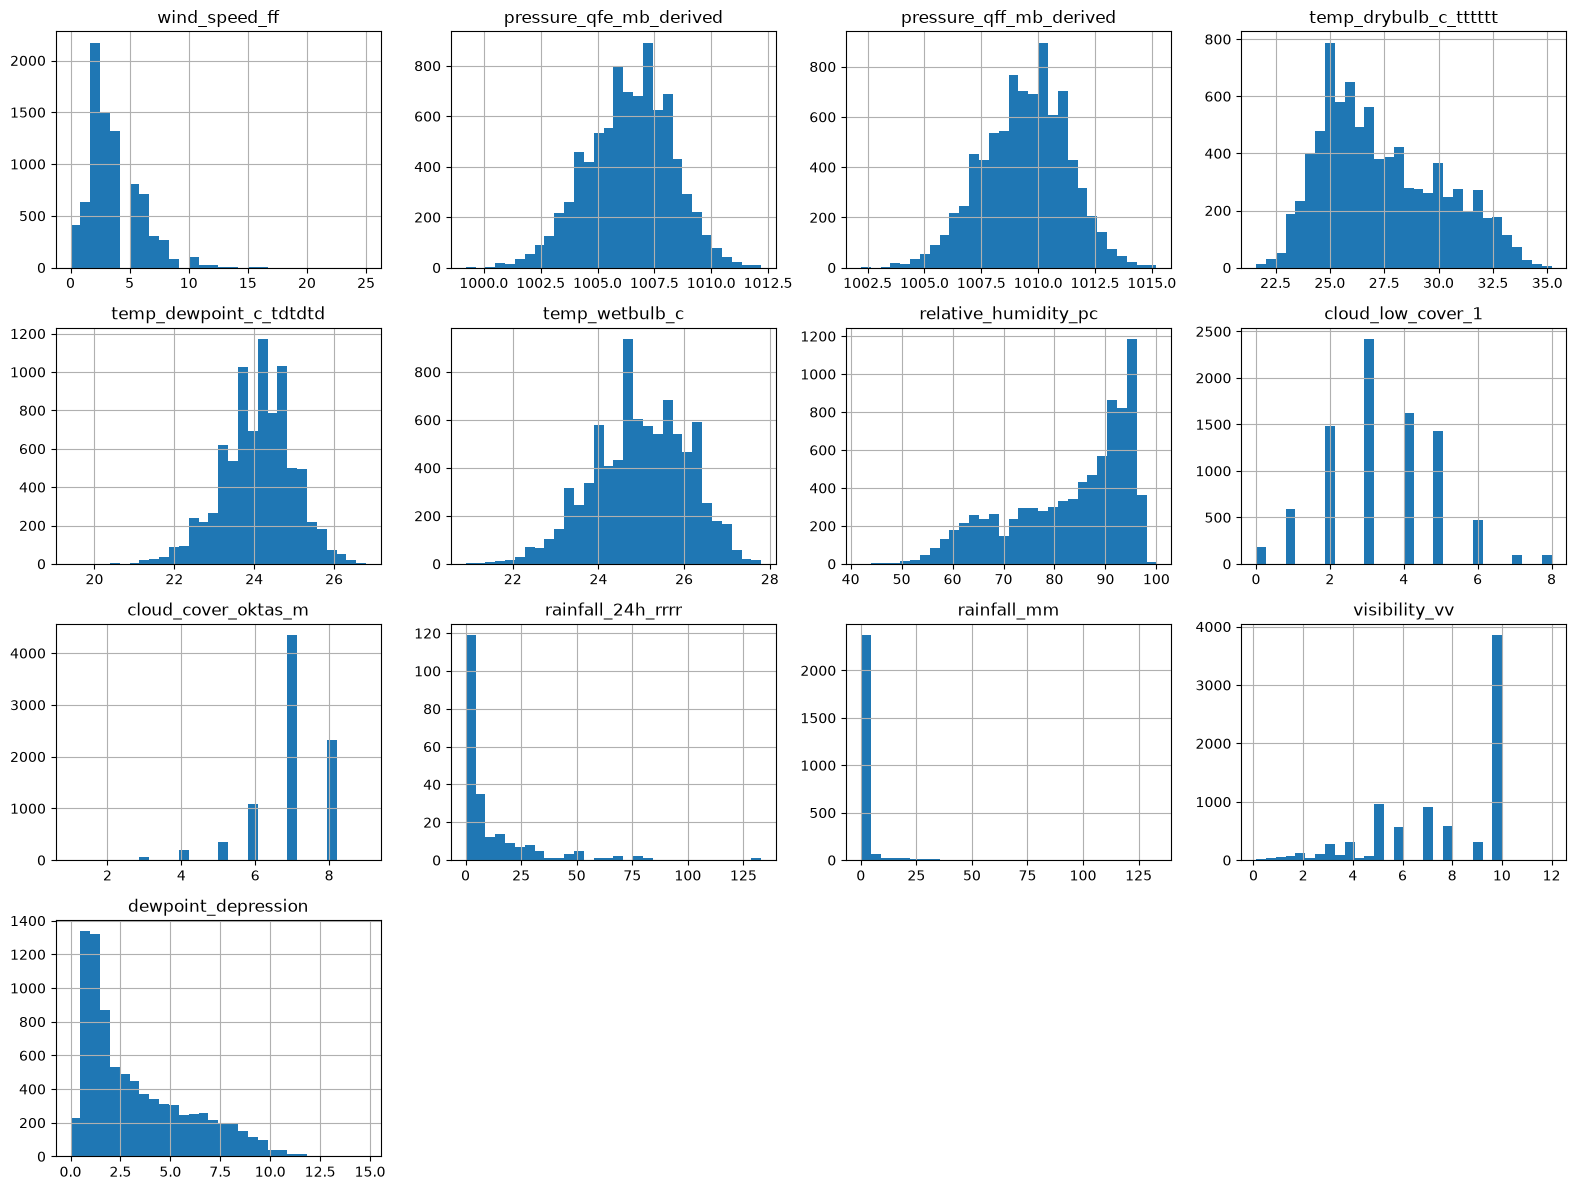

In [33]:
eda_df[num_cols].hist(bins=30, figsize=(16,12))
plt.tight_layout()
plt.show()

In [34]:
def hist_text(s, bins=10):
    s = s.dropna()
    counts, edges = np.histogram(s, bins=bins)
    return ' | '.join(f'{edges[i]:.1f}-{edges[i+1]:.1f}: {counts[i]}' for i in range(len(counts)))

print(eda_df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(2).to_string())

for col in num_cols:
    print(f'\n{col}\n  {hist_text(eda_df[col])}')

# kolom diskrit: lebih jelas pakai value counts
for col in ['cloud_low_cover_1', 'cloud_cover_oktas_m']:
    print(f'\n{col}:', eda_df[col].value_counts().sort_index().to_dict())

# rainfall: proporsi nol dan NaN
print('\nrainfall_mm  nol  :', round((eda_df['rainfall_mm'] == 0).mean() * 100, 1), '%')
print('rainfall_mm  NaN :', round(eda_df['rainfall_mm'].isna().mean() * 100, 1), '%')

                          count     mean  median    std      min     max  skew
wind_speed_ff            8400.0     3.60     3.0   2.30     0.00    25.0  1.22
pressure_qfe_mb_derived  8400.0  1006.42  1006.5   1.86   999.20  1012.2 -0.18
pressure_qff_mb_derived  8400.0  1009.43  1009.5   1.86  1002.20  1015.2 -0.19
temp_drybulb_c_tttttt    8400.0    27.40    26.8   2.73    21.60    35.2  0.49
temp_dewpoint_c_tdtdtd   8400.0    24.08    24.1   0.88    19.40    26.8 -0.34
temp_wetbulb_c           8400.0    24.98    25.0   1.10    20.90    27.8 -0.26
relative_humidity_pc     8400.0    83.19    87.0  11.91    42.00   100.0 -0.73
cloud_low_cover_1        8396.0     3.43     3.0   1.53     0.00     8.0  0.25
cloud_cover_oktas_m      8400.0     6.96     7.0   0.97     1.00     9.0 -1.48
rainfall_24h_rrrr         227.0    11.18     4.0  18.19     0.05   133.0  2.91
rainfall_mm              2559.0     1.66     0.0   7.67     0.00   133.0  7.74
visibility_vv            8400.0     7.65     8.0   2

**Notes:**

- **Kecepatan angin (`wind_speed_ff`):** Sebaran miring ke kanan (*right-skewed*, *skew* = 1,22) dengan rata-rata **3,60** dan median **3,0**. Sebagian besar observasi terkumpul pada kecepatan rendah (**0–5**: 6.041 data) dan semakin jarang pada kecepatan tinggi (maksimum 25,0).
- **Tekanan udara (`pressure_qfe_mb_derived` & `pressure_qff_mb_derived`):** Memiliki sebaran yang hampir simetris (*skew* ≈ -0,18) dan terpusat pada rentang yang sempit (*std* = 1,86 mb), masing-masing di sekitar rata-rata **1006,42 mb** (QFE) dan **1009,43 mb** (QFF).
- **Suhu udara, titik embun, dan bola basah (`temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `temp_wetbulb_c`):** Suhu udara kering memiliki rentang variasi paling lebar (**21,6–35,2 °C**, rata-rata **27,40 °C**), sedangkan suhu titik embun (rata-rata **24,08 °C**, *std* = 0,88 °C) dan suhu bola basah (rata-rata **24,98 °C**, *std* = 1,10 °C) terkonsentrasi pada rentang yang jauh lebih sempit.
- **Kelembapan relatif (`relative_humidity_pc`):** Miring ke kiri (*skew* = -0,73) dengan penumpukan data pada nilai tinggi (rata-rata **83,19%**, median **87,0%**), terutama pada rentang **88–100%** (3.818 data).
- **Tutupan awan (`cloud_low_cover_1` & `cloud_cover_oktas_m`):** Bersifat diskrit (satuan okta). Tutupan awan total (`cloud_cover_oktas_m`) sangat terkonsentrasi pada kondisi berawan tebal (**7–8 okta**: 6.679 data; *skew* = -1,48), sedangkan tutupan awan rendah (`cloud_low_cover_1`) lebih menyebar di rentang **2–5 okta** dan memiliki **4 nilai kosong (*missing*)**.
- **Curah hujan (`rainfall_mm` & `rainfall_24h_rrrr`):** Didominasi nilai nol dan sangat miring ke kanan (*skew* = 7,74 pada `rainfall_mm` dengan maksimum **133,0 mm**). Pada `rainfall_mm`, tercatat **24,1%** bernilai nol dan **69,5%** berupa nilai kosong (*NaN*), sementara `rainfall_24h_rrrr` hanya terisi pada **227 observasi** (jadwal pelaporan sinoptik tertentu).
- **Jarak pandang (`visibility_vv`):** Memiliki rata-rata **7,65 km** dan median **8,0 km** (*skew* = -0,73), dengan lonjakan penumpukan data yang sangat besar pada kisaran **10 km** (3.856 data) serta kelompok sekunder di kisaran **5–6 km** (1.519 data).
- **Dewpoint depression (`dewpoint_depression`):** Miring ke kanan (*skew* = 0,97) dengan mayoritas data berada pada rentang rendah (**0–3 °C**: 4.775 data; median **2,4 °C**), yang mengindikasikan kondisi udara yang sering mendekati titik jenuh.

Secara umum, ringkasan statistik dan histogram menunjukkan adanya kecondongan distribusi (*skewness*), variabel diskrit, serta proporsi nilai kosong yang sangat tinggi pada fitur curah hujan. Karakteristik ini perlu menjadi pertimbangan utama dalam penanganan *missing values* dan transformasi fitur pada tahap *preprocessing* selanjutnya.

## 2.4 Numeric Features by Phenomenon

Perbandingan nilai setiap variabel numerik pada masing-masing kelas fenomena dilakukan menggunakan boxplot untuk melihat apakah terdapat perbedaan karakteristik antar fenomena. Uji Kruskal-Wallis digunakan untuk mengukur apakah perbedaan tersebut signifikan secara statistik. Uji ini dipilih karena tidak mengasumsikan data berdistribusi normal dan dapat digunakan pada kelas dengan jumlah data yang berbeda-beda. Analisis ini juga mencakup `visibility_vv` sebagai salah satu fitur model.

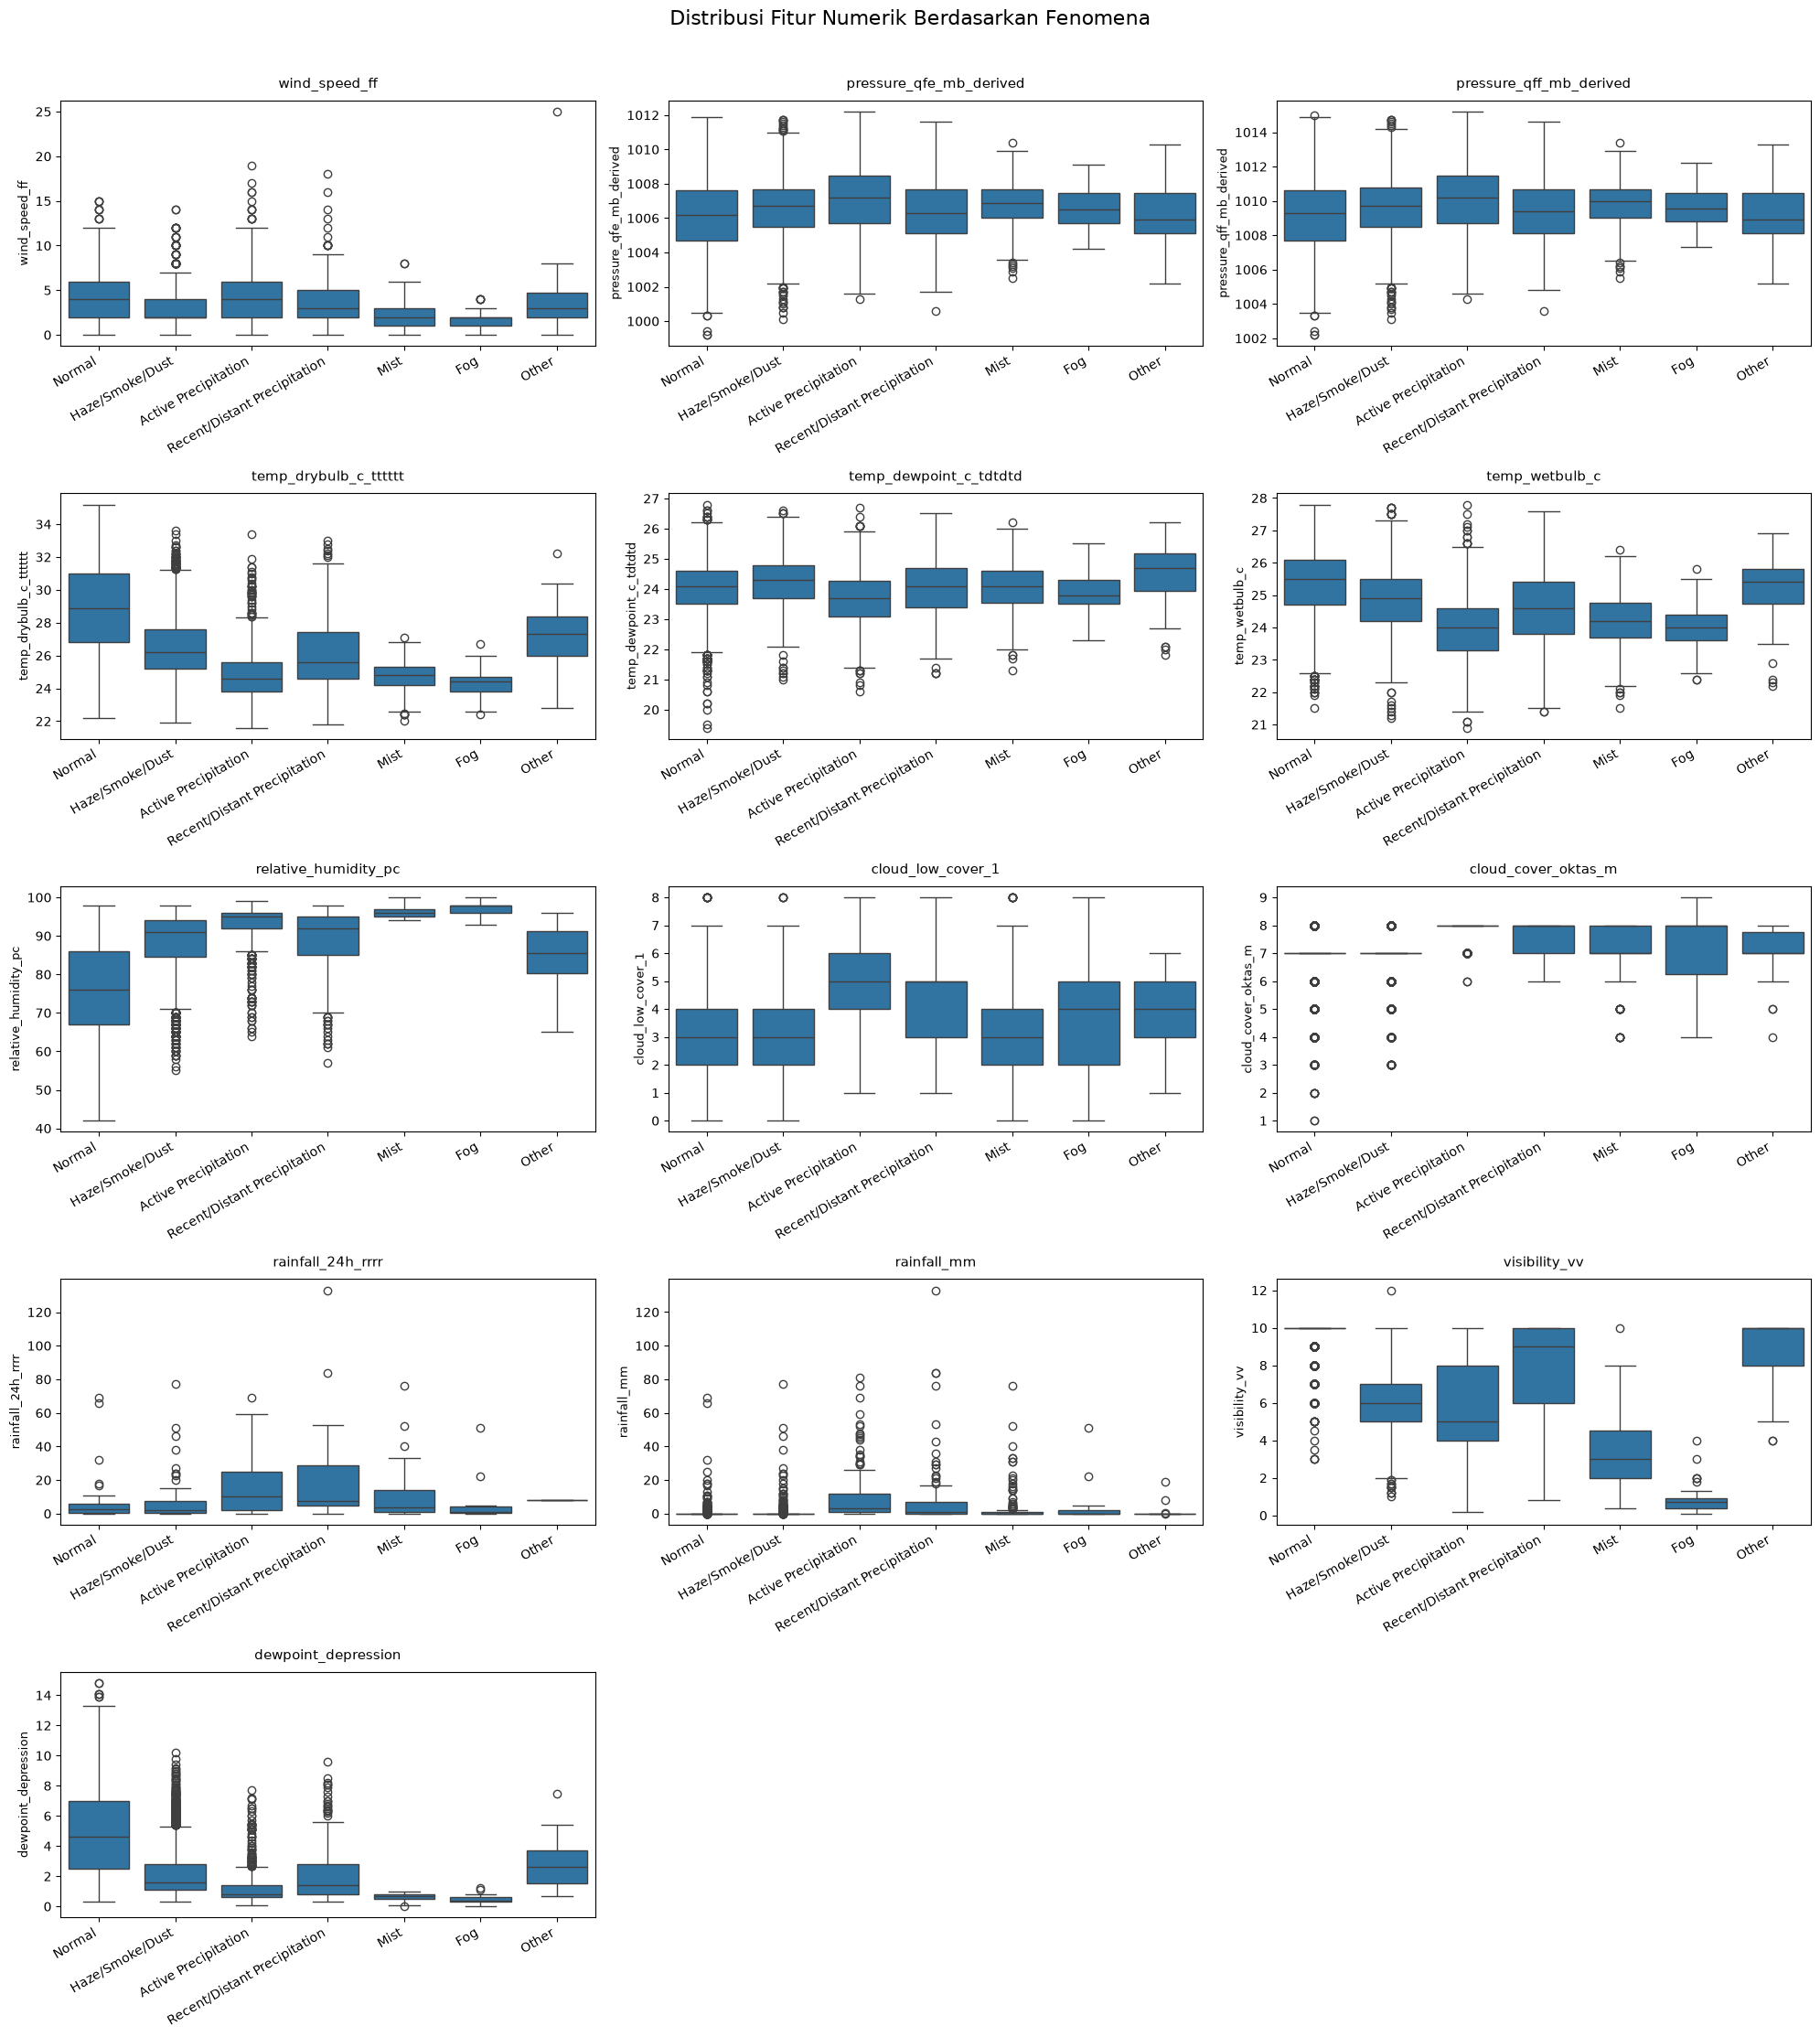

In [35]:
fig, axes = plt.subplots(5, 3, figsize=(20, 22))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(
        data=eda_df,
        x='phenomenon',
        y=col,
        order=eda_df['phenomenon'].value_counts().index,
        ax=ax
    )

    ax.set_title(col, fontsize=11, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=9)
    
    ax.tick_params(axis='x', labelrotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# Menghilangkan subplot yang tidak digunakan
for ax in axes.flatten()[len(num_cols):]:
    ax.remove()

plt.suptitle(
    'Distribusi Fitur Numerik Berdasarkan Fenomena',
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [36]:
results = []

for col in num_cols:
    groups = [
        group[col].dropna().values
        for _, group in eda_df.groupby('phenomenon')
    ]

    stat, p = kruskal(*groups)

    results.append({
        'Feature': col,
        'H-Statistic': stat,
        'P-Value': p,
        'Significant': p < 0.05
    })

kruskal_results = pd.DataFrame(results)

display(
    kruskal_results.style.format({
        'H-Statistic': '{:.2f}',
        'P-Value': '{:.3e}'
    })
)

,Feature,H-Statistic,P-Value,Significant
0,wind_speed_ff,1126.71,3.469e-240,True
1,pressure_qfe_mb_derived,194.53,2.772e-39,True
2,pressure_qff_mb_derived,198.04,4.947e-40,True
3,temp_drybulb_c_tttttt,2713.97,0.000e+00,True
4,temp_dewpoint_c_tdtdtd,350.52,1.192e-72,True
5,temp_wetbulb_c,1421.28,5.974e-304,True
6,relative_humidity_pc,3426.64,0.000e+00,True
7,cloud_low_cover_1,1354.54,1.687e-289,True
8,cloud_cover_oktas_m,1585.34,0.000e+00,True
9,rainfall_24h_rrrr,22.50,9.842e-04,True


In [37]:
for col in num_cols:
    t = eda_df.groupby('phenomenon')[col].agg(
        n='count', min='min',
        q1=lambda x: x.quantile(.25), median='median',
        q3=lambda x: x.quantile(.75), max='max'
    ).round(2)
    print(f'\n{col}')
    print(t.to_string())


wind_speed_ff
                                 n  min   q1  median    q3  max
phenomenon                                                     
Active Precipitation           754    0  2.0     4.0  6.00   19
Fog                             50    0  1.0     2.0  2.00    4
Haze/Smoke/Dust               2643    0  2.0     2.0  4.00   14
Mist                           427    0  1.0     2.0  3.00    8
Normal                        4020    0  2.0     4.0  6.00   15
Other                           50    0  2.0     3.0  4.75   25
Recent/Distant Precipitation   456    0  2.0     3.0  5.00   18

pressure_qfe_mb_derived
                                 n     min      q1  median       q3     max
phenomenon                                                                 
Active Precipitation           754  1001.3  1005.7  1007.2  1008.48  1012.2
Fog                             50  1004.2  1005.7  1006.5  1007.45  1009.1
Haze/Smoke/Dust               2643  1000.1  1005.5  1006.7  1007.70  1011.7
Mist

**Notes:**

- **Visibility, kelembapan relatif, dan dewpoint depression:** Kelas **Fog** dan **Mist** memiliki nilai `visibility_vv` paling rendah (median **0,7 km** dan **3,0 km**) serta `dewpoint_depression` paling sempit (median **0,4 °C** dan **0,7 °C**), yang disertai tingkat kelembapan relatif (`relative_humidity_pc`) paling tinggi (median **98,0%** dan **96,0%**). Kelas **Haze/Smoke/Dust** juga menunjukkan penurunan jarak pandang (median **6,0 km**), sedangkan kelas **Normal** memiliki jarak pandang tinggi (median **10,0 km**) dengan kelembapan relatif yang lebih rendah (median **76,0%**) dan *dewpoint depression* yang lebih lebar (median **4,6 °C**).
- **Suhu udara dan suhu bola basah:** Kelas **Normal** mencatat median suhu udara kering (`temp_drybulb_c_tttttt`) dan suhu bola basah (`temp_wetbulb_c`) paling tinggi (**28,9 °C** dan **25,5 °C**), sedangkan kelas **Fog** (**24,4 °C**), **Active Precipitation** (**24,6 °C**), dan **Mist** (**24,8 °C**) cenderung terjadi pada suhu udara yang lebih rendah.
- **Tutupan awan dan curah hujan:** Kelas **Active Precipitation** menunjukkan tutupan awan rendah (`cloud_low_cover_1`, median **5,0 okta**), tutupan awan total (`cloud_cover_oktas_m`, median **8,0 okta**), serta curah hujan (`rainfall_mm` median **3,0 mm**; `rainfall_24h_rrrr` median **10,0 mm**) yang lebih tinggi dibandingkan kelas lainnya, diikuti oleh kelas **Recent/Distant Precipitation**.
- **Kecepatan angin (`wind_speed_ff`):** Fenomena **Fog**, **Mist**, dan **Haze/Smoke/Dust** cenderung terjadi pada kondisi angin yang lebih tenang (median **2,0**), berbeda dengan kelas **Normal** dan **Active Precipitation** yang memiliki kecepatan angin lebih tinggi (median **4,0**).
- **Tekanan udara dan suhu titik embun:** Variabel `pressure_qfe_mb_derived`, `pressure_qff_mb_derived`, dan `temp_dewpoint_c_tdtdtd` memiliki nilai median yang relatif berdekatan antarkelas (rentang median tekanan QFE hanya berkisar antara **1005,9–1007,2 mb**).

Uji **Kruskal-Wallis** dilakukan untuk mengetahui apakah terdapat perbedaan distribusi yang signifikan secara statistik pada setiap variabel numerik berdasarkan kelas fenomena. Hasil pengujian menunjukkan bahwa seluruh variabel memiliki nilai *p-value* di bawah **0,05**, yang mengindikasikan adanya perbedaan distribusi yang signifikan secara statistik pada setidaknya satu kelas fenomena. Variabel `visibility_vv` memiliki nilai H-statistik tertinggi sebesar **5931,04** (diikuti `relative_humidity_pc` sebesar **3426,64** dan `dewpoint_depression` sebesar **3421,82**), sedangkan `rainfall_24h_rrrr` memiliki nilai terendah sebesar **22,50** (dipengaruhi juga oleh jumlah observasi yang jauh lebih sedikit, $n = 227$). Namun, besarnya nilai H-statistik tidak secara langsung menunjukkan tingkat kepentingan (*feature importance*) suatu fitur dalam model klasifikasi.

Secara keseluruhan, fitur-fitur numerik memiliki pola distribusi yang berbeda antarfenomena—terutama pada jarak pandang, kelembapan, suhu, dan *dewpoint depression*. Meskipun uji Kruskal-Wallis belum mengidentifikasi pasangan kelas spesifik yang berbeda secara signifikan, temuan ini memberikan gambaran awal mengenai daya pembeda setiap fitur untuk tahap pemodelan.

## 2.5 Correlation Between Numeric Feature

Korelasi antar variabel numerik dihitung menggunakan metode Spearman untuk mengetahui kekuatan hubungan antar fitur. Metode ini dipilih karena tidak mengasumsikan hubungan linear dan lebih tahan terhadap nilai ekstrem. Analisis ini bertujuan mengidentifikasi fitur yang saling berkorelasi tinggi (multikolinearitas) sebagai bahan pertimbangan pemilihan fitur. Korelasi hanya dihitung untuk variabel numerik.

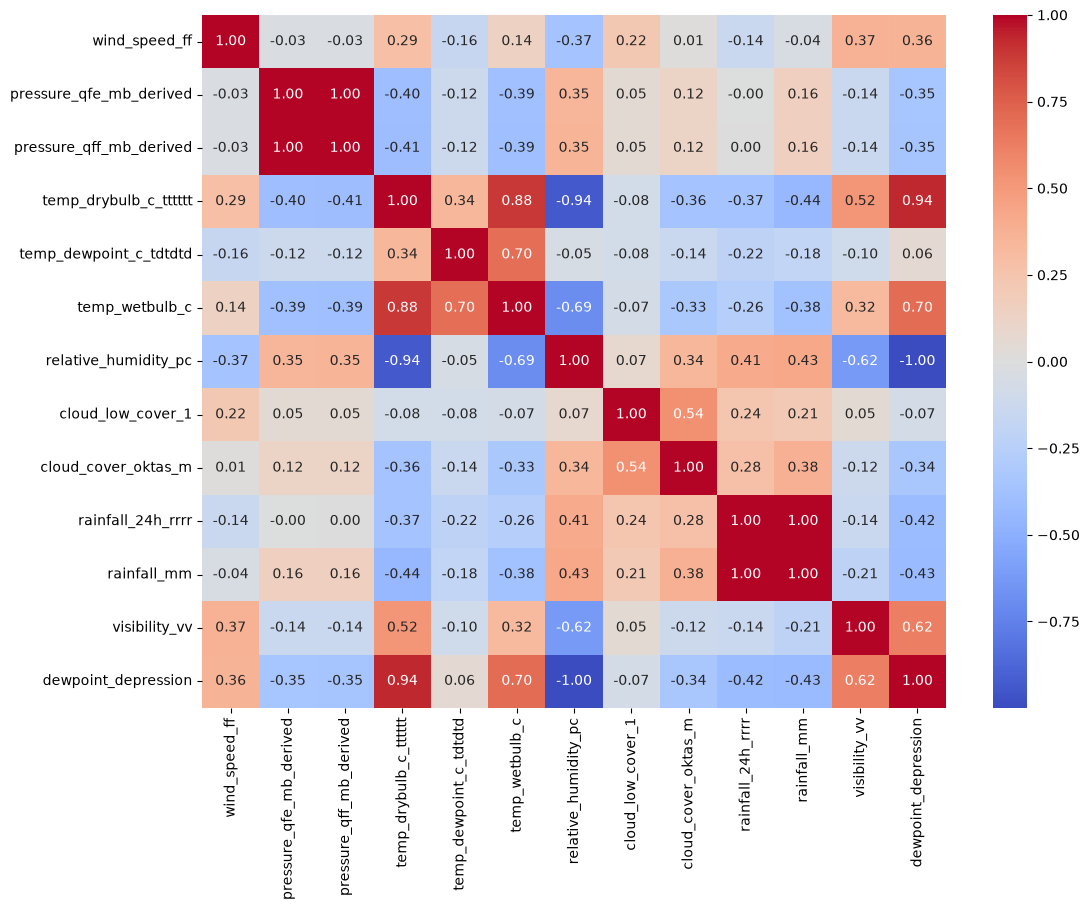

In [38]:
plt.figure(figsize=(12, 9))
sns.heatmap(eda_df[num_cols].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='coolwarm', center=0)
plt.show()

In [39]:
print(eda_df[num_cols].corr(method='spearman').round(2).to_string())

                         wind_speed_ff  pressure_qfe_mb_derived  pressure_qff_mb_derived  temp_drybulb_c_tttttt  temp_dewpoint_c_tdtdtd  temp_wetbulb_c  relative_humidity_pc  cloud_low_cover_1  cloud_cover_oktas_m  rainfall_24h_rrrr  rainfall_mm  visibility_vv  dewpoint_depression
wind_speed_ff                     1.00                    -0.03                    -0.03                   0.29                   -0.16            0.14                 -0.37               0.22                 0.01              -0.14        -0.04           0.37                 0.36
pressure_qfe_mb_derived          -0.03                     1.00                     1.00                  -0.40                   -0.12           -0.39                  0.35               0.05                 0.12              -0.00         0.16          -0.14                -0.35
pressure_qff_mb_derived          -0.03                     1.00                     1.00                  -0.41                   -0.12           -0.39   

**Notes:**

- **Tekanan udara (`pressure_qfe_mb_derived` & `pressure_qff_mb_derived`):** Memiliki korelasi positif sempurna (**1,00**), karena keduanya merepresentasikan pengukuran tekanan atmosfer di stasiun yang sama dengan selisih koreksi ketinggian yang konstan.
- **Suhu udara, titik embun, dan bola basah:** Suhu udara kering (`temp_drybulb_c_tttttt`) berkorelasi positif sangat kuat dengan `dewpoint_depression` (**0,94**) dan suhu bola basah (`temp_wetbulb_c`, **0,88**). Selain itu, `temp_wetbulb_c` juga memiliki korelasi positif kuat dengan suhu titik embun (`temp_dewpoint_c_tdtdtd`, **0,70**) dan `dewpoint_depression` (**0,70**).
- **Kelembapan relatif (`relative_humidity_pc`):** Memiliki korelasi negatif sempurna dengan `dewpoint_depression` (**-1,00**) serta korelasi negatif sangat kuat dengan `temp_drybulb_c_tttttt` (**-0,94**) dan `temp_wetbulb_c` (**-0,69**), yang mencerminkan keterkaitan fisik langsung antara tingkat kejenuhan udara, suhu, dan selisih titik embun.
- **Curah hujan (`rainfall_24h_rrrr` & `rainfall_mm`):** Menunjukkan korelasi positif sempurna (**1,00**). Namun, nilai ini hanya dihitung berdasarkan **209 baris irisan data** (*pairwise non-null*) yang terisi pada kedua variabel secara bersamaan, sehingga belum merepresentasikan keseluruhan 8.400 observasi.
- **Jarak pandang (`visibility_vv`):** Memiliki korelasi positif kuat dengan `dewpoint_depression` (**0,62**) dan korelasi negatif kuat dengan `relative_humidity_pc` (**-0,62**), serta korelasi positif sedang dengan `temp_drybulb_c_tttttt` (**0,52**). Hal ini mengonfirmasi bahwa penurunan jarak pandang berkaitan erat dengan kondisi udara yang lembap dan mendekati titik jenuh.
- **Tutupan awan (`cloud_low_cover_1` & `cloud_cover_oktas_m`):** Memiliki korelasi positif sedang (**0,54**), yang menunjukkan bahwa peningkatan tutupan awan rendah sejalan dengan meningkatnya tutupan awan total.

Berdasarkan hasil korelasi Spearman, terdapat beberapa kelompok variabel numerik yang memiliki hubungan sangat kuat (multikolinearitas), khususnya pada variabel tekanan udara, kelompok suhu–kelembapan–*dewpoint depression*, serta curah hujan. Kondisi ini menunjukkan adanya redundansi informasi antarfitur. Meskipun model berbasis pohon keputusan (*tree-based models*) relatif tidak sensitif terhadap multikolinearitas dari sisi performa prediksi, keberadaan fitur yang sangat redundan tetap perlu dipertimbangkan dalam tahap seleksi fitur karena dapat membagi nilai kepentingan fitur (*feature importance*) dan menambah kompleksitas pemodelan.

## 2.6 Temporal Pattern

Pola temporal fenomena dianalisis berdasarkan jam pengamatan (WIB) dan bulan untuk mengetahui apakah jenis fenomena tertentu cenderung muncul pada waktu tertentu. Proporsi fenomena dihitung per jam dan per bulan agar tidak dipengaruhi perbedaan jumlah observasi pada setiap waktu.

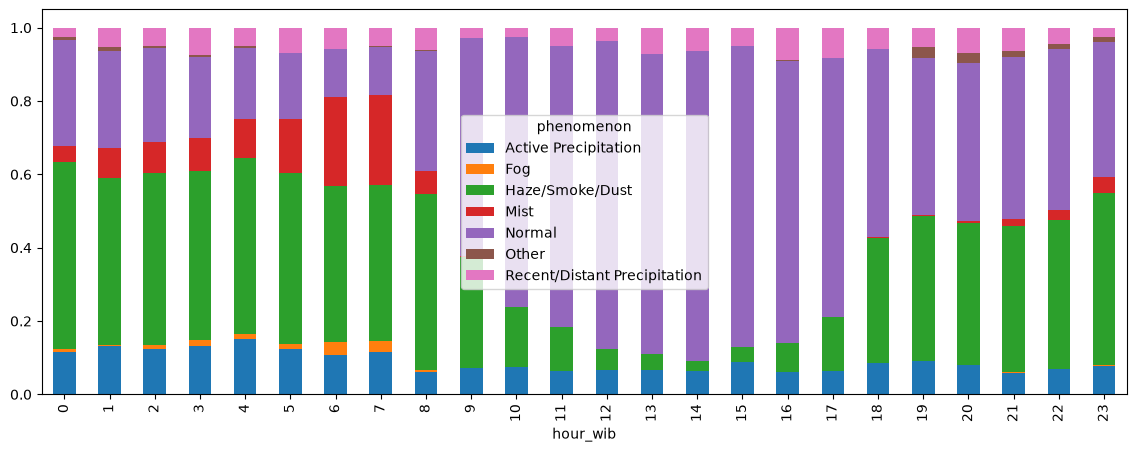

In [40]:
ct_hour = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'], normalize='index')
ct_hour.plot(kind='bar', stacked=True, figsize=(14, 5))
plt.show()

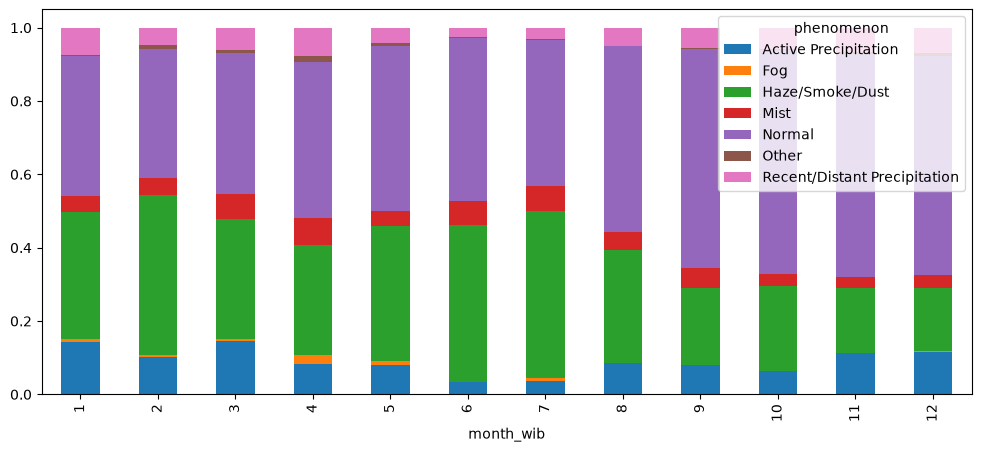

In [41]:
ct_month = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'], normalize='index')
ct_month.plot(kind='bar', stacked=True, figsize=(12, 5))
plt.show()

In [42]:
ct_hour_n = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'])
print((ct_hour_n.div(ct_hour_n.sum(axis=1), axis=0) * 100).round(1).to_string())

ct_month_n = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'])
print((ct_month_n.div(ct_month_n.sum(axis=1), axis=0) * 100).round(1).to_string())

print(ct_hour_n.sum(axis=1).to_string())    # jumlah observasi per jam
print(ct_month_n.sum(axis=1).to_string())   # jumlah observasi per bulan

phenomenon  Active Precipitation  Fog  Haze/Smoke/Dust  Mist  Normal  Other  Recent/Distant Precipitation
hour_wib                                                                                                 
0                           11.7  0.6             51.0   4.6    28.8    0.9                           2.6
1                           13.1  0.3             45.7   8.1    26.5    1.1                           5.3
2                           12.5  1.1             46.7   8.5    25.5    0.6                           5.1
3                           13.1  1.7             46.0   9.1    22.2    0.6                           7.4
4                           15.1  1.4             48.0  10.6    19.3    0.6                           5.0
5                           12.4  1.4             46.5  14.9    18.0    0.0                           6.8
6                           10.7  3.5             42.6  24.3    13.0    0.0                           5.8
7                           11.5  3.1         

**Notes:**

**Berdasarkan jam pengamatan (`hour_wib`):**
- **Fog dan Mist:** Terkonsentrasi pada dini hari hingga pagi hari (`00.00–07.00 WIB`) dengan puncak pada pukul **06.00–07.00 WIB** (`Mist` mencapai **24,3%–24,5%** dan `Fog` **3,1%–3,5%**), lalu hampir tidak muncul pada siang hingga sore hari (`09.00–17.00 WIB`).
- **Haze/Smoke/Dust:** Memiliki proporsi tinggi pada malam hingga pagi hari (`18.00–08.00 WIB`, berkisar **34,1%–51,0%** dengan puncak pada pukul **00.00 WIB**), kemudian menurun drastis pada siang hari hingga titik terendah pada pukul **14.00 WIB (2,6%)**.
- **Normal:** Sangat dominan pada siang hari, khususnya sekitar pukul **10.00–16.00 WIB** (**73,7%–84,5%**, tertinggi pada pukul **14.00 WIB**), dan berada pada proporsi terendah pada pagi hari pukul **06.00–07.00 WIB (13,0%)**.
- **Active Precipitation dan Recent/Distant Precipitation:** `Active Precipitation` memiliki proporsi lebih tinggi pada dini hari hingga pagi (`00.00–07.00 WIB`, berkisar **10,7%–15,1%** dengan puncak pukul **04.00 WIB**) dibandingkan siang hingga malam hari (**5,8%–9,1%**). Sementara itu, `Recent/Distant Precipitation` teramati cukup merata sepanjang hari (**2,6%–8,7%**) dengan proporsi sedikit lebih tinggi pada sore hari (`16.00–17.00 WIB`).
- **Other:** Memiliki proporsi sangat kecil sepanjang hari (**0,0%–3,0%**) dan paling banyak muncul pada malam hari sekitar pukul **19.00–21.00 WIB**.

**Berdasarkan bulan pengamatan (`month_wib`):**
- **Haze/Smoke/Dust:** Memiliki proporsi lebih tinggi pada paruh pertama hingga pertengahan tahun, terutama pada **Juli (45,5%)**, **Februari (43,7%)**, dan **Juni (42,7%)**, kemudian menurun pada periode September–Desember (**17,3%–23,1%**).
- **Normal:** Lebih dominan pada periode **Agustus hingga Desember** (**50,8%–61,1%**), dengan proporsi tertinggi pada **Oktober (61,1%)** dan **November (60,7%)**.
- **Active Precipitation dan Recent/Distant Precipitation:** `Active Precipitation` memiliki proporsi tertinggi pada **Maret (14,5%)** dan **Januari (14,2%)**, diikuti November–Desember (**11,3%–11,6%**), lalu menurun signifikan pada **Juni (3,3%)** dan **Juli (3,7%)**. Pola serupa juga terlihat pada `Recent/Distant Precipitation` yang berada pada titik terendah di bulan Juni–Juli (**2,6%–3,1%**) dan tertinggi pada **April (7,8%)** serta **Januari (7,3%)**.
- **Mist:** Memiliki proporsi relatif lebih tinggi pada **April (7,2%)**, diikuti **Juli (6,9%)**, **Maret (6,6%)**, dan **Juni (6,6%)**.
- **Fog dan Other:** Tetap memiliki proporsi kecil sepanjang tahun, dengan kemunculan tertinggi keduanya pada **April** (`Fog` sebesar **2,3%** dan `Other` sebesar **1,6%**).

Secara keseluruhan, analisis pola temporal menunjukkan bahwa kemunculan fenomena cuaca memiliki variasi diurnal (harian) yang sangat jelas—seperti dominasi `Fog` dan `Mist` pada dini hari hingga pagi serta dominasi `Normal` pada siang hari—sehingga informasi waktu pengamatan berpotensi menjadi fitur yang informatif dalam pemodelan. Sementara itu, pola bulanan yang teramati masih didasarkan pada satu tahun periode data sehingga belum cukup untuk menyimpulkan pola musiman jangka panjang. Selain itu, jumlah observasi per jam terdistribusi relatif merata (**340–361 data** per jam), sedangkan pada skala bulanan jumlah observasi paling sedikit tercatat pada **Desember (611 data)** dan **Februari (666 data)**.

## 2.7 Label Origin Check

Pemeriksaan dilakukan untuk melihat hubungan antara phenomenon dengan `ix_flag` dan `weather_code_ww`, karena label fenomena dibentuk berdasarkan hasil decoding kedua kolom tersebut. Hasil pemeriksaan ini menjadi dasar pertimbangan untuk tidak menggunakan keduanya sebagai fitur model guna menghindari kebocoran informasi (data leakage).

In [43]:
print(pd.crosstab(eda_df['phenomenon'], eda_df['ix_flag']))

ix_flag                          1     2
phenomenon                              
Active Precipitation           754     0
Fog                             50     0
Haze/Smoke/Dust               2643     0
Mist                           427     0
Normal                         188  3832
Other                           50     0
Recent/Distant Precipitation   456     0


In [44]:
print(pd.crosstab(eda_df['phenomenon'], eda_df['weather_code_ww'].isna()))

weather_code_ww               False  True 
phenomenon                                
Active Precipitation            754      0
Fog                              50      0
Haze/Smoke/Dust                2643      0
Mist                            427      0
Normal                          188   3832
Other                            50      0
Recent/Distant Precipitation    456      0


**Notes:**

- **`ix_flag`:** Memiliki keterkaitan langsung dengan label `phenomenon`. Seluruh observasi pada kelas selain **Normal** tercatat dengan nilai `ix_flag = 1` (indikator bahwa kelompok cuaca dilaporkan), sedangkan kelas **Normal** didominasi oleh nilai `ix_flag = 2` sebanyak **3.832 data (95,3%)** dan hanya **188 data (4,7%)** yang bernilai `ix_flag = 1`.
- **`weather_code_ww`:** Menunjukkan pola kelengkapan yang identik dengan `ix_flag`. Seluruh observasi pada kelas selain **Normal** memiliki nilai kode cuaca (`isna = False`), sedangkan pada kelas **Normal** sebanyak **3.832 data (95,3%)** tidak memiliki kode cuaca (`isna = True`) dan hanya **188 data (4,7%)** yang memiliki kode cuaca (kode cuaca non-signifikan yang dipetakan ke kategori **Normal**).
- **Implikasi Pemodelan:** Karena kedua variabel ini merupakan dasar pembentukan label target `phenomenon`, keduanya harus dikeluarkan dari daftar fitur prediktor pada tahap pemodelan untuk mencegah terjadinya kebocoran informasi (*data leakage*).

# 3. Preprocessing

Tahap ini melakukan pembersihan dan transformasi data berdasarkan seluruh temuan dari tahap Inspection dan EDA sebelumnya, agar data siap digunakan untuk pemodelan. Seluruh proses dilakukan pada salinan data (`clean_df`), sehingga data_df asli tetap terjaga sebagai referensi mentah.

## 3.1 Create Working Copy

Salinan dataset dibuat untuk diproses sehingga data mentah (`data_df`) tetap tersimpan sebagai referensi.

In [45]:
clean_df = data_df.copy()
clean_df.head()

,station_name,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,...,cloud_cover_oktas_m,rainfall_24h_rrrr,rainfall_mm,rainfall_period_h,ix_flag,phenomenon,weather_code_ww,visibility_vv,report_type,raw_synop
0,Stasiun Meteorologi Sultan Thaha,2025-01-01 00:00:00,300,5,1006.8,1009.8,25.8,24.8,25.1,94,...,7,NaN,0.0,NaN,1,Haze/Smoke/Dust,5.0,7.0,SM,AAXX 01004 96195 31457 73005 10258 20248 30068...
1,Stasiun Meteorologi Sultan Thaha,2025-01-01 01:00:00,310,9,1007.6,1010.6,26.7,24.8,25.3,89,...,7,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01014 96195 42460 73109 10267 20248 30076...
2,Stasiun Meteorologi Sultan Thaha,2025-01-01 02:00:00,310,8,1008.0,1011.0,28.0,24.8,25.6,83,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01024 96195 42460 63108 10280 20248 30080...
3,Stasiun Meteorologi Sultan Thaha,2025-01-01 03:00:00,350,10,1007.9,1010.9,29.5,24.5,25.8,75,...,6,NaN,0.0,NaN,2,Normal,NaN,10.0,SI,AAXX 01034 96195 32460 63510 10295 20245 30079...
4,Stasiun Meteorologi Sultan Thaha,2025-01-01 04:00:00,330,10,1007.3,1010.3,30.6,24.4,26.1,70,...,6,NaN,NaN,NaN,2,Normal,NaN,10.0,SN,AAXX 01044 96195 42460 63310 10306 20244 30073...


## 3.2 Fix Data Structure

Kolom `data_timestamp` dikonversi ke tipe datetime sesuai temuan pada tahap Inspection.

In [46]:
clean_df['data_timestamp'] = pd.to_datetime(clean_df['data_timestamp'], errors='coerce')
print(clean_df['data_timestamp'].dtypes)

datetime64[us]


## 3.3 Drop Unused Columns

Kolom yang tidak digunakan sebagai fitur dihapus:
- `weather_code_ww` dan `ix_flag` dihapus karena menjadi dasar pembentukan label phenomenon
- `pressure_qfe_mb_derived` dihapus karena berkorelasi 1,00 dengan `pressure_qff_mb_derived`
- `rainfall_24h_rrrr` dan `rainfall_period_h` dihapus karena lebih dari 97% dan 93% nilainya kosong
- `station_name`, `report_type`, dan `raw_synop` merupakan informasi identitas dan data mentah yang tidak relevan sebagai fitur

In [47]:
clean_df.columns

Index(['station_name', 'data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qfe_mb_derived', 'pressure_qff_mb_derived',
       'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c',
       'relative_humidity_pc', 'cloud_low_cover_1', 'cloud_cover_oktas_m',
       'rainfall_24h_rrrr', 'rainfall_mm', 'rainfall_period_h', 'ix_flag',
       'phenomenon', 'weather_code_ww', 'visibility_vv', 'report_type',
       'raw_synop'],
      dtype='str')

In [48]:
drop_cols = ['station_name', 'weather_code_ww', 'ix_flag', 'pressure_qfe_mb_derived',
             'rainfall_24h_rrrr', 'rainfall_period_h', 'report_type', 'raw_synop']

clean_df.drop(columns=drop_cols, inplace=True)
clean_df.columns

Index(['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt',
       'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc',
       'cloud_low_cover_1', 'cloud_cover_oktas_m', 'rainfall_mm', 'phenomenon',
       'visibility_vv'],
      dtype='str')

## 3.4 Check Outlier Candidates

Dua nilai yang tampak tidak biasa pada tahap Inspection dan EDA diperiksa kembali pada data sumber, yaitu kecepatan angin 25 dan visibility 12,0, untuk menentukan apakah nilai tersebut valid

In [49]:
print(clean_df.loc[clean_df['wind_speed_ff'] == 25, ['data_timestamp', 'phenomenon']])
print(data_df.loc[clean_df['wind_speed_ff'] == 25, 'raw_synop'].values)

print(clean_df.loc[clean_df['visibility_vv'] == 12, ['data_timestamp', 'phenomenon']])
print(data_df.loc[clean_df['visibility_vv'] == 12, 'raw_synop'].values)

          data_timestamp phenomenon
3368 2025-05-24 13:00:00      Other
<ArrowStringArray>
['AAXX 24134 96195 41460 72725 10287 20233 30056 40086 71322 81922 333 56000 57905 81912 84613 85460 80970=']
Length: 1, dtype: str
     data_timestamp       phenomenon
6230     2025-09-25  Haze/Smoke/Dust
<ArrowStringArray>
['AAXX 25004 96195 31462 61502 10244 20233 30076 40105 53011 70522 83571 333 20240 50420 55105 56000 58003 83613 84460=']
Length: 1, dtype: str


**Notes:**

- **Kecepatan angin (`wind_speed_ff = 25`):** Ditemukan pada observasi **24 Mei 2025 pukul 13.00 UTC** (kelas **Other**). Berdasarkan pemeriksaan sandi SYNOP mentah (`AAXX 24134 ... 72725`), kelompok `72725` secara eksplisit mencatat nilai kecepatan angin `ff = 25`. Dengan indikator satuan `iw = 4` pada kelompok waktu `24134`, nilai tersebut terkonfirmasi dalam satuan **knot** dan sesuai dengan laporan kondisi atmosfer saat itu (`ww = 13`, kilat terlihat), sehingga bukan merupakan kesalahan pembacaan maupun konversi satuan.
- **Jarak pandang (`visibility_vv = 12,0`):** Ditemukan pada observasi **25 September 2025 pukul 00.00 UTC** (kelas **Haze/Smoke/Dust**). Berdasarkan pemeriksaan sandi SYNOP mentah (`AAXX 25004 ... 31462`), kelompok `31462` memuat kode jarak pandang `VV = 62`. Sesuai aturan tabel kode WMO (`VV - 50` untuk rentang kode 56–80), nilai tersebut memang merepresentasikan jarak pandang sebesar **12 km**, sehingga hasil *decoding* sudah akurat mengikuti data sumber meskipun tercatat bersamaan dengan kode kabut asap (`ww = 05`).
- **Keputusan Penanganan:** Karena kedua nilai ekstrem tersebut terbukti berasal langsung dari pencatatan asli pada sandi SYNOP (bukan akibat kesalahan *scraping* maupun *decoding*), keduanya dinyatakan valid dan tetap dipertahankan dalam dataset.

## 3.5 Handle Missing Values

Menangani nilai hilang pada variabel yang teridentifikasi memiliki missing value. Hanya dua kolom yang masih punya missing value setelah penghapusan, yaitu `cloud_low_cover_1` (4 baris) dan `rainfall_mm` (5.738 baris)

`cloud_low_cover_1`

In [50]:
clean_df.loc[clean_df['cloud_low_cover_1'].isna(), ['phenomenon', 'cloud_cover_oktas_m', 'visibility_vv']]

,phenomenon,cloud_cover_oktas_m,visibility_vv
2813,Fog,9,0.2
2814,Fog,9,0.2
2815,Fog,9,0.2
3681,Mist,7,3.6


In [51]:
idx_nan = clean_df[clean_df['cloud_low_cover_1'].isna()].index
idx_before = idx_nan - 1
idx_after = idx_nan + 1
idx_all = idx_nan.union(idx_before).union(idx_after).sort_values()

clean_df.loc[idx_all, ['data_timestamp', 'cloud_low_cover_1', 'phenomenon', 'cloud_cover_oktas_m', 'visibility_vv']]

,data_timestamp,cloud_low_cover_1,phenomenon,cloud_cover_oktas_m,visibility_vv
2812,2025-04-30 19:00:00,4.0,Fog,8,1.0
2813,2025-04-30 20:00:00,NaN,Fog,9,0.2
2814,2025-04-30 21:00:00,NaN,Fog,9,0.2
2815,2025-04-30 22:00:00,NaN,Fog,9,0.2
2816,2025-04-30 23:00:00,2.0,Fog,6,0.2
3680,2025-06-06 22:00:00,1.0,Normal,7,9.0
3681,2025-06-07 00:00:00,NaN,Mist,7,3.6
3682,2025-06-07 01:00:00,1.0,Haze/Smoke/Dust,4,7.0


In [52]:
clean_df['cloud_low_cover_1'] = clean_df['cloud_low_cover_1'].ffill()
print(clean_df['cloud_low_cover_1'].isna().sum())

0


`rainfall_mm`

In [53]:
print(((data_df['rainfall_mm'] > 0) == data_df['rainfall_period_h'].notna()).mean())

hr = clean_df['data_timestamp'].dt.hour
print(pd.crosstab(hr, data_df['rainfall_period_h']))
print(data_df.loc[data_df['rainfall_mm'] == 0, 'rainfall_period_h'].notna().sum())

1.0
rainfall_period_h  6.0   24.0
data_timestamp               
0                     0   227
6                    93     0
12                  114     0
18                  101     0
0


In [54]:
clean_df = clean_df.drop(columns=['rainfall_mm'])

In [55]:
clean_df.head()

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,phenomenon,visibility_vv
0,2025-01-01 00:00:00,300,5,1009.8,25.8,24.8,25.1,94,3.0,7,Haze/Smoke/Dust,7.0
1,2025-01-01 01:00:00,310,9,1010.6,26.7,24.8,25.3,89,4.0,7,Normal,10.0
2,2025-01-01 02:00:00,310,8,1011.0,28.0,24.8,25.6,83,3.0,6,Normal,10.0
3,2025-01-01 03:00:00,350,10,1010.9,29.5,24.5,25.8,75,4.0,6,Normal,10.0
4,2025-01-01 04:00:00,330,10,1010.3,30.6,24.4,26.1,70,4.0,6,Normal,10.0


## 3.5 Finalize Data Types

Mengonversi kembali kolom yang sempat bertipe float akibat adanya missing value menjadi integer, setelah seluruh nilai hilang berhasil ditangani pada tahap sebelumnya.

In [56]:
print((clean_df['cloud_low_cover_1'] % 1 == 0).all())
print((clean_df['cloud_cover_oktas_m'] % 1 == 0).all())

True
True


In [57]:
clean_df['cloud_low_cover_1'] = clean_df['cloud_low_cover_1'].astype('int8')
clean_df['cloud_cover_oktas_m'] = clean_df['cloud_cover_oktas_m'].astype('int8')

In [58]:
clean_df[['cloud_low_cover_1', 'cloud_cover_oktas_m']].dtypes

cloud_low_cover_1      int8
cloud_cover_oktas_m    int8
dtype: object

In [59]:
clean_df[['cloud_low_cover_1', 'cloud_cover_oktas_m']].head(5)

,cloud_low_cover_1,cloud_cover_oktas_m
0,3,7
1,4,7
2,3,6
3,4,6
4,4,6


## 3.6 Convert Timestamp to Local Time (WIB)

Mengonversi `data_timestamp` dari UTC ke WIB (UTC+7), agar analisis dan fitur berbasis waktu selanjutnya konsisten dengan pola diurnal visibility yang telah diidentifikasi pada tahap EDA.

In [60]:
date_position = clean_df.columns.get_loc('data_timestamp') + 1
clean_df.insert(date_position, 'datetime_wib', clean_df['data_timestamp'] + pd.Timedelta(hours=7))

In [61]:
clean_df[['data_timestamp', 'datetime_wib']].head(5)

,data_timestamp,datetime_wib
0,2025-01-01 00:00:00,2025-01-01 07:00:00
1,2025-01-01 01:00:00,2025-01-01 08:00:00
2,2025-01-01 02:00:00,2025-01-01 09:00:00
3,2025-01-01 03:00:00,2025-01-01 10:00:00
4,2025-01-01 04:00:00,2025-01-01 11:00:00


In [62]:
print('first date: ', clean_df['datetime_wib'].min())
print('last date: ', clean_df['datetime_wib'].max())

first date:  2025-01-01 07:00:00
last date:  2026-01-01 06:00:00


In [63]:
clean_df.columns

Index(['data_timestamp', 'datetime_wib', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt',
       'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc',
       'cloud_low_cover_1', 'cloud_cover_oktas_m', 'phenomenon',
       'visibility_vv'],
      dtype='str')

In [64]:
clean_df.head(5)

,data_timestamp,datetime_wib,wind_dir_deg_dd,wind_speed_ff,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,phenomenon,visibility_vv
0,2025-01-01 00:00:00,2025-01-01 07:00:00,300,5,1009.8,25.8,24.8,25.1,94,3,7,Haze/Smoke/Dust,7.0
1,2025-01-01 01:00:00,2025-01-01 08:00:00,310,9,1010.6,26.7,24.8,25.3,89,4,7,Normal,10.0
2,2025-01-01 02:00:00,2025-01-01 09:00:00,310,8,1011.0,28.0,24.8,25.6,83,3,6,Normal,10.0
3,2025-01-01 03:00:00,2025-01-01 10:00:00,350,10,1010.9,29.5,24.5,25.8,75,4,6,Normal,10.0
4,2025-01-01 04:00:00,2025-01-01 11:00:00,330,10,1010.3,30.6,24.4,26.1,70,4,6,Normal,10.0


# 4. Feature Engineering

Tahap feature engineering dilakukan dengan membentuk variabel baru dari data yang telah dibersihkan. Pembentukan fitur ini didasarkan pada karakteristik data dan pola yang ditemukan pada tahap EDA, dengan tujuan membantu model mengenali pola yang berkaitan dengan masing-masing fenomena meteorologi.

## 4.1 Dewpoint Depression

Menghitung selisih antara suhu udara dan titik embun `(temp_drybulb_c_tttttt - temp_dewpoint_c_tdtdtd)`, untuk merangkum informasi suhu dan kelembapan secara lebih ringkas

**Dew point depression**, yaitu <u>*selisih antara suhu udara dan titik embun*</u>, merupakan indikator penting dalam mengidentifikasi potensi pembentukan kabut. Semakin kecil nilai selisih ini, semakin dekat kondisi udara terhadap titik saturasi, yang meningkatkan kemungkinan terbentuknya kabut atau penurunan visibility.

**Dew point** (titik embun) itu suhu di mana udara harus didinginkan sampai jadi **jenuh/saturated** (kelembapan relatif = 100%), sampai uap air mulai mengembun jadi titik-titik air (contoh: embun di rumput pagi hari, atau kabut).

Jadi **dew point depression** itu ngukur **seberapa "jauh" suhu udara saat ini dari titik jenuhnya**:
- **Depression kecil** (temp dan dew point deket) → udara hampir jenuh, kelembapan tinggi, kondisi mendekati pembentukan kabut/embun
- **Depression besar** (temp dan dew point jauh) → udara masih jauh dari jenuh, kelembapan relatif rendah, kecil kemungkinan kabut

```
Temp = 25°C, Dew Point = 24°C  →  Depression = 1°C   (udara SANGAT lembap, dekat titik jenuh)
Temp = 30°C, Dew Point = 15°C  →  Depression = 15°C  (udara kering, jauh dari jenuh)
```

In [65]:
dew_dep_position = clean_df.columns.get_loc('temp_dewpoint_c_tdtdtd') + 1
clean_df.insert(dew_dep_position, 'dewpoint_depression', clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_dewpoint_c_tdtdtd'])

In [66]:
clean_df[['temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'dewpoint_depression']].head(5)

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression
0,25.8,24.8,1.0
1,26.7,24.8,1.9
2,28.0,24.8,3.2
3,29.5,24.5,5.0
4,30.6,24.4,6.2


In [67]:
clean_df['dewpoint_depression'].describe()

count    8400.000000
mean        3.314071
std         2.650389
min         0.000000
25%         1.100000
50%         2.400000
75%         5.100000
max        14.800000
Name: dewpoint_depression, dtype: float64

## 4.2 Cyclical Time Encoding

Mengonversi jam dan bulan menjadi representasi sin dan cos, agar model dapat menangkap sifat siklis waktu (misalnya jam 23:00 dekat dengan jam 00:00).

**Ekstraksi Fitur Waktu Dasar**

In [68]:
position = clean_df.columns.get_loc('datetime_wib') + 1
clean_df.insert(position, 'hour', clean_df['datetime_wib'].dt.hour)

**Cyclic Encoding for Hour (Periode 24 Jam)**

In [69]:
position = clean_df.columns.get_loc('hour') + 1
clean_df.insert(position, 'hour_sin', np.sin(2 * np.pi * clean_df['hour'] / 24))
position = clean_df.columns.get_loc('hour') + 2
clean_df.insert(position, 'hour_cos', np.cos(2 * np.pi * clean_df['hour'] / 24))

In [70]:
time = clean_df[['datetime_wib', 'hour', 'hour_sin', 'hour_cos']]

In [71]:
time.isna().sum()

datetime_wib    0
hour            0
hour_sin        0
hour_cos        0
dtype: int64

In [72]:
time.head(5)

,datetime_wib,hour,hour_sin,hour_cos
0,2025-01-01 07:00:00,7,0.965926,-0.258819
1,2025-01-01 08:00:00,8,0.866025,-0.500000
2,2025-01-01 09:00:00,9,0.707107,-0.707107
3,2025-01-01 10:00:00,10,0.500000,-0.866025
4,2025-01-01 11:00:00,11,0.258819,-0.965926


## 4.3 Wind Direction Encoding (Sin/Cos)

Mengonversi `wind_dir_deg_dd` menjadi representasi sin dan cos, karena arah angin bersifat sirkular (0° dan 360° merepresentasikan arah yang sama) sehingga tidak bisa diperlakukan sebagai nilai linear biasa.

In [73]:
position = clean_df.columns.get_loc('wind_dir_deg_dd') + 1
clean_df.insert(position, 'wind_dir_sin', np.sin(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [74]:
position = clean_df.columns.get_loc('wind_dir_deg_dd') + 2
clean_df.insert(position, 'wind_dir_cos', np.cos(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [75]:
wind_direction = clean_df[['wind_dir_deg_dd', 'wind_dir_sin', 'wind_dir_cos']]

In [76]:
wind_direction.isna().sum()

wind_dir_deg_dd    0
wind_dir_sin       0
wind_dir_cos       0
dtype: int64

In [77]:
wind_direction.head(5)

,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos
0,300,-0.866025,0.500000
1,310,-0.766044,0.642788
2,310,-0.766044,0.642788
3,350,-0.173648,0.984808
4,330,-0.500000,0.866025


In [78]:
clean_df.loc[clean_df['wind_speed_ff'] == 0, 'wind_dir_deg_dd'].value_counts(dropna=False)

wind_dir_deg_dd
0    407
Name: count, dtype: int64

## 4.4 Calm Wind Flag

Fitur `is_calm` dibuat untuk menandai kondisi angin tenang (calm wind) berdasarkan kecepatan angin. Fitur ini menggunakan nilai biner, yaitu 1 untuk menunjukkan kondisi angin tenang ketika kecepatan angin bernilai 0, dan 0 untuk menunjukkan kondisi selain angin tenang. Penambahan fitur ini bertujuan memberikan informasi eksplisit kepada model mengenai kondisi angin tenang.

In [79]:
position = clean_df.columns.get_loc('wind_speed_ff') + 1
clean_df.insert(position, 'is_calm', (clean_df['wind_speed_ff'] == 0).astype(int))

In [80]:
clean_df['is_calm'].value_counts()

is_calm
0    7993
1     407
Name: count, dtype: int64

## 4.5 Feature Engineering Validation

Tahap ini dilakukan untuk memeriksa hasil pembentukan fitur baru guna memastikan bahwa perhitungan telah dilakukan dengan benar, nilai yang dihasilkan berada dalam rentang yang sesuai, serta tidak terdapat missing value yang muncul akibat proses feature engineering.

In [81]:
engineered_features = ['dewpoint_depression', 'wind_dir_sin', 'wind_dir_cos', 'hour_sin', 'hour_cos', 'is_calm']
clean_df[engineered_features].isna().sum()

dewpoint_depression    0
wind_dir_sin           0
wind_dir_cos           0
hour_sin               0
hour_cos               0
is_calm                0
dtype: int64

In [82]:
clean_df[engineered_features].describe()

,dewpoint_depression,wind_dir_sin,wind_dir_cos,hour_sin,hour_cos,is_calm
count,8400.000000,8.400000e+03,8400.000000,8.400000e+03,8.400000e+03,8400.000000
mean,3.314071,2.939103e-02,-0.045620,1.052519e-03,2.635368e-03,0.048452
std,2.650389,6.501619e-01,0.757934,7.073442e-01,7.069478e-01,0.214733
min,0.000000,-1.000000e+00,-1.000000,-1.000000e+00,-1.000000e+00,0.000000
25%,1.100000,-6.427876e-01,-0.766044,-7.071068e-01,-7.071068e-01,0.000000
50%,2.400000,1.224647e-16,-0.173648,1.224647e-16,6.123234e-17,0.000000
75%,5.100000,6.427876e-01,0.766044,7.071068e-01,7.071068e-01,0.000000
max,14.800000,1.000000e+00,1.000000,1.000000e+00,1.000000e+00,1.000000


In [83]:
clean_df.head(10)

,data_timestamp,datetime_wib,hour,hour_sin,hour_cos,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos,wind_speed_ff,is_calm,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,phenomenon,visibility_vv
0,2025-01-01 00:00:00,2025-01-01 07:00:00,7,9.659258e-01,-0.258819,300,-0.866025,0.500000,5,0,1009.8,25.8,24.8,1.0,25.1,94,3,7,Haze/Smoke/Dust,7.0
1,2025-01-01 01:00:00,2025-01-01 08:00:00,8,8.660254e-01,-0.500000,310,-0.766044,0.642788,9,0,1010.6,26.7,24.8,1.9,25.3,89,4,7,Normal,10.0
2,2025-01-01 02:00:00,2025-01-01 09:00:00,9,7.071068e-01,-0.707107,310,-0.766044,0.642788,8,0,1011.0,28.0,24.8,3.2,25.6,83,3,6,Normal,10.0
3,2025-01-01 03:00:00,2025-01-01 10:00:00,10,5.000000e-01,-0.866025,350,-0.173648,0.984808,10,0,1010.9,29.5,24.5,5.0,25.8,75,4,6,Normal,10.0
4,2025-01-01 04:00:00,2025-01-01 11:00:00,11,2.588190e-01,-0.965926,330,-0.500000,0.866025,10,0,1010.3,30.6,24.4,6.2,26.1,70,4,6,Normal,10.0
5,2025-01-01 05:00:00,2025-01-01 12:00:00,12,1.224647e-16,-1.000000,10,0.173648,0.984808,8,0,1009.9,29.8,24.5,5.3,25.9,73,5,7,Normal,10.0
6,2025-01-01 06:00:00,2025-01-01 13:00:00,13,-2.588190e-01,-0.965926,320,-0.642788,0.766044,7,0,1008.9,29.5,24.2,5.3,25.6,73,4,7,Normal,10.0
7,2025-01-01 07:00:00,2025-01-01 14:00:00,14,-5.000000e-01,-0.866025,330,-0.500000,0.866025,4,0,1007.8,30.0,24.6,5.4,26.0,73,3,7,Normal,10.0
8,2025-01-01 08:00:00,2025-01-01 15:00:00,15,-7.071068e-01,-0.707107,310,-0.766044,0.642788,2,0,1007.0,30.2,24.8,5.4,26.2,73,4,7,Haze/Smoke/Dust,8.0
9,2025-01-01 09:00:00,2025-01-01 16:00:00,16,-8.660254e-01,-0.500000,80,0.984808,0.173648,4,0,1007.0,29.8,25.0,4.8,26.3,75,4,7,Normal,10.0


**Notes:**

- **Kelengkapan data:** Seluruh fitur baru (`dewpoint_depression`, `wind_dir_sin`, `wind_dir_cos`, `hour_sin`, `hour_cos`, dan `is_calm`) berhasil dibentuk pada seluruh **8.400 baris data** tanpa menghasilkan *missing value* (`NaN = 0`).
- **Konsistensi perhitungan:** Pemeriksaan pada 10 baris pertama menunjukkan hasil transformasi sudah sesuai dengan rumus—misalnya pada observasi pertama (`hour = 7`, arah angin `300°`, suhu udara `25,8 °C`, dan titik embun `24,8 °C`) menghasilkan `hour_sin = 0,97`, `hour_cos = -0,26`, `wind_dir_sin = -0,87`, `wind_dir_cos = 0,50`, serta `dewpoint_depression = 1,0 °C`.
- **`dewpoint_depression`:** Memiliki rentang nilai antara **0,0 hingga 14,8 °C** (rata-rata **3,31 °C**, median **2,40 °C**), tanpa nilai negatif yang menandakan suhu titik embun tidak pernah melebihi suhu udara kering.
- **Fitur siklikal (`wind_dir_sin`, `wind_dir_cos`, `hour_sin`, `hour_cos`):** Seluruh hasil transformasi trigonometri berada tepat pada rentang **-1 hingga 1**.
- **`is_calm`:** Bernilai biner (**0** dan **1**) untuk menandai kondisi angin tenang (*calm*), dengan proporsi sekitar **4,85%** dari total observasi (`mean = 0,048`).

# 5. Label Definition

Tahap ini menetapkan variabel target yang akan diprediksi oleh model, yaitu `phenomenon`. Berbeda dengan pendekatan sebelumnya yang membentuk kelas dari ambang batas visibility, variabel target pada tahap ini sudah berupa kategori hasil pengamatan, sehingga tidak diperlukan penentuan ambang batas baru. Tahap ini berfokus pada peninjauan distribusi kelas dan pengubahan label ke bentuk numerik agar dapat diproses oleh algoritma.

## 5.1 Target Class Review

Meninjau jumlah dan proporsi setiap kelas pada `phenomenon`. Peninjauan ini diperlukan untuk mengetahui tingkat ketidakseimbangan kelas serta mengidentifikasi kelas dengan jumlah data yang sangat sedikit, karena kelas semacam ini dapat sulit dipelajari oleh model dan berisiko tidak terwakili pada data uji setelah pembagian data berbasis waktu.

In [84]:
clean_df['phenomenon'].value_counts()

phenomenon
Normal                          4020
Haze/Smoke/Dust                 2643
Active Precipitation             754
Recent/Distant Precipitation     456
Mist                             427
Fog                               50
Other                             50
Name: count, dtype: int64

**Notes:**

Distribusi kelas target `phenomenon` dari total **8.400 observasi** menunjukkan ketidakseimbangan jumlah data (*class imbalance*) yang cukup signifikan. Kelas **Normal** memiliki jumlah observasi terbanyak, yaitu **4.020 data (47,9%)**, diikuti oleh **Haze/Smoke/Dust** sebanyak **2.643 data (31,5%)**. Sebaliknya, kelas **Fog** dan **Other** memiliki jumlah observasi paling sedikit, masing-masing hanya **50 data (sekitar 0,6%)**.

Kondisi ini perlu menjadi perhatian utama pada tahap pembagian data berbasis waktu (*time-based split*), pemodelan, dan evaluasi. Selain membuat model berpotensi lebih sulit mengenali kelas minoritas, jumlah sampel yang sangat kecil pada kelas **Fog** dan **Other** juga berisiko menyebabkan keterwakilan yang sangat minim pada bagian data uji.

## 5.2 Encode Target Label

Mengubah label kategori pada `phenomenon` menjadi bilangan bulat menggunakan pemetaan (label_map) yang didefinisikan secara eksplisit. Pemetaan dibuat secara manual agar urutan kode setiap kelas terdokumentasi dengan jelas dan dapat digunakan kembali, misalnya saat menampilkan hasil prediksi dalam bentuk nama fenomena. Proses ini hanya berupa pemetaan tetap yang tidak mempelajari pola dari data, sehingga aman dilakukan sebelum pembagian data.

In [85]:
label_map = {
    'Active Precipitation': 0,
    'Fog': 1,
    'Haze/Smoke/Dust': 2,
    'Mist': 3,
    'Normal': 4,
    'Other': 5,
    'Recent/Distant Precipitation': 6
}

clean_df['phenomenon_encoded'] = clean_df['phenomenon'].map(label_map).astype('int8')
print(clean_df['phenomenon_encoded'].isna().sum())

0


In [86]:
clean_df['phenomenon_encoded'].value_counts().sort_index()

phenomenon_encoded
0     754
1      50
2    2643
3     427
4    4020
5      50
6     456
Name: count, dtype: int64

**Notes:**

- **Kelengkapan hasil encoding:** Seluruh **8.400 baris data** berhasil dipetakan ke dalam bilangan bulat (`int8`) pada kolom `phenomenon_encoded` tanpa menghasilkan *missing value* (`NaN = 0`).
- **Kesesuaian distribusi kelas:** Jumlah observasi pada setiap kode kelas (`0` hingga `6`) telah sesuai dengan distribusi asli pada kolom `phenomenon`, yaitu `0` (*Active Precipitation*: **754**), `1` (*Fog*: **50**), `2` (*Haze/Smoke/Dust*: **2.643**), `3` (*Mist*: **427**), `4` (*Normal*: **4.020**), `5` (*Other*: **50**), dan `6` (*Recent/Distant Precipitation*: **456**).
- **Konsistensi pemetaan:** Objek `label_map` (beserta kebalikannya) disimpan untuk memastikan konsistensi interpretasi label pada tahap evaluasi dan inferensi model.

# 6. Data Splitting

Tahap ini membagi dataset menjadi data latih (training set) dan data uji (testing set) menggunakan metode Stratified Group Split berdasarkan tanggal pengamatan. Pembagian dilakukan dengan mempertimbangkan distribusi kelas pada variabel target phenomenon_encoded serta mengelompokkan data berdasarkan tanggal. Metode ini bertujuan agar distribusi kelas pada data latih dan data uji relatif seimbang serta seluruh observasi pada tanggal yang sama tetap berada dalam kelompok yang sama.

In [87]:
pd.crosstab(clean_df['datetime_wib'].dt.month, clean_df['phenomenon'])

phenomenon,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
datetime_wib,,,,,,,
1,105,6,257,32,283,2,54
2,67,5,291,30,234,7,32
3,105,5,236,48,278,7,43
4,58,16,208,50,293,11,54
5,58,8,266,31,325,5,31
6,23,1,299,46,313,1,18
7,26,6,323,49,282,2,22
8,61,1,221,36,366,1,35
9,56,0,146,38,416,2,38


## 6.1 Create Date Group

Membuat kolom date dengan mengambil informasi tanggal dari `datetime_wib`. Kolom ini digunakan sebagai identitas kelompok (group) dalam proses pembagian dataset, sehingga observasi yang berasal dari tanggal yang sama tidak terpisah ke dalam data latih dan data uji.

In [88]:
clean_df['date'] = clean_df['datetime_wib'].dt.date

## 6.2 Stratified Group Split

Membagi dataset menjadi lima *fold* menggunakan metode `StratifiedGroupKFold`. Proses pembagian mempertimbangkan distribusi kelas target `phenomenon_encoded` dan menggunakan kolom `date` sebagai kelompok pengamatan (*group*) agar observasi pada tanggal yang sama tidak terpisah. Empat *fold* digunakan sebagai data latih dan satu *fold* sebagai data uji, dengan proporsi pembagian sekitar 80:20.

In [89]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(clean_df, clean_df['phenomenon_encoded'], groups=clean_df['date']))

train_df = clean_df.iloc[train_idx]
test_df = clean_df.iloc[test_idx]

## 6.3 Split Distribution Check

Memeriksa distribusi jumlah dan proporsi setiap kelas pada data latih dan data uji untuk mengetahui keseimbangan kelas setelah proses pembagian. Pemeriksaan ini juga memastikan bahwa seluruh observasi pada tanggal yang sama hanya berada pada salah satu bagian dataset.

In [90]:
train_counts = train_df['phenomenon'].value_counts()
test_counts = test_df['phenomenon'].value_counts()

train_percentages = train_df['phenomenon'].value_counts(normalize=True) * 100
test_percentages = test_df['phenomenon'].value_counts(normalize=True) * 100

In [91]:
split_distribution = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_percentages,
    'Test Count': test_counts,
    'Test (%)': test_percentages
}).fillna(0).round(2)

display(split_distribution)

,Train Count,Train (%),Test Count,Test (%)
phenomenon,,,,
Active Precipitation,603,9.00,151,8.87
Fog,37,0.55,13,0.76
Haze/Smoke/Dust,2106,31.44,537,31.55
Mist,342,5.11,85,4.99
Normal,3204,47.84,816,47.94
Other,40,0.60,10,0.59
Recent/Distant Precipitation,366,5.46,90,5.29


In [92]:
overlapping_dates = set(train_df['date']) & set(test_df['date'])

In [93]:
print("Jumlah tanggal yang sama pada train dan test:", len(overlapping_dates))
print("Tidak ada tanggal yang tumpang tindih:", len(overlapping_dates) == 0)

Jumlah tanggal yang sama pada train dan test: 0
Tidak ada tanggal yang tumpang tindih: True


In [94]:
total_data = len(clean_df)
train_size = len(train_df)
test_size = len(test_df)

In [95]:
print(f"Total data : {total_data}")
print(f"Train      : {train_size} ({train_size / total_data * 100:.2f}%)")
print(f"Test       : {test_size} ({test_size / total_data * 100:.2f}%)")

Total data : 8400
Train      : 6698 (79.74%)
Test       : 1702 (20.26%)


**Notes:**

Berdasarkan hasil pemeriksaan pada total **8.400 observasi**, proses pembagian dataset menghasilkan **6.698 data latih (79,74%)** dan **1.702 data uji (20,26%)**, sehingga proporsinya mendekati rasio target **80:20**. 

Distribusi kelas pada data latih dan data uji juga sangat seimbang, dengan selisih persentase antarkelas yang minimal—misalnya pada kelas **Normal** (**47,84%** di data latih vs **47,94%** di data uji), **Haze/Smoke/Dust** (**31,44%** vs **31,55%**), dan **Active Precipitation** (**9,00%** vs **8,87%**). Kelas minoritas **Fog** dan **Other** masing-masing memiliki **13 data (0,76%)** dan **10 data (0,59%)** pada data uji, sehingga keduanya tetap terwakili dalam proses evaluasi. Selain itu, hasil pemeriksaan memastikan terdapat **0 tanggal yang tumpang tindih** antara data latih dan data uji. Dengan demikian, pembagian dataset telah memenuhi seluruh kriteria yang ditetapkan dan siap digunakan untuk tahap pemodelan.

# 7. Handling Class Imbalance

Tahap ini menangani ketidakseimbangan jumlah data antar kelas menggunakan metode class weighting. Metode ini memberikan bobot yang lebih besar pada kelas dengan jumlah sampel lebih sedikit dan bobot lebih kecil pada kelas dengan jumlah sampel lebih banyak. Bobot kelas dihitung berdasarkan distribusi target pada data latih (training set) agar informasi dari data uji (testing set) tidak memengaruhi proses pelatihan model. Bobot yang dihasilkan selanjutnya digunakan dalam proses pemodelan untuk membantu model mempelajari setiap kelas dengan lebih baik

**Calculate Class Weights**

Menghitung bobot untuk setiap kelas menggunakan fungsi `compute_class_weight` dengan metode balanced. Perhitungan dilakukan berdasarkan jumlah sampel setiap kelas pada data latih. Kelas dengan jumlah sampel lebih sedikit akan memperoleh bobot lebih besar, sedangkan kelas dengan jumlah sampel lebih banyak memperoleh bobot lebih kecil.

In [96]:
y_train = train_df['phenomenon_encoded']

In [97]:
classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)

In [98]:
class_weight_dict = dict(zip(classes, class_weights))

In [99]:
inv_label_map = {v: k for k, v in label_map.items()}
class_weight_df = pd.DataFrame({
    'Class': [inv_label_map[c] for c in classes],
    'Train Count': y_train.value_counts().sort_index().values,
    'Weight': class_weights
}).round(2)
display(class_weight_df)

,Class,Train Count,Weight
0,Active Precipitation,603,1.59
1,Fog,37,25.86
2,Haze/Smoke/Dust,2106,0.45
3,Mist,342,2.80
4,Normal,3204,0.30
5,Other,40,23.92
6,Recent/Distant Precipitation,366,2.61


**Notes:**

- **Fog** memperoleh bobot terbesar sebesar **25,86** (37 sampel latih).
- **Other** memperoleh bobot terbesar kedua sebesar **23,92** (40 sampel latih).
- **Normal** memperoleh bobot terkecil sebesar **0,30** karena memiliki jumlah sampel terbanyak pada data latih (3.204 sampel), diikuti oleh **Haze/Smoke/Dust** sebesar **0,45** (2.106 sampel).

Dengan demikian, satu sampel **Fog** memiliki kontribusi sekitar **86,6 kali** lebih besar dibandingkan satu sampel **Normal** dalam perhitungan fungsi kerugian berbobot (*weighted loss*), dengan asumsi kesalahan klasifikasi yang sama. Bobot kelas yang diperoleh selanjutnya akan diterapkan pada proses pemodelan menggunakan parameter `class_weight` untuk algoritma Random Forest dan LightGBM, serta `sample_weight` untuk XGBoost. Namun, bobot yang cukup besar pada kelas minoritas—khususnya **Fog** yang hanya memiliki **37 sampel** pada data latih—berpotensi membuat model terlalu menyesuaikan diri (*overfitting*) terhadap sampel minoritas yang tersedia. Oleh karena itu, pengaruh penerapan bobot kelas akan dievaluasi melalui perbandingan hasil pemodelan *baseline*.

**Precision** = dari yang diprediksi low, berapa % yang benar low?
```
Precision = TP / (TP + FP)
```
> Precision rendah → model sering salah alarm (bilang low padahal bukan)

**Recall** = dari semua yang aslinya low, berapa % berhasil terdeteksi?
```
Recall = TP / (TP + FN)
```
> Recall rendah → model sering kecolongan (ada low asli tapi tidak terdeteksi)

# 8. Feature Selection

Tahap ini menentukan fitur yang akan digunakan sebagai variabel masukan (input features) dalam proses klasifikasi. Pemilihan fitur dilakukan secara manual dengan mempertimbangkan hasil eksplorasi data, proses feature engineering, hubungan antarvariabel, serta potensi kebocoran informasi (data leakage). Setelah daftar fitur ditetapkan, dataset dipisahkan menjadi variabel fitur (X) dan variabel target (y) untuk data latih dan data uji.

## 8.1 Feature Correlation Review

Memeriksa hubungan korelasi antara fitur-fitur numerik pada data latih, khususnya variabel suhu titik embun (`temp_dewpoint_c_tdtdtd`) dan suhu bola basah (`temp_wetbulb_c`). Pemeriksaan ini dilakukan untuk mengetahui hubungan kedua variabel tersebut dengan fitur lainnya sebagai bahan pertimbangan dalam menentukan fitur akhir. Analisis menggunakan data train agar proses pemilihan fitur tidak melibatkan informasi dari data test.

In [100]:
correlation_features = [
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'dewpoint_depression',
    'relative_humidity_pc',
    'pressure_qff_mb_derived'
]

In [101]:
correlation_matrix = train_df[correlation_features].corr(
    method='spearman'
)
display(correlation_matrix.round(2))

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,dewpoint_depression,relative_humidity_pc,pressure_qff_mb_derived
temp_drybulb_c_tttttt,1.00,0.35,0.89,0.94,-0.93,-0.42
temp_dewpoint_c_tdtdtd,0.35,1.00,0.71,0.07,-0.07,-0.14
temp_wetbulb_c,0.89,0.71,1.00,0.70,-0.69,-0.41
dewpoint_depression,0.94,0.07,0.70,1.00,-1.00,-0.36
relative_humidity_pc,-0.93,-0.07,-0.69,-1.00,1.00,0.36
pressure_qff_mb_derived,-0.42,-0.14,-0.41,-0.36,0.36,1.00


**Notes:**

- **`dewpoint_depression`** memiliki korelasi negatif sempurna dengan `relative_humidity_pc`, yaitu sebesar **-1,00**. Hal ini menunjukkan bahwa kedua fitur menyampaikan informasi yang hampir identik. Oleh karena itu, `relative_humidity_pc` dipertahankan karena merupakan parameter meteorologi standar untuk menggambarkan tingkat kelembapan udara, sedangkan `dewpoint_depression` tidak disertakan dalam daftar fitur model.
- **`temp_wetbulb_c`** tidak disertakan karena memiliki korelasi yang kuat dengan beberapa fitur suhu dan kelembapan lainnya, seperti `temp_drybulb_c_tttttt` (**0,89**), `temp_dewpoint_c_tdtdtd` (**0,71**), dan `relative_humidity_pc` (**-0,69**).
- **`temp_dewpoint_c_tdtdtd`** tetap dipertahankan karena memiliki korelasi yang relatif rendah dengan `relative_humidity_pc` (**-0,07**), `dewpoint_depression` (**0,07**), maupun `temp_drybulb_c_tttttt` (**0,35**), sehingga tetap memberikan informasi tambahan yang unik bagi model.

## 8.2 Define Selected Features

Menentukan daftar fitur akhir menggunakan pendekatan manual feature selection. Fitur dipilih berdasarkan hasil EDA, fitur hasil rekayasa, serta pertimbangan hubungan korelasi dan relevansi terhadap klasifikasi fenomena. Kolom yang berisi informasi waktu mentah, variabel target, dan fitur yang tidak digunakan dalam pemodelan dikeluarkan dari daftar fitur.

In [102]:
selected_features = [
    'wind_speed_ff',
    'wind_dir_sin',
    'wind_dir_cos',
    'is_calm',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_1',
    'cloud_cover_oktas_m',
    'visibility_vv',
    'hour_sin',
    'hour_cos'
]

## 8.3 Separate Features and Target

Memisahkan variabel fitur dan variabel target pada data latih dan data uji berdasarkan daftar fitur yang telah ditentukan. Variabel fitur digunakan sebagai masukan model, sedangkan variabel target menggunakan label fenomena yang telah melalui proses encoding.

In [103]:
X_train = train_df[selected_features].copy()
X_test = test_df[selected_features].copy()

In [104]:
y_train = train_df['phenomenon_encoded'].copy()
y_test = test_df['phenomenon_encoded'].copy()

In [105]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (6698, 13)
X_test : (1702, 13)
y_train: (6698,)
y_test : (1702,)


In [106]:
print("Missing value pada X_train:")
display(X_train.isna().sum())

Missing value pada X_train:


wind_speed_ff              0
wind_dir_sin               0
wind_dir_cos               0
is_calm                    0
pressure_qff_mb_derived    0
temp_drybulb_c_tttttt      0
temp_dewpoint_c_tdtdtd     0
relative_humidity_pc       0
cloud_low_cover_1          0
cloud_cover_oktas_m        0
visibility_vv              0
hour_sin                   0
hour_cos                   0
dtype: int64

In [107]:
print("Missing value pada X_test:")
display(X_test.isna().sum())

Missing value pada X_test:


wind_speed_ff              0
wind_dir_sin               0
wind_dir_cos               0
is_calm                    0
pressure_qff_mb_derived    0
temp_drybulb_c_tttttt      0
temp_dewpoint_c_tdtdtd     0
relative_humidity_pc       0
cloud_low_cover_1          0
cloud_cover_oktas_m        0
visibility_vv              0
hour_sin                   0
hour_cos                   0
dtype: int64

In [108]:
print("Distribusi y_train:")
display(y_train.value_counts().sort_index())

Distribusi y_train:


phenomenon_encoded
0     603
1      37
2    2106
3     342
4    3204
5      40
6     366
Name: count, dtype: int64

In [109]:
print("Distribusi y_test:")
display(y_test.value_counts().sort_index())

Distribusi y_test:


phenomenon_encoded
0    151
1     13
2    537
3     85
4    816
5     10
6     90
Name: count, dtype: int64

In [110]:
print("Fitur dan target terpisah:", 'phenomenon_encoded' not in X_train.columns and 'phenomenon_encoded' not in X_test.columns)
print("Jumlah fitur:", len(selected_features))
print("Fitur duplikat:", X_train.columns.duplicated().sum())

Fitur dan target terpisah: True
Jumlah fitur: 13
Fitur duplikat: 0


**Notes:**

- **Dimensi data dan fitur:** Pemisahan variabel fitur dan target berhasil dilakukan dengan menggunakan **13 fitur prediktor** unik (`duplikat = 0`), tanpa menyertakan kolom target `phenomenon_encoded` di dalam matriks fitur.
- **Jumlah observasi:** Data latih terdiri atas **6.698 observasi** (`X_train`), sedangkan data uji terdiri atas **1.702 observasi** (`X_test`).
- **Kelengkapan data:** Seluruh fitur pada data latih maupun data uji bersih dari *missing value* (`NaN = 0`).
- **Keterwakilan target:** Ketujuh kelas fenomena (`0` hingga `6`) tetap terwakili secara lengkap pada data latih (`y_train`) maupun data uji (`y_test`), sehingga dataset siap digunakan pada tahap pelatihan dan evaluasi model.

# 9. Baseline Modelling

Tahap ini membangun model klasifikasi awal (baseline models) untuk mengetahui kemampuan masing-masing algoritma dalam mengklasifikasikan fenomena meteorologi sebelum dilakukan optimasi parameter (hyperparameter tuning). Model yang digunakan meliputi Decision Tree, Random Forest, XGBoost, dan LightGBM. Sebagai pembanding, digunakan Dummy Classifier yang selalu memprediksi kelas mayoritas. Seluruh model utama menerapkan pembobotan kelas berdasarkan hasil perhitungan pada tahap sebelumnya.

## 9.1 Naive Reference

Bagian ini menggunakan `DummyClassifier` dengan strategi *most_frequent*, yaitu model selalu memprediksi kelas yang memiliki jumlah sampel terbanyak pada data latih. Pada dataset ini, kelas mayoritas adalah `Normal`. Model ini tidak mempelajari pola meteorologi dari fitur masukan, sehingga digunakan hanya sebagai acuan minimum untuk membandingkan performa model klasifikasi yang sebenarnya.

In [111]:
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](7,)","[0.09,0.01,0.31,...,0.48,0.01,0.05]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int8](7,)","[0,1,2,...,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](13,)","['wind_speed_ff','wind_dir_sin','wind_dir_cos',...,'visibility_vv', 'hour_sin','hour_cos']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,13
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [112]:
y_pred_dummy = dummy_model.predict(X_test)

In [113]:
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)
dummy_macro_f1 = f1_score(
    y_test,
    y_pred_dummy,
    average='macro',
    zero_division=0
)
dummy_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred_dummy
)

In [114]:
print("Dummy Classifier Evaluation")
print(f"Accuracy          : {dummy_accuracy:.4f}")
print(f"Macro F1-Score    : {dummy_macro_f1:.4f}")
print(f"Balanced Accuracy : {dummy_balanced_accuracy:.4f}")

Dummy Classifier Evaluation
Accuracy          : 0.4794
Macro F1-Score    : 0.0926
Balanced Accuracy : 0.1429


**Notes:**

Berdasarkan hasil evaluasi, *Dummy Classifier* memperoleh nilai *accuracy* sebesar **0,4794** atau **47,94%**. Nilai tersebut diperoleh karena model selalu memprediksi kelas **Normal**, sehingga hanya **816 dari 1.702 data uji** yang berhasil diklasifikasikan dengan benar. Model tidak pernah memprediksi enam kelas lainnya—yaitu **Active Precipitation**, **Fog**, **Haze/Smoke/Dust**, **Mist**, **Other**, dan **Recent/Distant Precipitation**—sehingga nilai *recall* untuk keenam kelas tersebut adalah **0**.

Kondisi tersebut menyebabkan nilai *Macro F1-Score* hanya mencapai **0,0926**. Nilai ini merupakan rata-rata *F1-Score* dari ketujuh kelas, dengan kontribusi kelas **Normal** sekitar **0,6481** dan enam kelas lainnya bernilai **0**. Sementara itu, *Balanced Accuracy* sebesar **0,1429** diperoleh dari rata-rata *recall* seluruh kelas, yaitu $1/7$, karena hanya kelas **Normal** yang memiliki *recall* sebesar **1**, sedangkan enam kelas lainnya memiliki *recall* **0**.

Hasil ini menunjukkan bahwa *accuracy* sebesar **47,94%** belum mencerminkan kemampuan model dalam mengenali berbagai fenomena meteorologi. Nilai *Macro F1-Score* sebesar **0,0926** dan *Balanced Accuracy* sebesar **0,1429** digunakan sebagai batas bawah (*baseline reference*). Oleh karena itu, model klasifikasi utama diharapkan mampu menghasilkan nilai *Macro F1-Score* yang jauh lebih tinggi serta memberikan kemampuan pengenalan yang lebih baik pada seluruh kelas, khususnya kelas minoritas.

## 9.2 Train Baseline Models

Pada tahap ini dilakukan pelatihan terhadap empat algoritma klasifikasi, yaitu `Decision Tree`, `Random Forest`, `XGBoost`, dan `LightGBM`. Seluruh algoritma menggunakan parameter bawaan (default parameters) dengan penyesuaian pada `random_state`, `n_jobs` jika tersedia, dan pembobotan kelas. Pembobotan kelas diterapkan untuk membantu model mempelajari kelas dengan jumlah sampel yang tidak seimbang.

### Decision Tree

Decision Tree digunakan sebagai salah satu model baseline untuk mengklasifikasikan fenomena meteorologi berdasarkan fitur yang tersedia. Model dilatih menggunakan pembobotan kelas agar kelas minoritas memperoleh perhatian lebih besar selama proses pembelajaran.

In [115]:
dt_model = DecisionTreeClassifier(
    class_weight=class_weight_dict,
    random_state=42
)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.5868277659322436), np.int8(1): np.float64(25.861003861003862), np.int8(2): np.float64(0....4812101478766), np.int8(3): np.float64(2.797827903091061), ...}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features t

### Random Forest

Random Forest merupakan algoritma ensemble yang menggabungkan beberapa pohon keputusan untuk menghasilkan prediksi klasifikasi. Model dilatih menggunakan pembobotan kelas yang sama dengan Decision Tree agar penanganan ketidakseimbangan kelas tetap konsisten.

In [116]:
rf_model = RandomForestClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.5868277659322436), np.int8(1): np.float64(25.861003861003862), np.int8(2): np.float64(0....4812101478766), np.int8(3): np.float64(2.797827903091061), ...}"
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_feature

### XGBoost

XGBoost (Extreme Gradient Boosting) merupakan algoritma ensemble learning berbasis gradient boosting yang membangun pohon keputusan secara bertahap. Setiap pohon baru dilatih untuk memperbaiki kesalahan prediksi dari pohon-pohon sebelumnya. Pada penelitian ini, XGBoost digunakan untuk mengklasifikasikan fenomena meteorologi berdasarkan fitur yang telah dipilih.

Karena XGBoost tidak menyediakan parameter class_weight secara langsung untuk klasifikasi multikelas, penanganan ketidakseimbangan kelas dilakukan menggunakan sample_weight. Bobot setiap sampel ditentukan berdasarkan kelasnya menggunakan class_weight_dict yang telah dihitung pada tahap sebelumnya

In [117]:
sample_weights = y_train.map(class_weight_dict)
assert sample_weights.notna().all()

In [118]:
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=len(classes),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

### LightGBM

LightGBM (Light Gradient Boosting Machine) merupakan algoritma ensemble learning berbasis gradient boosting yang menggunakan pohon keputusan sebagai model dasar. Algoritma ini membangun pohon secara bertahap untuk meningkatkan kemampuan klasifikasi. Pada penelitian ini, LightGBM digunakan untuk mengklasifikasikan fenomena meteorologi berdasarkan fitur yang telah dipilih.

In [119]:
lgbm_model = LGBMClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
lgbm_model.fit(X_train, y_train)

,class_weight,"{np.int8(0): np.float64(1.5868277659322436), np.int8(1): np.float64(25.861003861003862), np.int8(2): np.float64(0....4812101478766), np.int8(3): np.float64(2.797827903091061), ...}"
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


## 9.3 Evaluate Baseline Models

### Evaluation Metrics

Evaluasi dilakukan untuk mengetahui kemampuan masing-masing model dalam mengklasifikasikan fenomena meteorologi. Pengukuran dilakukan pada data latih (training set) dan data uji (testing set) menggunakan tiga metrik, yaitu Accuracy, Macro F1-Score, dan Balanced Accuracy.

Macro F1-Score digunakan sebagai metrik utama karena menghitung rata-rata F1-Score dari seluruh kelas dengan bobot yang sama. Balanced Accuracy digunakan sebagai metrik pendukung untuk mengukur rata-rata kemampuan model dalam mengenali setiap kelas berdasarkan nilai recall. Sementara itu, Accuracy digunakan untuk mengetahui proporsi keseluruhan prediksi yang benar.

In [120]:
models = {
    'Dummy Classifier': dummy_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [121]:
baseline_results = []

for model_name, model in models.items():
    for dataset_name, X, y in [
        ('Train', X_train, y_train),
        ('Test', X_test, y_test)
    ]:
        y_pred = model.predict(X)
        
        baseline_results.append({
            'Model': model_name,
            'Dataset': dataset_name,
            'Accuracy': accuracy_score(y, y_pred),
            'Macro F1': f1_score(
                y,
                y_pred,
                average='macro',
                zero_division=0
            ),
            'Balanced Accuracy': balanced_accuracy_score(y, y_pred)
        })

baseline_results_df = pd.DataFrame(baseline_results)

In [122]:
display(
    baseline_results_df
    .sort_values(
        by=['Model', 'Dataset'],
        ascending=[True, True]
    )
    .reset_index(drop=True)
    .round(4)
)

,Model,Dataset,Accuracy,Macro F1,Balanced Accuracy
0,Decision Tree,Test,0.7403,0.4808,0.4775
1,Decision Tree,Train,1.0000,1.0000,1.0000
2,Dummy Classifier,Test,0.4794,0.0926,0.1429
3,Dummy Classifier,Train,0.4784,0.0924,0.1429
4,LightGBM,Test,0.7944,0.5831,0.5990
5,LightGBM,Train,0.9697,0.9749,0.9898
6,Random Forest,Test,0.7850,0.5570,0.5806
7,Random Forest,Train,0.9648,0.9738,0.9884
8,XGBoost,Test,0.7891,0.5673,0.5736
9,XGBoost,Train,0.9772,0.9828,0.9924


**Notes:**

- **Macro F1-Score:** Semakin tinggi nilainya, semakin baik kemampuan model dalam mengenali seluruh kelas secara seimbang.
- **Balanced Accuracy:** Semakin tinggi nilainya, semakin baik rata-rata *recall* seluruh kelas.
- **Perbandingan Train dan Test:** Jika nilai *train* jauh lebih tinggi daripada *test*, terdapat indikasi *overfitting*.

Berdasarkan hasil evaluasi pada data uji (*test*), seluruh model utama memperoleh performa yang jauh lebih baik dibandingkan *Dummy Classifier* (*Macro F1-Score* **0,0926** dan *Balanced Accuracy* **0,1429**). **LightGBM** mencatatkan performa terbaik di seluruh metrik pengujian dengan *Macro F1-Score* sebesar **0,5831**, *Balanced Accuracy* **0,5990**, dan *Accuracy* **0,7944**. Posisi berikutnya ditempati oleh **XGBoost** (*Macro F1-Score* **0,5673**; *Accuracy* **0,7891**) dan **Random Forest** (*Macro F1-Score* **0,5570**; *Balanced Accuracy* **0,5806**), sedangkan **Decision Tree** memperoleh performa terendah di antara model berbasis pohon dengan *Macro F1-Score* sebesar **0,4808** (*Balanced Accuracy* **0,4775**).

Seluruh model berbasis pohon menunjukkan indikasi *overfitting* yang cukup besar, terlihat dari selisih *Macro F1-Score* antara data latih (**0,9738–1,0000**) dan data uji (**0,4808–0,5831**). Indikasi paling ekstrem ditemukan pada **Decision Tree** yang mencapai skor sempurna pada data latih (**1,0000**) namun turun tajam menjadi **0,4808** pada data uji (selisih **0,5192**). Kondisi ini menjadi pertimbangan utama untuk melakukan pembatasan kompleksitas pohon (*hyperparameter tuning*) pada tahap berikutnya.

Meskipun demikian, nilai agregat seperti *Macro F1-Score* belum menggambarkan kemampuan model dalam mengenali masing-masing kelas fenomena secara rinci. Oleh karena itu, evaluasi dilanjutkan melalui *classification report* dan *confusion matrix* untuk melihat performa prediksi pada setiap kelas.

### Classification Report

Mengevaluasi performa setiap model pada data uji berdasarkan nilai precision, recall, dan F1-score untuk masing-masing kelas fenomena. Evaluasi ini bertujuan mengetahui kelas yang dapat dikenali dengan baik maupun kelas yang masih sulit diklasifikasikan oleh model.

**DECISION TREE**

In [123]:
y_pred_dt = dt_model.predict(X_test)

In [124]:
print(classification_report(
    y_test,
    y_pred_dt,
    labels=list(range(len(inv_label_map))),
    target_names=[inv_label_map[i] for i in range(len(inv_label_map))],
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.50      0.43      0.46       151
                         Fog       0.58      0.54      0.56        13
             Haze/Smoke/Dust       0.75      0.80      0.78       537
                        Mist       0.55      0.56      0.55        85
                      Normal       0.88      0.85      0.86       816
                       Other       0.00      0.00      0.00        10
Recent/Distant Precipitation       0.14      0.16      0.15        90

                    accuracy                           0.74      1702
                   macro avg       0.49      0.48      0.48      1702
                weighted avg       0.74      0.74      0.74      1702



**RANDOM FOREST**

In [125]:
y_pred_rf = rf_model.predict(X_test)

In [126]:
print(classification_report(
    y_test,
    y_pred_rf,
    labels=list(range(len(inv_label_map))),
    target_names=[inv_label_map[i] for i in range(len(inv_label_map))],
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.63      0.64      0.64       151
                         Fog       0.82      0.69      0.75        13
             Haze/Smoke/Dust       0.81      0.83      0.82       537
                        Mist       0.48      0.86      0.61        85
                      Normal       0.94      0.85      0.89       816
                       Other       0.00      0.00      0.00        10
Recent/Distant Precipitation       0.18      0.19      0.19        90

                    accuracy                           0.78      1702
                   macro avg       0.55      0.58      0.56      1702
                weighted avg       0.80      0.78      0.79      1702



**XGBOOST**

In [127]:
y_pred_xgb = xgb_model.predict(X_test)

In [128]:
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=list(range(len(inv_label_map))),
    target_names=[inv_label_map[i] for i in range(len(inv_label_map))],
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.62      0.54      0.57       151
                         Fog       0.82      0.69      0.75        13
             Haze/Smoke/Dust       0.80      0.84      0.82       537
                        Mist       0.58      0.78      0.67        85
                      Normal       0.93      0.87      0.89       816
                       Other       0.00      0.00      0.00        10
Recent/Distant Precipitation       0.24      0.30      0.26        90

                    accuracy                           0.79      1702
                   macro avg       0.57      0.57      0.57      1702
                weighted avg       0.80      0.79      0.79      1702



**LIGHTGBM**

In [129]:
y_pred_lgbm = lgbm_model.predict(X_test)

In [130]:
print(classification_report(
    y_test,
    y_pred_lgbm,
    labels=list(range(len(inv_label_map))),
    target_names=[inv_label_map[i] for i in range(len(inv_label_map))],
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.62      0.56      0.59       151
                         Fog       0.82      0.69      0.75        13
             Haze/Smoke/Dust       0.82      0.84      0.83       537
                        Mist       0.59      0.81      0.69        85
                      Normal       0.94      0.86      0.90       816
                       Other       0.00      0.00      0.00        10
Recent/Distant Precipitation       0.27      0.43      0.33        90

                    accuracy                           0.79      1702
                   macro avg       0.58      0.60      0.58      1702
                weighted avg       0.82      0.79      0.80      1702



**Notes:**

Berdasarkan hasil *classification report*, **LightGBM** menunjukkan performa keseluruhan terbaik dengan nilai *macro avg* *F1-score* sebesar **0,58** (**0,5831**), diikuti oleh **XGBoost** (**0,57** / **0,5673**), **Random Forest** (**0,56** / **0,5570**), dan **Decision Tree** (**0,48** / **0,4808**). Ketiga model *ensemble* mampu mengenali dua kelas mayoritas dengan sangat baik, yaitu **Normal** (*F1-score* **0,89–0,90**) dan **Haze/Smoke/Dust** (*F1-score* **0,82–0,83**).

Kelas minoritas **Fog** juga dapat dikenali cukup baik dengan nilai yang identik pada Random Forest, XGBoost, dan LightGBM (*precision* **0,82**, *recall* **0,69**, dan *F1-score* **0,75**). Namun, hasil ini tetap perlu ditafsirkan secara hati-hati karena jumlah sampel **Fog** pada data uji hanya sebanyak **13 observasi**. Sementara itu, pada kelas dengan jumlah sampel menengah, setiap model menunjukkan keunggulan yang berbeda: **LightGBM** memperoleh *F1-score* tertinggi pada kelas **Mist** (**0,69** dengan *recall* **0,81**), sedangkan **Random Forest** unggul pada kelas **Active Precipitation** (*F1-score* **0,64**). Sebaliknya, kelas **Recent/Distant Precipitation** masih sulit diprediksi oleh seluruh model (*F1-score* hanya berkisar **0,15–0,33**, tertinggi pada LightGBM sebesar **0,33**), yang mengindikasikan adanya kemiripan pola fitur permukaan dengan kelas cuaca lainnya saat hujan sudah berhenti atau terjadi di kejauhan.

Permasalahan paling menonjol tetap terdapat pada kelas **Other** (**10 sampel uji**), yang memperoleh nilai *precision*, *recall*, dan *F1-score* sebesar **0,00** pada seluruh model. Hal ini menunjukkan bahwa belum ada satu pun model yang berhasil mengenali kelas tersebut. Oleh karena itu, evaluasi dilanjutkan menggunakan *confusion matrix* serta pemeriksaan komposisi data pada kelas **Other** untuk melihat pola kesalahan prediksi sebelum menentukan perlakuan selanjutnya.

In [131]:
for model_name, y_pred in {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}.items():
    print(f'{model_name}: {(y_pred == 4).sum()} prediksi Other')

Decision Tree: 796 prediksi Other
Random Forest: 741 prediksi Other
XGBoost: 764 prediksi Other
LightGBM: 740 prediksi Other


### Confusion Matrix

Memvisualisasikan hasil prediksi dan label aktual pada data uji untuk mengetahui pola kesalahan klasifikasi setiap model. Confusion matrix membantu mengidentifikasi kelas yang berhasil dikenali maupun kelas yang sering tertukar dengan kelas lainnya.

In [145]:
n_classes = len(inv_label_map)
class_names = [inv_label_map[i] for i in range(n_classes)]

**DESICION TREE**

In [162]:
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=list(range(n_classes)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=class_names
)

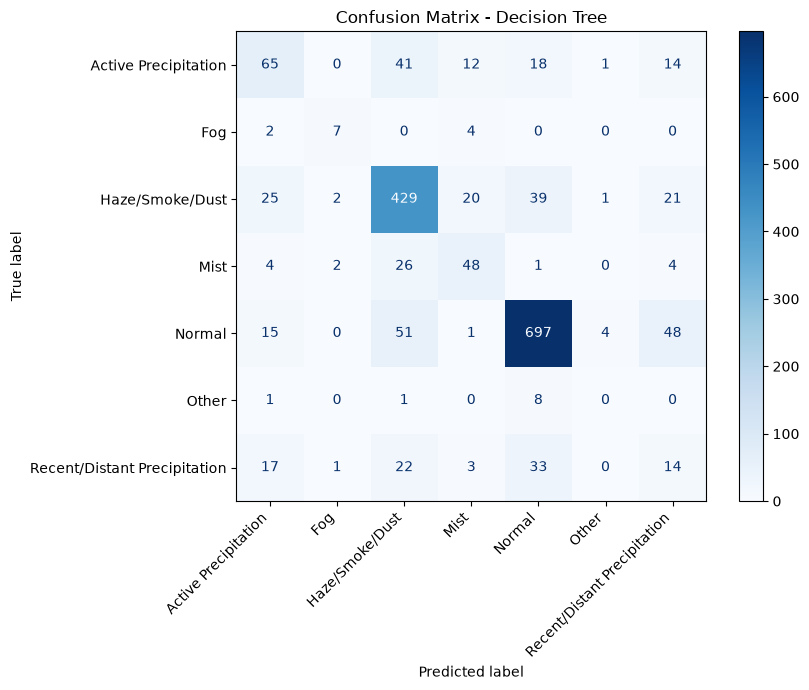

In [163]:
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Decision Tree')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [164]:
cm_dt_df = pd.DataFrame(
    cm_dt,
    index=[inv_label_map[i] for i in range(n_classes)],
    columns=class_names
)

cm_dt_df.index.name = 'Actual'
cm_dt_df.columns.name = 'Predicted'

display(cm_dt_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,65,0,41,12,18,1,14
Fog,2,7,0,4,0,0,0
Haze/Smoke/Dust,25,2,429,20,39,1,21
Mist,4,2,26,48,1,0,4
Normal,15,0,51,1,697,4,48
Other,1,0,1,0,8,0,0
Recent/Distant Precipitation,17,1,22,3,33,0,14


**RANDOM FOREST**

In [153]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=list(range(n_classes)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=class_names
)

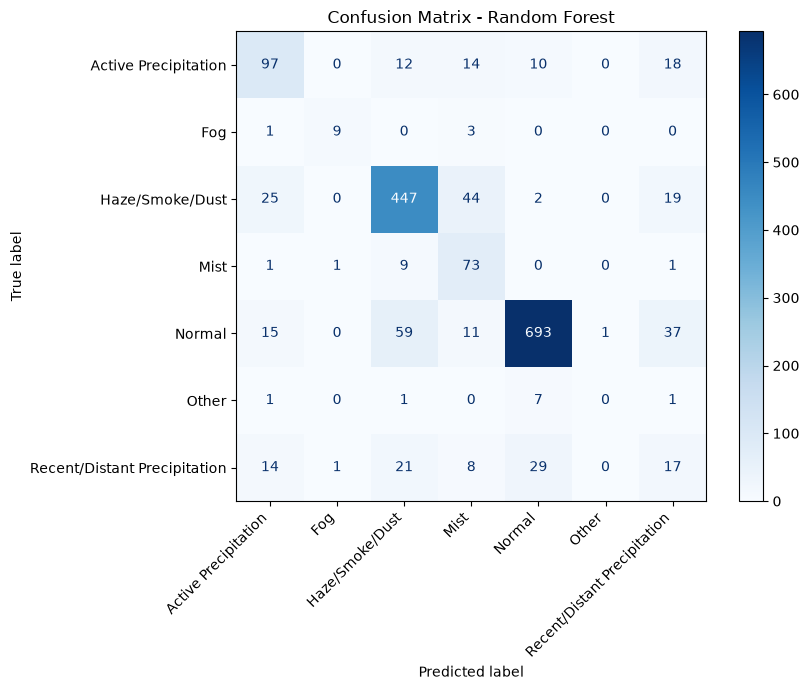

In [154]:
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Random Forest')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [155]:
cm_rf_df = pd.DataFrame(
    cm_rf,
    index=[inv_label_map[i] for i in range(n_classes)],
    columns=class_names
)

cm_rf_df.index.name = 'Actual'
cm_rf_df.columns.name = 'Predicted'

display(cm_rf_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,97,0,12,14,10,0,18
Fog,1,9,0,3,0,0,0
Haze/Smoke/Dust,25,0,447,44,2,0,19
Mist,1,1,9,73,0,0,1
Normal,15,0,59,11,693,1,37
Other,1,0,1,0,7,0,1
Recent/Distant Precipitation,14,1,21,8,29,0,17


**XGBOOST**

In [156]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=list(range(n_classes)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=class_names
)

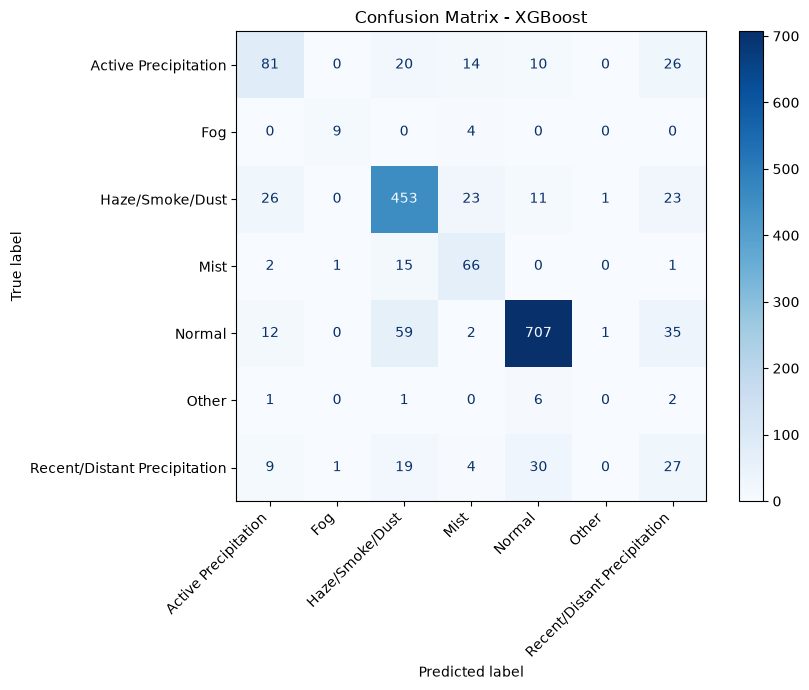

In [157]:
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - XGBoost')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [158]:
cm_xgb_df = pd.DataFrame(
    cm_xgb,
    index=[inv_label_map[i] for i in range(n_classes)],
    columns=class_names
)

cm_xgb_df.index.name = 'Actual'
cm_xgb_df.columns.name = 'Predicted'

display(cm_xgb_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,81,0,20,14,10,0,26
Fog,0,9,0,4,0,0,0
Haze/Smoke/Dust,26,0,453,23,11,1,23
Mist,2,1,15,66,0,0,1
Normal,12,0,59,2,707,1,35
Other,1,0,1,0,6,0,2
Recent/Distant Precipitation,9,1,19,4,30,0,27


**LIGHTGBM**

In [159]:
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm, labels=list(range(n_classes)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lgbm,
    display_labels=class_names
)

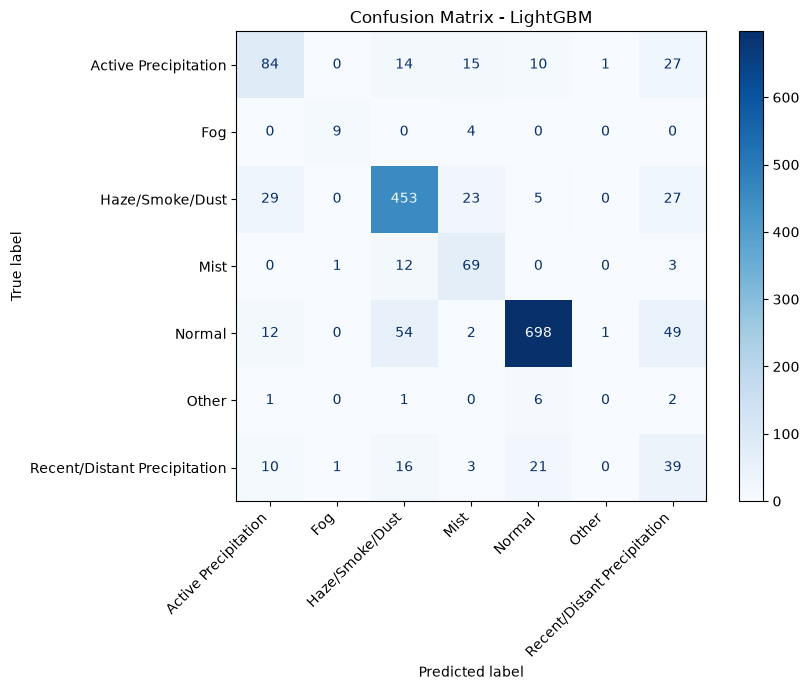

In [160]:
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - LightGBM')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [161]:
cm_lgbm_df = pd.DataFrame(
    cm_lgbm,
    index=[inv_label_map[i] for i in range(n_classes)],
    columns=class_names
)

cm_lgbm_df.index.name = 'Actual'
cm_lgbm_df.columns.name = 'Predicted'

display(cm_lgbm_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,84,0,14,15,10,1,27
Fog,0,9,0,4,0,0,0
Haze/Smoke/Dust,29,0,453,23,5,0,27
Mist,0,1,12,69,0,0,3
Normal,12,0,54,2,698,1,49
Other,1,0,1,0,6,0,2
Recent/Distant Precipitation,10,1,16,3,21,0,39


- Baris menunjukkan kelas aktual.
- Kolom menunjukkan kelas hasil prediksi.
- Diagonal menunjukkan jumlah prediksi yang benar.
- Di luar diagonal menunjukkan kesalahan klasifikasi.

**Notes:**

Berdasarkan *confusion matrix* pada seluruh **1.702 data uji**, **LightGBM** menghasilkan jumlah prediksi benar terbanyak, yaitu **1.352 data**, diikuti oleh **XGBoost** sebanyak **1.343 data**, **Random Forest** sebanyak **1.336 data**, dan **Decision Tree** sebanyak **1.260 data**. Hasil ini sejalan dengan urutan nilai *accuracy* masing-masing model pada data uji.

Secara umum, seluruh model mampu mengenali kelas **Normal** dan **Haze/Smoke/Dust** dengan sangat baik (pada ketiga model *ensemble*, prediksi benar masing-masing berkisar **693–707 dari 816 data** untuk **Normal** dan **447–453 dari 537 data** untuk **Haze/Smoke/Dust**). Namun, masih terdapat kesalahan klasifikasi yang cukup besar pada beberapa kelompok fenomena berikut:
- **Active Precipitation dan Recent/Distant Precipitation:** Kedua kelas ini saling tertukar satu sama lain maupun dengan kelas **Normal**, **Haze/Smoke/Dust**, dan **Mist**. Pada **Random Forest** (model dengan pengenalan **Active Precipitation** tertinggi, **97 dari 151 data**), kesalahan prediksi terbesar bergeser ke **Recent/Distant Precipitation** (18 data), **Mist** (14 data), dan **Haze/Smoke/Dust** (12 data). Sebaliknya, pada kelas aktual **Recent/Distant Precipitation** (90 data), **LightGBM** hanya mampu mengenali **39 data** dengan benar (diikuti XGBoost **27 data** dan Random Forest **17 data**), sedangkan mayoritas sisanya diprediksi sebagai **Normal** (**21–30 data**) dan **Haze/Smoke/Dust** (**16–21 data**). Hal ini menunjukkan bahwa kondisi parameter cuaca permukaan saat hujan berlangsung maupun sesudah/di sekitar stasiun sering menyerupai kondisi cuaca normal atau ber kabut asap.
- **Mist:** Sebagian besar dapat dikenali dengan baik oleh model *ensemble* (tertinggi pada **Random Forest** sebanyak **73 dari 85 data** dan **LightGBM** sebanyak **69 dari 85 data**), dengan sisa kesalahan terutama bergeser ke kelas **Haze/Smoke/Dust** (**9–15 data**).
- **Fog:** Ketiga model *ensemble* (Random Forest, XGBoost, dan LightGBM) menghasilkan jumlah prediksi benar yang sama, yaitu **9 dari 13 data**, sedangkan sisa **3–4 data** lainnya paling sering diprediksi sebagai **Mist** karena keduanya sama-sama ditandai oleh kelembapan sangat tinggi dan jarak pandang rendah.
- **Other:** Menjadi permasalahan paling menonjol karena **0 dari 10 data** berhasil dikenali dengan benar oleh seluruh model. Sebagian besar data pada kelas ini justru diprediksi sebagai **Normal** (**6–8 data** pada setiap model). Kondisi tersebut berkaitan dengan karakteristik kelas **Other** yang merupakan gabungan berbagai kode `ww` di luar kategori utama, sehingga tidak membentuk pola parameter cuaca permukaan yang seragam.

Dengan demikian, **LightGBM** menghasilkan jumlah prediksi benar terbanyak sekaligus keseimbangan antarkelas paling baik pada tahap *baseline*. Meskipun demikian, seluruh model masih mengalami tumpang tindih pada kelas **Recent/Distant Precipitation** serta kegagalan mengenali kelas **Other**, yang menjadi bahan pertimbangan utama untuk tahap *hyperparameter tuning* dan evaluasi lanjutan berikutnya.

### Model Comparison

Merangkum metrik utama keempat model dalam satu tabel untuk menentukan model terbaik

In [166]:
preds = {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}

In [168]:
rows = {}

for name, y_pred in preds.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=list(range(n_classes)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    rows[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': report['Fog']['f1-score'],
        'Mist F1': report['Mist']['f1-score'],
        'Other F1': report['Other']['f1-score'],
        'Active Precipitation F1': report['Active Precipitation']['f1-score'],
        'Recent/Distant Precipitation F1': report['Recent/Distant Precipitation']['f1-score']
    }

In [169]:
comparison_df = pd.DataFrame(rows).T
display(comparison_df.round(3))

,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precipitation F1,Recent/Distant Precipitation F1
Decision Tree,0.740,0.481,0.477,0.56,0.555,0.0,0.464,0.147
Random Forest,0.785,0.557,0.581,0.75,0.613,0.0,0.636,0.186
XGBoost,0.789,0.567,0.574,0.75,0.667,0.0,0.574,0.265
LightGBM,0.794,0.583,0.599,0.75,0.687,0.0,0.585,0.329


**Notes:**

- **Performa Keseluruhan Terbaik:** **LightGBM** mencatatkan performa tertinggi di seluruh metrik evaluasi utama, yaitu **Accuracy (`0,794`)**, **Macro F1 (`0,583`)**, dan **Balanced Accuracy (`0,599`)**. Posisi berikutnya ditempati oleh **XGBoost** (*Macro F1* `0,567`; *Accuracy* `0,789`) dan **Random Forest** (*Balanced Accuracy* `0,581`; *Macro F1* `0,557`), sedangkan **Decision Tree** memperoleh skor terendah di seluruh metrik (*Macro F1* `0,481`).
- **Kelas `Fog` dan `Mist`:** Ketiga model *ensemble* (Random Forest, XGBoost, dan LightGBM) menghasilkan nilai *F1-score* yang identik pada kelas **Fog** sebesar **`0,750`** (lebih tinggi dibandingkan Decision Tree sebesar `0,560`). Pada kelas **Mist**, **LightGBM** unggul dengan *F1-score* **`0,687`**, diikuti oleh XGBoost (`0,667`) dan Random Forest (`0,613`).
- **Kelas Presipitasi (`Active Precipitation` & `Recent/Distant Precipitation`):** **Random Forest** memperoleh *F1-score* tertinggi pada kelas **Active Precipitation** sebesar **`0,636`** (mengungguli LightGBM `0,585` dan XGBoost `0,574`). Sebaliknya, pada kelas **Recent/Distant Precipitation**, **LightGBM** memberikan hasil paling baik (**`0,329`**) dibandingkan XGBoost (`0,265`), Random Forest (`0,186`), dan Decision Tree (`0,147`), meskipun nilainya masih tergolong rendah di seluruh model.
- **Kelas `Other`:** Seluruh model memperoleh *F1-score* **`0,000`**, yang menegaskan bahwa kelas ini belum dapat dikenali sama sekali pada tahap *baseline*.

Secara keseluruhan, **LightGBM** merupakan model *baseline* dengan performa terbaik dan paling seimbang antarkelas, sementara **Random Forest** menunjukkan keunggulan spesifik dalam mengenali kejadian hujan aktif (`Active Precipitation`). Hasil perbandingan ini menjadi tolok ukur utama sebelum memasuki tahap *hyperparameter tuning* dan evaluasi lanjutan.

# 10. Model Selection

Melakukan pemilihan model terbaik berdasarkan hasil Stratified Group Cross-Validation dan evaluasi *Out-of-Fold* (OOF). Proses ini bertujuan membandingkan kestabilan performa model serta kemampuan dalam mengenali setiap kelas fenomena sebagai dasar penentuan kandidat model untuk tahap hyperparameter tuning.

## 10.1 Cross Validation Comparation

Membandingkan performa empat model menggunakan metode *Stratified Group Cross-Validation* dengan 5 fold berdasarkan nilai rata-rata dan standar deviasi Macro F1-Score. Pembagian data dilakukan berdasarkan tanggal untuk mencegah data pada tanggal yang sama tersebar di antara data pelatihan dan validasi.

In [171]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
cv_splits = list(
    cv.split(
        X_train,
        y_train,
        groups=train_df['date']
    )
)

print(f"Jumlah fold: {len(cv_splits)}")

Jumlah fold: 5


In [172]:
candidates = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [174]:
cv_results = []

for name, model in candidates.items():
    fold_scores = []

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[tr_idx]
        y_val = y_train.iloc[val_idx]

        m = clone(model)

        # Menghitung class weight berdasarkan data training fold
        classes = np.unique(y_tr)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=classes,
            y=y_tr
        )
        fold_class_weights = dict(zip(classes, weights))

        # Training model
        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)
            m.fit(X_tr, y_tr, sample_weight=sample_weights)
        else:
            m.set_params(class_weight='balanced')
            m.fit(X_tr, y_tr)

        # Prediksi validation
        y_val_pred = m.predict(X_val)

        # Menghitung Macro F1 untuk 7 kelas
        score = f1_score(
            y_val,
            y_val_pred,
            labels=list(range(n_classes)),
            average='macro',
            zero_division=0
        )

        fold_scores.append(score)
        print(f"{name} | Fold {fold}: Macro F1 = {score:.4f}")

    cv_results.append({
        'Model': name,
        'Macro F1 Mean': np.mean(fold_scores),
        'Macro F1 Std': np.std(fold_scores, ddof=1)
    })

Decision Tree | Fold 1: Macro F1 = 0.4872
Decision Tree | Fold 2: Macro F1 = 0.4759
Decision Tree | Fold 3: Macro F1 = 0.5064
Decision Tree | Fold 4: Macro F1 = 0.5183
Decision Tree | Fold 5: Macro F1 = 0.4569
Random Forest | Fold 1: Macro F1 = 0.5492
Random Forest | Fold 2: Macro F1 = 0.5840
Random Forest | Fold 3: Macro F1 = 0.5404
Random Forest | Fold 4: Macro F1 = 0.5819
Random Forest | Fold 5: Macro F1 = 0.5226
XGBoost | Fold 1: Macro F1 = 0.5747
XGBoost | Fold 2: Macro F1 = 0.5783
XGBoost | Fold 3: Macro F1 = 0.5578
XGBoost | Fold 4: Macro F1 = 0.5859
XGBoost | Fold 5: Macro F1 = 0.5407
LightGBM | Fold 1: Macro F1 = 0.5684
LightGBM | Fold 2: Macro F1 = 0.5845
LightGBM | Fold 3: Macro F1 = 0.5136
LightGBM | Fold 4: Macro F1 = 0.5866
LightGBM | Fold 5: Macro F1 = 0.5819


In [175]:
cv_comparison_df = (
    pd.DataFrame(cv_results)
    .set_index('Model')
    .sort_values('Macro F1 Mean', ascending=False)
)

display(cv_comparison_df.round(4))

,Macro F1 Mean,Macro F1 Std
Model,,
XGBoost,0.5675,0.0182
LightGBM,0.5670,0.0307
Random Forest,0.5556,0.0267
Decision Tree,0.4889,0.0243


**Notes:**

- **XGBoost** memperoleh rata-rata *Macro F1-Score* tertinggi sebesar **0,5675**, diikuti sangat ketat oleh **LightGBM** sebesar **0,5670** dan **Random Forest** sebesar **0,5556**.
- **Decision Tree** memperoleh nilai rata-rata terendah sebesar **0,4889** (terpaut sekitar **0,07–0,08** di bawah ketiga model *ensemble*).
- Selisih rata-rata performa antara **XGBoost**, **LightGBM**, dan **Random Forest** tergolong kecil (berada dalam rentang **0,0119**), yang menunjukkan bahwa ketiga model *ensemble* memiliki kemampuan generalisasi yang kompetitif pada skema *5-fold Stratified Group Cross-Validation*.
- Dari sisi stabilitas antar-*fold*, **XGBoost** menunjukkan variasi performa paling rendah dengan standar deviasi sebesar **0,0182**, sedangkan **LightGBM** memiliki variasi terbesar sebesar **0,0307** (terutama dipengaruhi oleh penurunan skor pada *Fold* 3 sebesar **0,5136**).

## 10.2 Out-of-Fold Per-Class Evaluation

Mengevaluasi kemampuan setiap model dalam mengenali masing-masing kelas fenomena cuaca menggunakan prediksi *out-of-fold* dari seluruh data *training*. Evaluasi ini dilakukan untuk memperoleh gambaran performa per kelas dengan jumlah sampel yang lebih banyak dibandingkan evaluasi pada data uji.

In [176]:
oof_predictions = {}

for name, model in candidates.items():
    oof_pred = np.full(len(y_train), -1, dtype=int)

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[tr_idx]

        # Membuat model baru
        m = clone(model)

        # Menghitung class weight pada data training fold
        classes = np.unique(y_tr)

        weights = compute_class_weight(
            class_weight='balanced',
            classes=classes,
            y=y_tr
        )

        fold_class_weights = dict(zip(classes, weights))

        # Training model
        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)

            m.fit(
                X_tr,
                y_tr,
                sample_weight=sample_weights
            )
        else:
            m.set_params(class_weight='balanced')
            m.fit(X_tr, y_tr)

        # Prediksi data validation
        oof_pred[val_idx] = m.predict(X_val)

    oof_predictions[name] = oof_pred

    print(f"{name}: OOF prediction selesai")

# Memastikan seluruh data sudah mendapatkan prediksi
assert np.all(oof_pred != -1)

Decision Tree: OOF prediction selesai
Random Forest: OOF prediction selesai
XGBoost: OOF prediction selesai
LightGBM: OOF prediction selesai


In [177]:
oof_results = []
class_names = [inv_label_map[i] for i in range(n_classes)]

for name, y_pred in oof_predictions.items():
    report = classification_report(
        y_train,
        y_pred,
        labels=list(range(n_classes)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        oof_results.append({
            'Model': name,
            'Class': class_name,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-Score': report[class_name]['f1-score'],
            'Support': report[class_name]['support']
        })

oof_comparison_df = pd.DataFrame(oof_results)
display(oof_comparison_df.set_index(['Model', 'Class']).round(4))

Precision  Recall  F1-Score  \
Model         Class                                                       
Decision Tree Active Precipitation             0.4356  0.4378    0.4367   
              Fog                              0.5909  0.7027    0.6420   
              Haze/Smoke/Dust                  0.7682  0.7602    0.7642   
              Mist                             0.5477  0.5205    0.5337   
              Normal                           0.8668  0.8649    0.8658   
              Other                            0.0000  0.0000    0.0000   
              Recent/Distant Precipitation     0.1579  0.1721    0.1647   
Random Forest Active Precipitation             0.5154  0.6667    0.5813   
              Fog                              0.8125  0.7027    0.7536   
              Haze/Smoke/Dust                  0.8184  0.8343    0.8262   
              Mist                             0.5228  0.7368    0.6117   
              Normal                           0.9386  0.8820    0.9094   
              Other                            0.0000  0.0000    0.0000   
              Recent/Distant Precipitation     0.2562  0.1694    0.2039   
XGBoost       Active Precipitation             0.5784  0.5937    0.5859   
              Fog                              0.8710  0.7297    0.7941   
              Haze/Smoke/Dust                  0.8036  0.8528    0.8275   
              Mist                             0.6060  0.7105    0.6541   
              Normal                           0.9246  0.8961    0.9101   
              Other                            0.0000  0.0000    0.0000   
              Recent/Distant Precipitation     0.2313  0.1858    0.2061   
LightGBM      Active Precipitation             0.5554  0.6070    0.5800   
              Fog                              0.9630  0.7027    0.8125   
              Haze/Smoke/Dust                  0.8035  0.8447    0.8236   
              Mist                             0.6122  0.7018    0.6540   
              Normal                           0.9257  0.8864    0.9056   
              Other                            0.0000  0.0000    0.0000   
              Recent/Distant Precipitation     0.2310  0.2077    0.2187   

                                            Support  
Model         Class                                  
Decision Tree Active Precipitation            603.0  
              Fog                              37.0  
              Haze/Smoke/Dust                2106.0  
              Mist                            342.0  
              Normal                         3204.0  
              Other                            40.0  
              Recent/Distant Precipitation    366.0  
Random Forest Active Precipitation            603.0  
              Fog                              37.0  
              Haze/Smoke/Dust                2106.0  
              Mist                            342.0  
              Normal                         3204.0  
              Other                            40.0  
              Recent/Distant Precipitation    366.0  
XGBoost       Active Precipitation            603.0  
              Fog                              37.0  
              Haze/Smoke/Dust                2106.0  
              Mist                            342.0  
              Normal                         3204.0  
              Other                            40.0  
              Recent/Distant Precipitation    366.0  
LightGBM      Active Precipitation            603.0  
              Fog                              37.0  
              Haze/Smoke/Dust                2106.0  
              Mist                            342.0  
              Normal                         3204.0  
              Other                            40.0  
              Recent/Distant Precipitation    366.0

In [179]:
oof_macro_f1 = []

for name, y_pred in oof_predictions.items():
    score = f1_score(
        y_train,
        y_pred,
        labels=list(range(n_classes)),
        average='macro',
        zero_division=0
    )

    oof_macro_f1.append({
        'Model': name,
        'OOF Macro F1': score
    })

oof_macro_f1_df = (
    pd.DataFrame(oof_macro_f1)
    .set_index('Model')
    .sort_values('OOF Macro F1', ascending=False)
)

display(oof_macro_f1_df.round(4))

,OOF Macro F1
Model,
LightGBM,0.5706
XGBoost,0.5683
Random Forest,0.5552
Decision Tree,0.4867


**Notes:**

- **Perbandingan OOF Macro F1 secara keseluruhan:** Ketiga model *ensemble* menunjukkan performa yang relatif berdekatan, dengan *OOF Macro F1* tertinggi diperoleh **LightGBM** sebesar **0,5706**, diikuti sangat ketat oleh **XGBoost** sebesar **0,5683** dan **Random Forest** sebesar **0,5552**, sedangkan **Decision Tree** berada paling rendah sebesar **0,4867**.
- **Performa per kelas:** Tidak terdapat satu model yang unggul secara mutlak pada seluruh kelas fenomena:
  - Pada kelas mayoritas **Normal** (*F1-score* **0,9056–0,9101**) dan **Haze/Smoke/Dust** (**0,8236–0,8275**), ketiga model *ensemble* menunjukkan kemampuan pengenalan yang sangat tinggi dengan selisih yang minimal.
  - Pada kelas minoritas **Fog** (37 sampel latih), **LightGBM** mencatatkan *F1-score* tertinggi sebesar **0,8125** (*precision* **0,9630**), diikuti oleh **XGBoost** (**0,7941**) dan **Random Forest** (**0,7536**).
  - Pada kelas **Mist**, **XGBoost** (**0,6541**) dan **LightGBM** (**0,6540**) memperoleh performa yang hampir identik dan lebih unggul dibandingkan **Random Forest** (**0,6117**).
  - Pada kelompok presipitasi, ketiga model *ensemble* mencatat performa yang berdekatan pada **Active Precipitation** (**0,5800–0,5859**, tertinggi pada XGBoost), namun masih mengalami kesulitan pada **Recent/Distant Precipitation** (**0,2039–0,2187**, tertinggi pada LightGBM).
- **Kelas `Other` dan `Decision Tree`:** Seluruh model masih memperoleh *F1-score* **0,0000** pada kelas **Other** (40 sampel latih), sedangkan **Decision Tree** secara konsisten mencatat skor terendah di seluruh kelas dibandingkan ketiga model *ensemble*.
- **Implikasi tahap berikutnya:** Hasil ini mengonfirmasi bahwa ketiga model *ensemble* memiliki keunggulan yang saling melengkapi pada kelas yang berbeda dan masih berpeluang memberikan peningkatan performa setelah dilakukan optimasi parameter (*hyperparameter tuning*).

## 10.3 Model Selection Decision

Menentukan model kandidat yang akan digunakan pada tahap *hyperparameter tuning* berdasarkan hasil *cross-validation* dan evaluasi *out-of-fold*. Pemilihan mempertimbangkan performa keseluruhan, konsistensi antar-*fold*, serta kemampuan model dalam mengenali masing-masing kelas fenomena cuaca.

**Notes:**

- Berdasarkan hasil evaluasi pada data latih, **XGBoost**, **LightGBM**, dan **Random Forest** menunjukkan performa yang kompetitif dan relatif berdekatan, baik berdasarkan rata-rata *Macro F1 Cross-Validation* (**0,5556–0,5675**) maupun evaluasi *Out-of-Fold* (**0,5552–0,5706**).
- Tidak terdapat satu model yang unggul secara mutlak pada seluruh kelas fenomena:
  - **XGBoost** memperoleh rata-rata *Macro F1* tertinggi pada *Cross-Validation* sebesar **0,5675** dengan variasi antar-*fold* paling stabil (`Std = 0,0182`), serta mencatat *F1-Score* tertinggi pada kelas **Normal** (**0,9101**), **Haze/Smoke/Dust** (**0,8275**), **Mist** (**0,6541**), dan **Active Precipitation** (**0,5859**).
  - **LightGBM** memperoleh *Macro F1* tertinggi pada evaluasi *Out-of-Fold* sebesar **0,5706** (dan urutan kedua pada *Cross-Validation* sebesar **0,5670**), serta unggul pada kelas minoritas **Fog** (**0,8125**) dan **Recent/Distant Precipitation** (**0,2187**).
  - **Random Forest** menunjukkan performa yang kompetitif dan seimbang pada kelas utama maupun presipitasi aktif (**Normal** **0,9094**, **Haze/Smoke/Dust** **0,8262**, dan **Active Precipitation** **0,5813**), serta mewakili pendekatan *bagging* yang melengkapi dua model *gradient boosting* lainnya.
- **Decision Tree** tidak dilanjutkan ke tahap optimasi karena menghasilkan *Macro F1* lebih rendah sekitar **0,07–0,08** dibandingkan ketiga model *ensemble* (**0,4889** pada *Cross-Validation* dan **0,4867** pada *Out-of-Fold*) serta memperoleh skor terendah di seluruh kelas. Meskipun demikian, model ini tetap dipertahankan sebagai *baseline* pembanding.
- Berdasarkan pertimbangan tersebut, **Random Forest**, **XGBoost**, dan **LightGBM** dilanjutkan ke tahap *Hyperparameter Tuning*. Model akhir akan ditentukan berdasarkan rata-rata *CV Macro F1*, stabilitas antar-fold (Std CV), serta tingkat *overfitting* (Train-Valid Gap) terbaik setelah proses *tuning*, kemudian dievaluasi menggunakan data uji (*test set*) satu kali sebagai evaluasi akhir.

| Model | Keputusan |
| :--- | :--- |
| **XGBoost** | Dilanjutkan ke *tuning* |
| **LightGBM** | Dilanjutkan ke *tuning* |
| **Random Forest** | Dilanjutkan ke *tuning* |
| **Decision Tree** | Dipertahankan sebagai *baseline* |

# 11. Hyperparameter Tuning

Melakukan optimasi hyperparameter pada model Random Forest, XGBoost, dan LightGBM untuk memperoleh konfigurasi model dengan performa klasifikasi yang lebih baik. Proses tuning dilakukan menggunakan Randomized Search Cross-Validation dengan 5-fold Stratified Group Cross-Validation dan Macro F1-Score sebagai metrik evaluasi utama.

Ruang pencarian disusun dengan mempertimbangkan kompleksitas model dan regularisasi untuk mengurangi kecenderungan overfitting yang ditemukan pada tahap baseline. Bobot kelas tetap diterapkan untuk menangani ketidakseimbangan distribusi kelas. Model dengan konfigurasi terbaik akan ditentukan berdasarkan rata-rata Macro F1 Cross-Validation sebelum dilakukan evaluasi akhir pada data uji.

## 11.1 Define Search Space

Menentukan rentang hyperparameter yang akan diuji pada masing-masing model. Ruang pencarian mencakup parameter yang berpengaruh terhadap jumlah pohon, kompleksitas model, proses pembelajaran, dan regularisasi.

Rentang parameter disusun untuk mengeksplorasi berbagai konfigurasi model sekaligus mengendalikan kompleksitas agar dapat mengurangi kecenderungan overfitting.

### Random Forest

- `n_estimators`: jumlah pohon keputusan yang dibangun dalam model.
- `max_depth`: kedalaman maksimum setiap pohon. Pembatasan kedalaman membantu mengurangi kompleksitas model.
- `min_samples_leaf`: jumlah minimum sampel yang harus terdapat pada suatu leaf. Nilai lebih besar dapat menghasilkan struktur pohon yang lebih sederhana.
- `min_samples_split`: jumlah minimum sampel yang diperlukan untuk membagi suatu node.
- `max_features`: jumlah fitur yang dipertimbangkan ketika mencari pemisahan terbaik pada setiap node.

In [180]:
rf_param_dist = {
    'n_estimators': randint(200, 601),
    'max_depth': [8, 10, 12, 15, 18, 20, None],
    'min_samples_split': randint(2, 21),
    'min_samples_leaf': randint(1, 9),
    'max_features': [0.5, 0.7, 1.0]
}

### XGBoost

- `n_estimators`: jumlah pohon yang dibangun secara bertahap.
- `learning_rate`: mengatur kontribusi setiap pohon baru terhadap model secara keseluruhan.
- `max_depth`: membatasi kedalaman pohon untuk mengendalikan kompleksitas model.
- `min_child_weight`: menentukan batas minimum bobot sampel pada child node agar suatu pemisahan dapat dilakukan.
- `subsample`: proporsi sampel training yang digunakan untuk membangun setiap pohon.
- `colsample_bytree`: proporsi fitur yang digunakan untuk membangun setiap pohon.
- `reg_lambda`: parameter regularisasi L2 yang membantu mengendalikan kompleksitas model.
- `gamma`: nilai minimum pengurangan loss yang diperlukan untuk melakukan pemisahan lebih lanjut pada suatu node.

In [181]:
xgb_param_dist = {
    'n_estimators': randint(200, 801),
    'learning_rate': loguniform(0.02, 0.1),
    'max_depth': randint(2, 6),
    'min_child_weight': randint(5, 41),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': loguniform(5, 50),
    'gamma': uniform(0, 2)
}

### LightGBM

- `n_estimators`: jumlah boosting iteration atau pohon yang dibangun.
- `learning_rate`: mengatur kontribusi setiap pohon baru dalam proses boosting.
- `num_leaves`: jumlah maksimum leaf dalam satu pohon. Parameter ini berpengaruh terhadap kompleksitas model.
- `min_child_samples`: jumlah minimum sampel yang harus terdapat pada setiap leaf.
- `subsample`: proporsi sampel training yang digunakan dalam setiap iterasi.
- `colsample_bytree`: proporsi fitur yang digunakan dalam pembangunan setiap pohon.
- `reg_lambda`: parameter regularisasi L2 untuk membantu mengurangi kompleksitas model.
- `subsample_freq`: frekuensi penerapan subsampling. Nilai `1` berarti subsampling dilakukan pada setiap iterasi boosting.

In [183]:
lgbm_param_dist = {
    'n_estimators': randint(200, 801),
    'learning_rate': loguniform(0.02, 0.1),
    'num_leaves': randint(15, 51),
    'min_child_samples': randint(5, 25),
    'subsample': uniform(0.6, 0.4),
    'subsample_freq': [1],
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': loguniform(1, 50)
}

## 11.2 Randomized Search CV

Melakukan pencarian kombinasi hyperparameter terbaik menggunakan RandomizedSearchCV. Setiap model diuji menggunakan 50 kombinasi parameter yang dipilih secara acak dari ruang pencarian yang telah ditentukan.

Proses pencarian menggunakan 5-fold Stratified Group Cross-Validation dengan pembagian data (`cv_splits`) yang sama seperti tahap Model Selection. Macro F1-Score digunakan sebagai metrik evaluasi utama agar performa setiap kelas diperhitungkan secara seimbang.

Pembobotan kelas tetap diterapkan selama proses pelatihan untuk menangani ketidakseimbangan distribusi kelas. Bobot dihitung berdasarkan data training pada setiap fold agar tidak menggunakan informasi dari data validasi.

In [184]:
search_configs = {
    'Random Forest': {
        'model': rf_model,
        'params': rf_param_dist
    },
    'XGBoost': {
        'model': xgb_model,
        'params': xgb_param_dist
    },
    'LightGBM': {
        'model': lgbm_model,
        'params': lgbm_param_dist
    }
}

In [185]:
class FoldBalancedXGBClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)

        classes = np.unique(y)

        weights = compute_class_weight(
            class_weight='balanced',
            classes=classes,
            y=y
        )

        weight_dict = dict(zip(classes, weights))

        sample_weights = np.array([
            weight_dict[label] for label in y
        ])

        self.estimator_.fit(
            X,
            y,
            sample_weight=sample_weights
        )

        self.classes_ = self.estimator_.classes_

        return self

    def predict(self, X):
        return self.estimator_.predict(X)

In [186]:
search_results = {}
best_estimators = {}

for name, config in search_configs.items():
    print(f"\n{'='*50}")
    print(f"Hyperparameter Tuning: {name}")
    print(f"{'='*50}")

    model = clone(config['model'])
    param_dist = config['params'].copy()

    if name == 'XGBoost':
        # Wrapper menghitung sample_weight pada setiap fold
        base_model = clone(model)
        base_model.set_params(n_jobs=1)

        model = FoldBalancedXGBClassifier(
            estimator=base_model
        )

        # Parameter XGBoost menggunakan prefix estimator__
        param_dist = {
            f'estimator__{param}': values
            for param, values in param_dist.items()
        }
    else:
        # Bobot dihitung otomatis dari y training setiap fold
        model.set_params(
            class_weight='balanced',
            n_jobs=1
        )

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_dist,
        n_iter=50,
        scoring='f1_macro',
        cv=cv_splits,
        random_state=42,
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    search_results[name] = search
    best_estimators[name] = search.best_estimator_

    print(f"\nBest Macro F1: {search.best_score_:.4f}")
    print("Best Parameters:")
    print(search.best_params_)


Hyperparameter Tuning: Random Forest
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best Macro F1: 0.5615
Best Parameters:
{'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 2, 'min_samples_split': 3, 'n_estimators': 539}

Hyperparameter Tuning: XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best Macro F1: 0.5708
Best Parameters:
{'estimator__colsample_bytree': np.float64(0.9208787923016158), 'estimator__gamma': np.float64(0.14910128735954165), 'estimator__learning_rate': np.float64(0.09791164835210922), 'estimator__max_depth': 5, 'estimator__min_child_weight': 5, 'estimator__n_estimators': 671, 'estimator__reg_lambda': np.float64(5.164756216504731), 'estimator__subsample': np.float64(0.679536961635522)}

Hyperparameter Tuning: LightGBM
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best Macro F1: 0.5691
Best Parameters:
{'colsample_bytree': np.float64(0.7801997007878172), 'learning_rate': np.float64(0.020431573091335004)

## 11.3 Compare Tuned Models

**Perbandingan dengan baseline dan train-validation gap**

Pada tahap ini, dilakukan perbandingan performa model sebelum dan sesudah hyperparameter tuning. Perbandingan mencakup rata-rata CV Macro F1, peningkatan terhadap baseline, standar deviasi antar-fold, serta selisih skor train dan validasi untuk melihat indikasi overfitting.

In [188]:
comparison_data = []

for name, search in search_results.items():
    results = search.cv_results_
    idx = search.best_index_

    baseline_score = cv_comparison_df.loc[name, 'Macro F1 Mean']
    valid_score = search.best_score_
    train_score = results['mean_train_score'][idx]

    comparison_data.append({
        'Model': name,
        'Baseline CV Macro F1': baseline_score,
        'Tuned CV Macro F1': valid_score,
        'Improvement': valid_score - baseline_score,
        'Std CV': results['std_test_score'][idx],
        'Train F1': train_score,
        'Valid F1': valid_score,
        'Train-Valid Gap': train_score - valid_score
    })

tuning_comparison = pd.DataFrame(comparison_data)

tuning_comparison = tuning_comparison.sort_values(
    by='Tuned CV Macro F1',
    ascending=False
).reset_index(drop=True)

display(tuning_comparison.round(4))

,Model,Baseline CV Macro F1,Tuned CV Macro F1,Improvement,Std CV,Train F1,Valid F1,Train-Valid Gap
0,XGBoost,0.5675,0.5708,0.0033,0.0190,0.9672,0.5708,0.3965
1,LightGBM,0.5670,0.5691,0.0021,0.0153,0.9472,0.5691,0.3781
2,Random Forest,0.5556,0.5615,0.0058,0.0153,0.8040,0.5615,0.2425


**Notes:**

- **Peningkatan Performa Pasca-Tuning:** Seluruh model mengalami peningkatan rata-rata *CV Macro F1* dibandingkan tahap *baseline*. **XGBoost** memperoleh skor validasi tertinggi sebesar **0,5708** (**+0,0033**), diikuti sangat ketat oleh **LightGBM** sebesar **0,5691** (**+0,0021**) dan **Random Forest** sebesar **0,5615** yang mencatatkan kenaikan terbesar (**+0,0058**).
- **Stabilitas Antar-Fold dan Pengendalian Overfitting:** *Hyperparameter tuning* berhasil menekan variasi performa antar-*fold* (`Std CV`) pada **LightGBM** dan **Random Forest** menjadi **0,0153** (lebih rendah dibandingkan **XGBoost** sebesar **0,0190**). Selain itu, pembatasan kedalaman pohon (`max_depth = 10`) pada **Random Forest** efektif menekan *overfitting* dengan selisih *Train-Valid Gap* paling kecil sebesar **0,2425** (jauh lebih rendah dibandingkan **LightGBM** **0,3781** dan **XGBoost** **0,3965**).
- **Penetapan Model Utama:** Berdasarkan kombinasi stabilitas antar-*fold* dan kemampuan generalisasi (*Train-Valid Gap* terendah), **Random Forest** ditetapkan sebagai model utama untuk tahap evaluasi akhir pada data uji (*test set*), sementara **XGBoost** dan **LightGBM** disertakan sebagai model pembanding.

**Perbandingan F1-score per kelas menggunakan OOF**

Selanjutnya, dilakukan evaluasi menggunakan prediksi Out-of-Fold (OOF) untuk mengetahui kemampuan setiap model dalam mengenali masing-masing kelas. Perbandingan difokuskan pada kelas Fog dan Mist sebagai bagian dari pertimbangan pemilihan model.

In [193]:
oof_predictions = {
    name: cross_val_predict(
        search.best_estimator_,
        X_train,
        y_train,
        cv=cv_splits,
        n_jobs=-1
    )
    for name, search in search_results.items()
}

oof_comparison = pd.DataFrame({
    name: f1_score(
        y_train,
        predictions,
        average=None,
        labels=list(range(n_classes)),
        zero_division=0
    )
    for name, predictions in oof_predictions.items()
}, index=class_names)

display(oof_comparison.round(3))

,Random Forest,XGBoost,LightGBM
Active Precipitation,0.571,0.594,0.597
Fog,0.761,0.800,0.794
Haze/Smoke/Dust,0.807,0.823,0.826
Mist,0.617,0.629,0.649
Normal,0.890,0.906,0.904
Other,0.027,0.031,0.000
Recent/Distant Precipitation,0.253,0.213,0.222


**Notes:**

Berdasarkan hasil *hyperparameter tuning* dan evaluasi *cross-validation*, **Random Forest** dipilih sebagai model utama untuk tahap evaluasi akhir dengan pertimbangan stabilitas generalisasi. Meskipun memperoleh rata-rata *CV Macro F1* (**0,5615**) yang sedikit lebih rendah dibandingkan **XGBoost** (**0,5708**) dan **LightGBM** (**0,5691**), Random Forest memiliki tingkat *overfitting* paling rendah dengan selisih *Train-Valid Gap* terkecil (**0,2425**) serta standar deviasi antar-*fold* yang rendah (`Std CV = 0,0153`, setara dengan LightGBM).

**XGBoost** dan **LightGBM** tetap disertakan sebagai model pembanding untuk melihat perbedaan performa ketiga model pada data uji (*test set*).

## 11.4 Final Evaluation on Test Set

Pada tahap ini, dilakukan evaluasi akhir terhadap model hasil hyperparameter tuning menggunakan data test yang belum digunakan selama proses pelatihan dan pemilihan model. Evaluasi dilakukan menggunakan Accuracy, Macro F1, Balanced Accuracy, serta F1-score setiap kelas. Random Forest ditetapkan sebagai model utama, sedangkan XGBoost dan LightGBM digunakan sebagai pembanding.

In [194]:
test_predictions = {}
test_results = []

for name, search in search_results.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)

    test_predictions[name] = y_pred

    report = classification_report(
        y_test,
        y_pred,
        labels=list(range(n_classes)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, labels=list(range(n_classes)), average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': report['Fog']['f1-score'],
        'Mist F1': report['Mist']['f1-score'],
        'Other F1': report['Other']['f1-score'],
        'Active Precipitation F1': report['Active Precipitation']['f1-score'],
        'Recent/Distant Precipitation F1': report['Recent/Distant Precipitation']['f1-score']
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

,Model,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precipitation F1,Recent/Distant Precipitation F1
0,Random Forest,0.7603,0.5828,0.6324,0.75,0.6173,0.15,0.6301,0.2460
1,XGBoost,0.7902,0.5685,0.5864,0.72,0.6763,0.00,0.5980,0.2634
2,LightGBM,0.7879,0.5833,0.6092,0.75,0.6667,0.00,0.6263,0.3210


**Notes:**

- **Perbandingan Metrik Keseluruhan pada Data Uji:** Ketiga model hasil *tuning* menunjukkan performa yang kompetitif dengan keunggulan pada aspek yang berbeda. **LightGBM** memperoleh *Macro F1* tertinggi sebesar **0,5833**, diikuti sangat ketat oleh **Random Forest** sebesar **0,5828** (selisih hanya **0,0005**), sementara **XGBoost** mencatat *Accuracy* tertinggi sebesar **0,7902** (*Macro F1* **0,5685**). Dari sisi keseimbangan pengenalan antarkelas, **Random Forest** meraih *Balanced Accuracy* tertinggi sebesar **0,6324** (mengungguli LightGBM **0,6092** dan XGBoost **0,5864**).
- **Performa per Kelas Fenomena:**
  - Pada kelas minoritas **Fog**, **Random Forest** dan **LightGBM** sama-sama mencatatkan *F1-score* tertinggi sebesar **0,7500**, sedikit di atas **XGBoost** (**0,7200**).
  - Pada kelas **Other**, **Random Forest** menjadi satu-satunya model yang berhasil mengenali sebagian sampel pada data uji dengan *F1-score* **0,1500**, sedangkan **XGBoost** dan **LightGBM** belum mampu mengenali kelas ini (**0,0000**).
  - Pada kelompok presipitasi, **Random Forest** memperoleh *F1-score* tertinggi untuk **Active Precipitation** sebesar **0,6301** (diikuti LightGBM **0,6263** dan XGBoost **0,5980**), sedangkan **LightGBM** unggul pada **Recent/Distant Precipitation** (**0,3210**) dan **XGBoost** unggul pada kelas **Mist** (**0,6763**).
- **Penetapan Model Akhir:** Meskipun **LightGBM** memperoleh *Macro F1* data uji sedikit lebih tinggi (**0,5833** dibandingkan **0,5828**) dan **XGBoost** unggul pada *Accuracy* (**0,7902**), **Random Forest** tetap ditetapkan sebagai model utama sesuai keputusan pemilihan sebelum pengujian *test set* (dengan pertimbangan *Train-Valid Gap* terendah **0,2425** dan stabilitas antar-*fold* `Std CV = 0,0153`). Hasil pada data uji turut memperkuat keputusan tersebut karena **Random Forest** menghasilkan *Balanced Accuracy* tertinggi (**0,6324**), *Macro F1* yang setara dengan model terbaik (**0,5828**), serta kemampuan mengenali kelas minoritas **Other** dan **Fog** dengan baik. Sementara itu, **XGBoost** dan **LightGBM** dipertahankan sebagai model pembanding.

**CLASSIFICATION REPORT**

In [195]:
for name, y_pred in test_predictions.items():
    print(f"\n{'='*60}")
    print(f"Classification Report: {name}")
    print(f"{'='*60}")

    print(classification_report(
        y_test,
        y_pred,
        labels=list(range(n_classes)),
        target_names=class_names,
        zero_division=0,
        digits=4
    ))


Classification Report: Random Forest
                              precision    recall  f1-score   support

        Active Precipitation     0.6525    0.6093    0.6301       151
                         Fog     0.8182    0.6923    0.7500        13
             Haze/Smoke/Dust     0.8314    0.7896    0.8099       537
                        Mist     0.4747    0.8824    0.6173        85
                      Normal     0.9565    0.8088    0.8765       816
                       Other     0.1000    0.3000    0.1500        10
Recent/Distant Precipitation     0.1914    0.3444    0.2460        90

                    accuracy                         0.7603      1702
                   macro avg     0.5749    0.6324    0.5828      1702
                weighted avg     0.8194    0.7603    0.7821      1702


Classification Report: XGBoost
                              precision    recall  f1-score   support

        Active Precipitation     0.6000    0.5960    0.5980       151
                

**Notes:**

- **Kelas Mayoritas (`Normal` dan `Haze/Smoke/Dust`):** Ketiga model menunjukkan kinerja yang kuat dan konsisten pada dua kelas dengan jumlah sampel terbanyak. **XGBoost** memperoleh *F1-score* tertinggi pada kelas **Normal** sebesar **0,8948** (*support* = 816), sedangkan **LightGBM** unggul pada kelas **Haze/Smoke/Dust** sebesar **0,8299** (*support* = 537). **Random Forest** mencatatkan *precision* tertinggi pada kelas **Normal** sebesar **0,9565**, yang berarti prediksi kondisi normalnya memiliki tingkat kesalahan paling rendah.
- **Kelas `Fog` dan `Mist`:** Pada kelas minoritas **Fog** (*support* = 13), **Random Forest** dan **LightGBM** memperoleh *F1-score* tertinggi yang identik sebesar **0,7500** (*precision* **0,8182**, *recall* **0,6923**), sedikit di atas **XGBoost** (**0,7200**). Pada kelas **Mist** (*support* = 85), seluruh model menghasilkan *recall* yang tinggi (**0,8235–0,8824**), dengan *F1-score* tertinggi diraih oleh **XGBoost** (**0,6763**) karena *precision*-nya (**0,5738**) lebih terjaga dibandingkan **Random Forest** (**0,4747**).
- **Kelompok Presipitasi (`Active Precipitation` dan `Recent/Distant Precipitation`):** Pada **Active Precipitation** (*support* = 151), **Random Forest** mencatatkan *F1-score* tertinggi sebesar **0,6301**, diikuti sangat ketat oleh **LightGBM** (**0,6263**) dan **XGBoost** (**0,5980**). Sebaliknya, pada **Recent/Distant Precipitation** (*support* = 90), performa seluruh model masih relatif rendah dengan *F1-score* terbaik diperoleh **LightGBM** (**0,3210**), diikuti **XGBoost** (**0,2634**) dan **Random Forest** (**0,2460**). Hal ini menunjukkan bahwa karakteristik cuaca permukaan saat hujan baru berhenti atau terjadi di kejauhan sering kali tumpang tindih dengan kondisi **Normal** maupun **Haze/Smoke/Dust**.
- **Kelas Minoritas `Other`:** **Random Forest** menjadi satu-satunya model yang berhasil mengenali sebagian sampel kelas **Other** (*support* = 10) dengan *recall* **0,3000** (3 dari 10 observasi terdeteksi) dan *F1-score* **0,1500** (*precision* **0,1000**), sementara **XGBoost** dan **LightGBM** memperoleh skor **0,0000**. Rendahnya skor pada kelas ini disebabkan oleh keterbatasan jumlah sampel latih serta variasi fenomena cuaca yang beragam di dalam kategori tersebut.
- **Ringkasan Evaluasi Per Kelas:** Secara keseluruhan, **LightGBM** memperoleh *macro avg F1-score* tertinggi sebesar **0,5833**, disusul sangat ketat oleh **Random Forest** sebesar **0,5828**. Namun, **Random Forest** menghasilkan *macro avg recall* (*Balanced Accuracy*) tertinggi sebesar **0,6324** dan menjadi satu-satunya model yang mampu mendeteksi ketujuh kelas fenomena cuaca pada data uji.

**CONFUSION MATRIX**

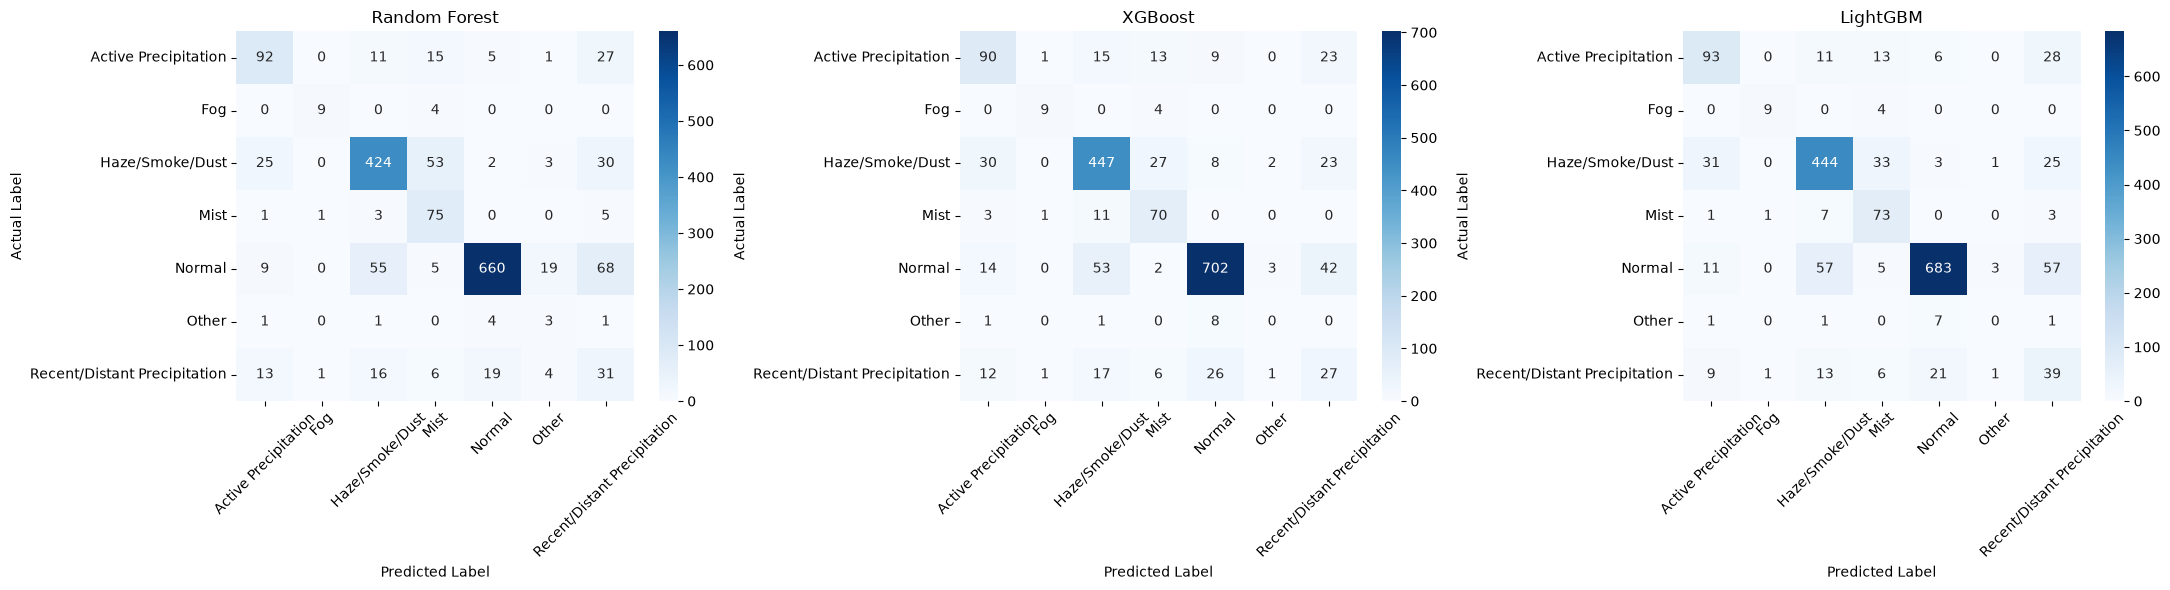

In [196]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, (name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=list(range(n_classes))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [197]:
for name, y_pred in test_predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=list(range(n_classes))
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    print(f"\nConfusion Matrix: {name}")
    display(cm_df)


Confusion Matrix: Random Forest


,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Active Precipitation,92,0,11,15,5,1,27
Fog,0,9,0,4,0,0,0
Haze/Smoke/Dust,25,0,424,53,2,3,30
Mist,1,1,3,75,0,0,5
Normal,9,0,55,5,660,19,68
Other,1,0,1,0,4,3,1
Recent/Distant Precipitation,13,1,16,6,19,4,31



Confusion Matrix: XGBoost


,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Active Precipitation,90,1,15,13,9,0,23
Fog,0,9,0,4,0,0,0
Haze/Smoke/Dust,30,0,447,27,8,2,23
Mist,3,1,11,70,0,0,0
Normal,14,0,53,2,702,3,42
Other,1,0,1,0,8,0,0
Recent/Distant Precipitation,12,1,17,6,26,1,27



Confusion Matrix: LightGBM


,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Active Precipitation,93,0,11,13,6,0,28
Fog,0,9,0,4,0,0,0
Haze/Smoke/Dust,31,0,444,33,3,1,25
Mist,1,1,7,73,0,0,3
Normal,11,0,57,5,683,3,57
Other,1,0,1,0,7,0,1
Recent/Distant Precipitation,9,1,13,6,21,1,39


**Notes:**

- **Distribusi Prediksi Benar per Model:** Secara keseluruhan dari **1.702 data uji**, **XGBoost** menghasilkan total prediksi benar terbanyak yaitu **1.345 data** (unggul pada kelas **Normal** dengan **702** prediksi benar dan **Haze/Smoke/Dust** dengan **447** prediksi benar), diikuti sangat ketat oleh **LightGBM** sebanyak **1.341 data** (unggul pada **Active Precipitation** dengan **93** prediksi benar dan **Recent/Distant Precipitation** dengan **39** prediksi benar). Sementara itu, **Random Forest** menghasilkan **1.294 prediksi benar**, namun mencatatkan deteksi tertinggi pada kelas **Mist** (**75** dari **85** data) serta menjadi satu-satunya model yang mampu mengenali kelas minoritas **Other** (**3** dari **10** data).
- **Pola Klasifikasi pada Kelas `Fog` dan `Mist`:** Ketiga model menunjukkan pola yang identik pada kelas **Fog** (**13 data**), yaitu **9 prediksi benar** dan **4 sisanya tertukar ke kelas Mist**. Secara fisik, kesalahan ini wajar karena *fog* dan *mist* memiliki karakteristik kelembapan udara yang sama-sama tinggi dan hanya dibedakan oleh ambang batas jarak pandang (*visibility* < 1.000 m untuk *fog* dan 1.000–5.000 m untuk *mist*). Pada kelas **Mist** (**85 data**), seluruh model mampu mengenali **70–75 observasi** dengan benar, dengan sebagian kecil kesalahan mengarah ke **Haze/Smoke/Dust** (**3–11 data**) dan **Recent/Distant Precipitation** (**0–5 data**).
- **Pola Kesalahan pada Kelompok Presipitasi:**
  - Pada **Active Precipitation** (**151 data**), ketiga model mengenali **90–93 observasi** dengan benar, sedangkan kesalahan prediksi paling banyak mengarah ke **Recent/Distant Precipitation** (**23–28 data**), **Mist** (**13–15 data**), dan **Haze/Smoke/Dust** (**11–15 data**).
  - Pada **Recent/Distant Precipitation** (**90 data**), tingkat kesalahan masih tergolong tinggi (hanya **27–39 data** terprediksi benar). Mayoritas observasi yang salah diprediksi sebagai **Normal** (**19–26 data**), **Haze/Smoke/Dust** (**13–17 data**), dan **Active Precipitation** (**9–13 data**), yang mencerminkan kemiripan kondisi parameter cuaca permukaan saat hujan baru reda atau terjadi di kejauhan dengan kondisi cuaca cerah/berawan maupun kabut asap tipis.
- **Tumpang Tindih pada Kelas `Normal`, `Haze/Smoke/Dust`, dan `Other`:** Pada kelas **Normal** (**816 data**), kesalahan paling sering terjadi karena diprediksi sebagai **Haze/Smoke/Dust** (**53–57 data**) dan **Recent/Distant Precipitation** (**42–68 data**). Khusus pada **Random Forest**, sensitivitas terhadap kelas minoritas menyebabkan **19 data Normal** ikut terprediksi sebagai **Other**, yang di sisi lain memungkinkan model ini menangkap **3 dari 10 data Other** (sedangkan pada **XGBoost** dan **LightGBM**, seluruh kelas **Other** gagal terdeteksi dan mayoritas masuk ke kelas **Normal** sebanyak **7–8 data**).
- **Implikasi Evaluasi:** Pola kesalahan yang berbeda antarmodel menegaskan bahwa evaluasi tidak cukup hanya mengandalkan *Accuracy*, melainkan harus mempertimbangkan *Macro F1*, *Balanced Accuracy*, serta analisis *confusion matrix* per kelas untuk memahami kecenderungan kesalahan model pada fenomena cuaca yang memiliki kemiripan karakteristik fisik.

# 12. Feature Importance

Tahap ini dilakukan untuk mengetahui kontribusi setiap fitur dalam proses klasifikasi fenomena visibility menggunakan model Random Forest. Analisis dilakukan menggunakan feature importance bawaan model dan permutation importance sebagai pendekatan pembanding.

## 12.1 Impurity-based Feature Importance

Analisis ini menggunakan nilai feature importance bawaan Random Forest untuk mengukur kontribusi setiap fitur berdasarkan penurunan impurity pada seluruh pohon keputusan. Nilai yang lebih tinggi menunjukkan bahwa fitur tersebut lebih banyak berkontribusi dalam proses pemisahan data.

In [198]:
final_rf = search_results['Random Forest'].best_estimator_

In [199]:
feature_importance = pd.DataFrame({
    'Feature': selected_features,
    'Importance': final_rf.feature_importances_
})

In [200]:
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance
0,visibility_vv,0.2998
1,relative_humidity_pc,0.1401
2,temp_drybulb_c_tttttt,0.0803
3,cloud_low_cover_1,0.0767
4,hour_cos,0.0702
5,pressure_qff_mb_derived,0.0571
6,temp_dewpoint_c_tdtdtd,0.0523
7,cloud_cover_oktas_m,0.0512
8,wind_dir_cos,0.0466
9,wind_dir_sin,0.0442


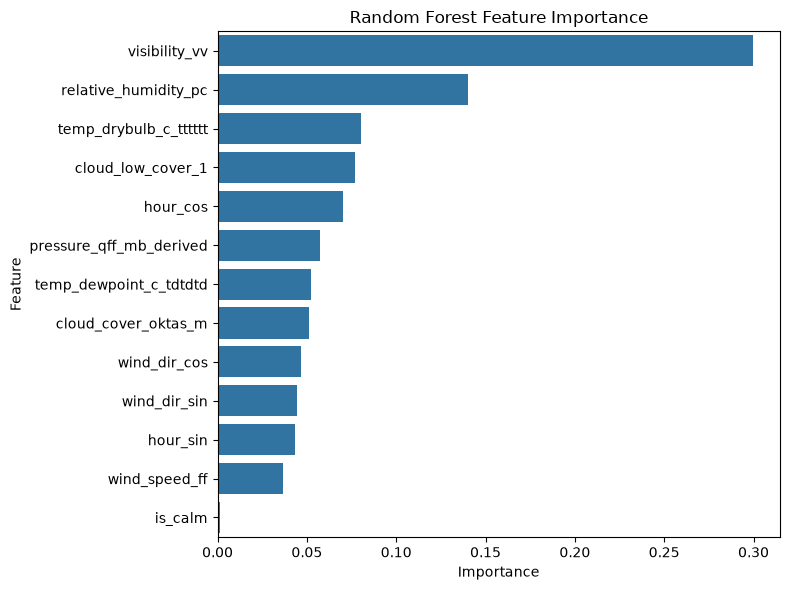

In [201]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Notes:**

- **Dominasi Fitur Utama (`visibility_vv` dan `relative_humidity_pc`):** Fitur **`visibility_vv`** memiliki nilai *importance* tertinggi sebesar **0,2998**, diikuti oleh **`relative_humidity_pc`** sebesar **0,1401**. Kedua fitur ini secara gabungan menyumbang hampir separuh (**43,99%**) dari total penurunan *impurity* model. Secara meteorologis, hasil ini konsisten karena nilai jarak pandang (*visibility*) menjadi pembeda langsung antara **Fog**, **Mist**, dan **Haze/Smoke/Dust**, sedangkan kelembapan relatif memisahkan fenomena berbasis uap air/presipitasi dari partikel kering seperti asap atau debu.
- **Kontribusi Fitur Pendukung Teratas:** Posisi ketiga hingga kelima ditempati oleh **`temp_drybulb_c_tttttt`** (**0,0803**), **`cloud_low_cover_1`** (**0,0767**), dan **`hour_cos`** (**0,0702**). Kelima fitur teratas secara keseluruhan mencakup **66,71%** kontribusi pemisahan data, yang menunjukkan bahwa suhu udara permukaan, tutupan awan rendah (indikator kondisi hujan/berawan), serta siklus diurnal waktu pengamatan berperan penting dalam membedakan fenomena cuaca.
- **Fitur dengan Kontribusi Terendah (`is_calm`):** Fitur **`is_calm`** mencatat nilai *importance* paling kecil sebesar **0,0013**. Hal ini wajar karena informasi kondisi angin tenang (*calm*) merupakan variabel biner turunan yang informasinya sudah terwakili secara lebih rinci oleh fitur kontinu **`wind_speed_ff`** (**0,0369**).
- **Catatan Interpretasi:** Nilai *impurity-based feature importance* menggambarkan seberapa besar kontribusi suatu fitur dalam memecah simpul keputusan (*nodes*) pada pohon Random Forest, bukan hubungan sebab-akibat secara fisik. Selain itu, fitur-fitur yang saling berkorelasi (seperti **`temp_drybulb_c_tttttt`** dengan **`temp_dewpoint_c_tdtdtd`**, maupun **`cloud_low_cover_1`** dengan **`cloud_cover_oktas_m`**) cenderung saling berbagi bobot nilai *importance*.

## 12.2 Permutation Feature Importance

Permutation importance digunakan untuk mengevaluasi kontribusi fitur berdasarkan perubahan kinerja model ketika nilai suatu fitur diacak. Pengujian dilakukan pada data uji menggunakan Macro F1 sebagai metrik evaluasi. Semakin besar penurunan skor setelah pengacakan, semakin besar ketergantungan model terhadap fitur tersebut.

In [202]:
perm_result = permutation_importance(
    final_rf,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [203]:
permutation_importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_result.importances_mean,
    'Importance Std': perm_result.importances_std
})

In [204]:
permutation_importance_df = permutation_importance_df.sort_values(
    by='Importance Mean',
    ascending=False
).reset_index(drop=True)

display(permutation_importance_df.round(4))

,Feature,Importance Mean,Importance Std
0,visibility_vv,0.2879,0.0089
1,relative_humidity_pc,0.1002,0.0126
2,cloud_cover_oktas_m,0.0504,0.0080
3,cloud_low_cover_1,0.0319,0.0064
4,wind_speed_ff,0.0266,0.0160
5,hour_cos,0.0222,0.0066
6,temp_drybulb_c_tttttt,0.0127,0.0075
7,pressure_qff_mb_derived,0.0052,0.0045
8,hour_sin,0.0022,0.0021
9,is_calm,0.0000,0.0001


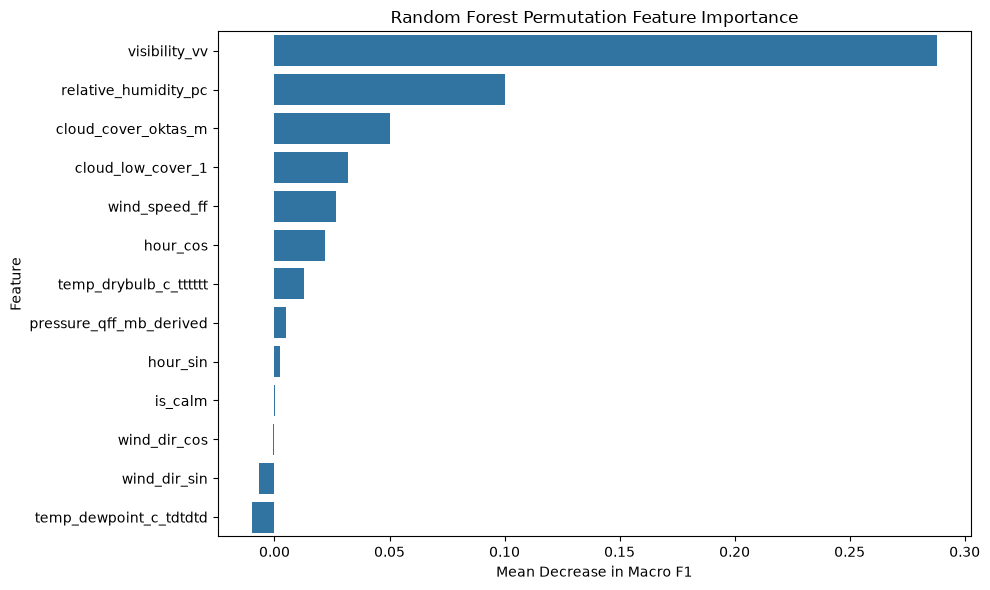

In [205]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=permutation_importance_df,
    x='Importance Mean',
    y='Feature'
)

plt.title('Random Forest Permutation Feature Importance')
plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

- Nilai importance positif menunjukkan bahwa pengacakan fitur menurunkan kinerja model
- Nilai mendekati nol menunjukkan perubahan yang kecil
- Nilai negatif berarti skor model justru meningkat setelah fitur diacak

**Notes:**

- **Konsistensi Dua Fitur Paling Berpengaruh (`visibility_vv` dan `relative_humidity_pc`):** Selaras dengan hasil *impurity-based importance*, fitur **`visibility_vv`** memiliki nilai *permutation importance* tertinggi sebesar **0,2879** (± **0,0089**), diikuti oleh **`relative_humidity_pc`** sebesar **0,1002** (± **0,0126**). Pengacakan kedua fitur ini menyebabkan penurunan skor *Macro F1* paling tajam pada data uji, yang menegaskan bahwa model sangat bergantung pada jarak pandang dan kelembapan relatif dalam membedakan fenomena cuaca.
- **Peningkatan Kontribusi Tutupan Awan dan Kecepatan Angin:** Pada pengujian berbasis permutasi, fitur tutupan awan total **`cloud_cover_oktas_m`** menempati posisi ketiga dengan penurunan skor sebesar **0,0504** (± **0,0080**), diikuti oleh tutupan awan rendah **`cloud_low_cover_1`** sebesar **0,0319** (± **0,0064**) dan kecepatan angin **`wind_speed_ff`** sebesar **0,0266** (± **0,0160**). Hal ini menunjukkan bahwa informasi kondisi perawanan dan dinamika angin permukaan berperan penting dalam menjaga akurasi generalisasi pada data uji—khususnya untuk memisahkan kelompok presipitasi dari kondisi normal maupun kabut asap.
- **Kontribusi Fitur Waktu dan Suhu:** Fitur siklus waktu **`hour_cos`** (**0,0222**) dan suhu bola kering **`temp_drybulb_c_tttttt`** (**0,0127**) memberikan kontribusi positif yang moderat, diikuti oleh tekanan udara **`pressure_qff_mb_derived`** (**0,0052**) dan **`hour_sin`** (**0,0022**).
- **Fitur dengan Nilai Mendekati Nol atau Negatif:** Fitur **`is_calm`** memiliki nilai **0,0000**, sedangkan **`wind_dir_cos`** (**-0,0009**), **`wind_dir_sin`** (**-0,0069**), dan **`temp_dewpoint_c_tdtdtd`** (**-0,0099**) bernilai sedikit negatif. Nilai mendekati nol atau negatif pada *permutation importance* tidak berarti fitur tersebut tidak relevan secara fisik, melainkan dapat terjadi akibat **multikolinearitas** (misalnya informasi titik embun `temp_dewpoint_c_tdtdtd` yang secara fisik berkaitan erat dengan `temp_drybulb_c_tttttt` dan `relative_humidity_pc`) serta sensitivitas metrik *Macro F1* terhadap fluktuasi kecil pada kelas minoritas saat fitur diacak.

## 12.3 Perbandingan dan Interpretasi Feature Importance

Hasil impurity-based dan permutation importance dibandingkan untuk melihat konsistensi kontribusi fitur terhadap model Random Forest. Perbandingan ini juga digunakan untuk mengidentifikasi fitur yang memiliki kontribusi dominan serta fitur yang menunjukkan perbedaan hasil pada kedua metode.

In [206]:
importance_comparison = feature_importance.merge(
    permutation_importance_df,
    on='Feature'
)

In [207]:
importance_comparison = importance_comparison.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(importance_comparison.round(4))

,Feature,Importance,Importance Mean,Importance Std
0,visibility_vv,0.2998,0.2879,0.0089
1,relative_humidity_pc,0.1401,0.1002,0.0126
2,temp_drybulb_c_tttttt,0.0803,0.0127,0.0075
3,cloud_low_cover_1,0.0767,0.0319,0.0064
4,hour_cos,0.0702,0.0222,0.0066
5,pressure_qff_mb_derived,0.0571,0.0052,0.0045
6,temp_dewpoint_c_tdtdtd,0.0523,-0.0099,0.0045
7,cloud_cover_oktas_m,0.0512,0.0504,0.0080
8,wind_dir_cos,0.0466,-0.0009,0.0066
9,wind_dir_sin,0.0442,-0.0069,0.0054


**Notes:**

- **Konsistensi Dua Fitur Utama (`visibility_vv` dan `relative_humidity_pc`):** Kedua metode memberikan hasil yang sepenuhnya konsisten pada dua peringkat teratas. **`visibility_vv`** menjadi fitur paling dominan dengan *impurity importance* sebesar **0,2998** dan *permutation importance* sebesar **0,2879**, diikuti oleh **`relative_humidity_pc`** pada posisi kedua di kedua metode (masing-masing **0,1401** dan **0,1002**). Hal ini menegaskan bahwa jarak pandang dan kelembapan relatif merupakan fondasi utama model, baik saat membangun aturan pemisahan di data latih maupun saat menjaga akurasi prediksi di data uji.
- **Fitur yang Kontribusinya Lebih Menonjol pada Data Uji (`cloud_cover_oktas_m` dan `wind_speed_ff`):** Fitur tutupan awan total **`cloud_cover_oktas_m`** (peringkat ke-8 pada *impurity* sebesar **0,0512**, namun naik ke peringkat ke-3 pada *permutation* sebesar **0,0504**) dan kecepatan angin **`wind_speed_ff`** (peringkat ke-12 pada *impurity* sebesar **0,0369**, namun naik ke peringkat ke-5 pada *permutation* sebesar **0,0266**) menunjukkan dampak yang lebih besar saat diuji pada data baru. Pengacakan kedua fitur ini menurunkan skor *Macro F1* secara nyata karena informasi tutupan awan dan angin permukaan sangat dibutuhkan untuk memisahkan kelompok presipitasi dan kabut asap pada data uji.
- **Fitur Pendukung dengan Kontribusi Positif Konsisten (`cloud_low_cover_1`, `hour_cos`, `temp_drybulb_c_tttttt`, `pressure_qff_mb_derived`):** Tutupan awan rendah **`cloud_low_cover_1`** menempati peringkat ke-4 secara konsisten pada kedua metode (**0,0767** dan **0,0319**). Sementara itu, **`temp_drybulb_c_tttttt`** (**0,0803** vs **0,0127**), **`hour_cos`** (**0,0702** vs **0,0222**), dan **`pressure_qff_mb_derived`** (**0,0571** vs **0,0052**) memiliki bobot *impurity* yang cukup besar saat pembentukan pohon keputusan, namun dampak permutasinya pada data uji lebih moderat.
- **Perbedaan Akibat Korelasi Antarfitur (`temp_dewpoint_c_tdtdtd` dan Arah Angin):** Fitur **`temp_dewpoint_c_tdtdtd`** (**0,0523** pada *impurity*, namun **-0,0099** pada *permutation*) serta komponen arah angin **`wind_dir_cos`** (**0,0466** vs **-0,0009**) dan **`wind_dir_sin`** (**0,0442** vs **-0,0069**) tercatat berkontribusi pada pemisahan simpul pohon saat pelatihan, tetapi bernilai mendekati nol atau sedikit negatif pada uji permutasi. Kondisi ini dipengaruhi oleh multikolinearitas fisik (informasi titik embun saling tumpang tindih dengan suhu bola kering dan kelembapan relatif) serta sensitivitas metrik *Macro F1* terhadap perubahan kecil pada kelas minoritas saat fitur diacak.
- **Fitur dengan Kontribusi Minimal (`is_calm`):** Fitur **`is_calm`** menempati posisi terbawah pada kedua metode (**0,0013** dan **0,0000**) karena informasinya sudah terwakili secara lebih informatif oleh fitur kontinu **`wind_speed_ff`**.

# 13. External Validation

External validation dilakukan untuk mengevaluasi kemampuan generalisasi model Random Forest pada data observasi dari periode yang berbeda, yaitu Januari–Maret 2026. Data eksternal diproses menggunakan tahapan preprocessing dan feature engineering yang sama seperti data pelatihan. Model kemudian digunakan untuk menghasilkan prediksi tanpa dilakukan pelatihan ulang.

## 13.1 Inspeksi Data Eksternal

Tahap ini dilakukan untuk memeriksa struktur, tipe data, jumlah observasi, serta kelengkapan data eksternal periode Januari–Maret 2026. Pemeriksaan awal diperlukan untuk memastikan data dapat diproses menggunakan tahapan preprocessing dan feature engineering yang telah diterapkan pada data pelatihan.

In [209]:
external_df = pd.read_csv('../visibility-dataset/stamet_jambi_hourly_full_2026.csv')

In [210]:
external_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   station_name             2106 non-null   str    
 1   data_timestamp           2106 non-null   str    
 2   wind_dir_deg_dd          2106 non-null   int64  
 3   wind_speed_ff            2106 non-null   int64  
 4   pressure_qfe_mb_derived  2106 non-null   float64
 5   pressure_qff_mb_derived  2106 non-null   float64
 6   temp_drybulb_c_tttttt    2106 non-null   float64
 7   temp_dewpoint_c_tdtdtd   2106 non-null   float64
 8   temp_wetbulb_c           2106 non-null   float64
 9   relative_humidity_pc     2106 non-null   int64  
 10  cloud_low_cover_1        2104 non-null   float64
 11  cloud_cover_oktas_m      2106 non-null   int64  
 12  rainfall_24h_rrrr        49 non-null     float64
 13  rainfall_mm              647 non-null    float64
 14  rainfall_period_h        117 non-nu

In [211]:
missing_summary = pd.DataFrame({
    'Missing Count': external_df.isna().sum(),
    'Missing (%)': (external_df.isna().mean() * 100).round(2)
})

missing_summary.sort_values(by='Missing Count', ascending=False)

,Missing Count,Missing (%)
rainfall_24h_rrrr,2057,97.67
rainfall_period_h,1989,94.44
rainfall_mm,1459,69.28
weather_code_ww,1404,66.67
cloud_low_cover_1,2,0.09
pressure_qfe_mb_derived,0,0.00
wind_speed_ff,0,0.00
wind_dir_deg_dd,0,0.00
data_timestamp,0,0.00
station_name,0,0.00


## 13.2 Pemeriksaan Timestamp dan Data Observasi

Pemeriksaan dilakukan terhadap rentang waktu pengamatan, duplikasi timestamp, interval antarobservasi, serta distribusi jenis laporan. Tahap ini bertujuan untuk mengetahui konsistensi data sebelum dilakukan preprocessing.

In [212]:
external_df['data_timestamp'] = pd.to_datetime(
    external_df['data_timestamp'],
    errors='coerce'
)

In [213]:
print("Rentang waktu:")
print("Mulai :", external_df['data_timestamp'].min())
print("Selesai:", external_df['data_timestamp'].max())

print("\nJumlah timestamp tidak valid:",
      external_df['data_timestamp'].isna().sum())

print("Jumlah timestamp duplikat:",
      external_df['data_timestamp'].duplicated().sum())

Rentang waktu:
Mulai : 2026-01-01 00:00:00
Selesai: 2026-03-31 23:00:00

Jumlah timestamp tidak valid: 0
Jumlah timestamp duplikat: 0


In [214]:
timestamp_sorted = (
    external_df['data_timestamp']
    .dropna()
    .drop_duplicates()
    .sort_values()
)
intervals = timestamp_sorted.diff().dropna()

In [215]:
print("Distribusi interval antarobservasi:")
display(intervals.value_counts().head(10))

Distribusi interval antarobservasi:


data_timestamp
0 days 01:00:00    2052
0 days 02:00:00      52
0 days 03:00:00       1
Name: count, dtype: int64

In [216]:
monthly_counts = (
    external_df
    .dropna(subset=['data_timestamp'])
    .assign(month=lambda df: df['data_timestamp'].dt.to_period('M'))
    .groupby('month')
    .size()
)
monthly_counts

month
2026-01    726
2026-02    652
2026-03    728
Freq: M, dtype: int64

## 13.3 Pemeriksaan Distribusi Fenomena

Pemeriksaan dilakukan untuk mengetahui distribusi setiap kategori fenomena pada data eksternal. Hasilnya dibandingkan dengan data pelatihan untuk melihat perbedaan karakteristik label serta memastikan seluruh kategori dapat diproses menggunakan pemetaan label yang sama.

In [217]:
print("Distribusi fenomena data eksternal:")
display(
    external_df['phenomenon']
    .value_counts(dropna=False)
    .to_frame('Jumlah')
)

Distribusi fenomena data eksternal:


,Jumlah
phenomenon,
Normal,1469
Haze/Smoke/Dust,346
Active Precipitation,144
Recent/Distant Precipitation,92
Mist,40
Other,13
Fog,2


In [218]:
print("Distribusi fenomena data pelatihan:")
display(
    clean_df['phenomenon']
    .value_counts(dropna=False)
    .to_frame('Jumlah')
)

Distribusi fenomena data pelatihan:


,Jumlah
phenomenon,
Normal,4020
Haze/Smoke/Dust,2643
Active Precipitation,754
Recent/Distant Precipitation,456
Mist,427
Fog,50
Other,50


In [219]:
print("Kategori fenomena:")
print("Eksternal :", sorted(external_df['phenomenon'].dropna().unique()))
print("Pelatihan :", sorted(clean_df['phenomenon'].dropna().unique()))

Kategori fenomena:
Eksternal : ['Active Precipitation', 'Fog', 'Haze/Smoke/Dust', 'Mist', 'Normal', 'Other', 'Recent/Distant Precipitation']
Pelatihan : ['Active Precipitation', 'Fog', 'Haze/Smoke/Dust', 'Mist', 'Normal', 'Other', 'Recent/Distant Precipitation']


## 13.4 Cleaning Data Eksternal

Data eksternal dibersihkan menggunakan aturan preprocessing yang sama dengan data pelatihan. Tahapan meliputi penyesuaian struktur data, penghapusan kolom yang tidak digunakan, penanganan missing value, penyesuaian tipe data, serta konversi timestamp ke waktu lokal WIB.

In [220]:
external_clean = external_df.copy()

In [221]:
drop_cols = [
    'station_name',
    'weather_code_ww',
    'ix_flag',
    'pressure_qfe_mb_derived',
    'rainfall_24h_rrrr',
    'rainfall_period_h',
    'report_type',
    'raw_synop'
]

In [222]:
external_clean.drop(columns=drop_cols, inplace=True)
external_clean['cloud_low_cover_1'] = (external_clean['cloud_low_cover_1'].ffill())
external_clean.drop(columns=['rainfall_mm'], inplace=True)

In [223]:
print("Missing values:")
display(external_clean.isna().sum())

Missing values:


data_timestamp             0
wind_dir_deg_dd            0
wind_speed_ff              0
pressure_qff_mb_derived    0
temp_drybulb_c_tttttt      0
temp_dewpoint_c_tdtdtd     0
temp_wetbulb_c             0
relative_humidity_pc       0
cloud_low_cover_1          0
cloud_cover_oktas_m        0
phenomenon                 0
visibility_vv              0
dtype: int64

## 13.5 Penyesuaian Tipe Data dan Waktu Lokal

Pada tahap ini, tipe data kolom tutupan awan disesuaikan agar konsisten dengan data training. Selain itu, dilakukan konversi waktu observasi dari UTC ke WIB dengan menambahkan selisih waktu 7 jam. Penyesuaian ini bertujuan agar format data eksternal sesuai dengan data yang digunakan saat pelatihan model.

In [224]:
external_clean['cloud_low_cover_1'] = external_clean['cloud_low_cover_1'].astype('int8')
external_clean['cloud_cover_oktas_m'] = external_clean['cloud_cover_oktas_m'].astype('int8')

In [225]:
date_position = external_clean.columns.get_loc('data_timestamp') + 1
external_clean.insert(date_position, 'datetime_wib', external_clean['data_timestamp'] + pd.Timedelta(hours=7))
external_clean[['data_timestamp', 'datetime_wib']].head()

,data_timestamp,datetime_wib
0,2026-01-01 00:00:00,2026-01-01 07:00:00
1,2026-01-01 01:00:00,2026-01-01 08:00:00
2,2026-01-01 02:00:00,2026-01-01 09:00:00
3,2026-01-01 03:00:00,2026-01-01 10:00:00
4,2026-01-01 04:00:00,2026-01-01 11:00:00


In [226]:
print("Rentang waktu WIB:")
print(external_clean['datetime_wib'].min(), "hingga", external_clean['datetime_wib'].max())

Rentang waktu WIB:
2026-01-01 07:00:00 hingga 2026-04-01 06:00:00


## 13.6 Feature Engineering

Pada tahap ini dilakukan pembentukan fitur turunan pada data eksternal menggunakan transformasi yang sama dengan data training. Fitur yang dibentuk meliputi encoding siklik waktu, encoding arah angin, dan indikator kondisi angin tenang.

In [227]:
external_clean['hour'] = external_clean['datetime_wib'].dt.hour

external_clean['hour_sin'] = np.sin(2 * np.pi * external_clean['hour'] / 24)
external_clean['hour_cos'] = np.cos(2 * np.pi * external_clean['hour'] / 24)

In [228]:
external_clean['wind_dir_sin'] = np.sin(np.deg2rad(external_clean['wind_dir_deg_dd']))
external_clean['wind_dir_cos'] = np.cos(np.deg2rad(external_clean['wind_dir_deg_dd']))

In [229]:
external_clean['is_calm'] = (external_clean['wind_speed_ff'] == 0).astype(int)

## 13.7 Feature Selection & Input Preparation

Pada tahap ini dipilih fitur-fitur yang digunakan sebagai input model berdasarkan daftar fitur saat training. Pemilihan dilakukan untuk memastikan data eksternal memiliki nama kolom dan urutan fitur yang sama dengan input model final_rf.

In [230]:
selected_features = [
    'visibility_vv',
    'relative_humidity_pc',
    'hour_cos',
    'cloud_low_cover_1',
    'temp_drybulb_c_tttttt',
    'pressure_qff_mb_derived',
    'cloud_cover_oktas_m',
    'wind_dir_cos',
    'hour_sin',
    'temp_dewpoint_c_tdtdtd',
    'wind_dir_sin',
    'wind_speed_ff',
    'is_calm'
]

 Memeriksa fitur yang belum tersedia

In [231]:
missing_features = [
    col for col in selected_features
    if col not in external_clean.columns
]

if missing_features:
    raise ValueError(
        f'Fitur tidak ditemukan: {missing_features}'
    )

print(f'Jumlah fitur tersedia: {len(selected_features)}')
print('Seluruh fitur yang dibutuhkan tersedia.')

Jumlah fitur tersedia: 13
Seluruh fitur yang dibutuhkan tersedia.


In [232]:
model_features = list(final_rf.feature_names_in_)

print("Fitur yang berbeda posisi:")

for i, (model_col, external_col) in enumerate(
    zip(model_features, selected_features), start=1
):
    if model_col != external_col:
        print(
            f"Posisi {i}: Model = {model_col} | "
            f"External = {external_col}"
        )

Fitur yang berbeda posisi:
Posisi 1: Model = wind_speed_ff | External = visibility_vv
Posisi 2: Model = wind_dir_sin | External = relative_humidity_pc
Posisi 3: Model = wind_dir_cos | External = hour_cos
Posisi 4: Model = is_calm | External = cloud_low_cover_1
Posisi 5: Model = pressure_qff_mb_derived | External = temp_drybulb_c_tttttt
Posisi 6: Model = temp_drybulb_c_tttttt | External = pressure_qff_mb_derived
Posisi 7: Model = temp_dewpoint_c_tdtdtd | External = cloud_cover_oktas_m
Posisi 8: Model = relative_humidity_pc | External = wind_dir_cos
Posisi 9: Model = cloud_low_cover_1 | External = hour_sin
Posisi 10: Model = cloud_cover_oktas_m | External = temp_dewpoint_c_tdtdtd
Posisi 11: Model = visibility_vv | External = wind_dir_sin
Posisi 12: Model = hour_sin | External = wind_speed_ff
Posisi 13: Model = hour_cos | External = is_calm


In [233]:
selected_features = list(final_rf.feature_names_in_)
X_external = external_clean[selected_features].copy()

In [234]:
assert list(X_external.columns) == list(final_rf.feature_names_in_)
print("Dimensi X_external:", X_external.shape)

display(X_external.head())

Dimensi X_external: (2106, 13)


,wind_speed_ff,wind_dir_sin,wind_dir_cos,is_calm,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,visibility_vv,hour_sin,hour_cos
0,2,0.766044,-0.642788,0,1009.1,23.6,23.2,98,4,8,3.0,0.965926,-0.258819
1,4,0.866025,-0.500000,0,1010.1,24.0,23.3,96,4,8,5.0,0.866025,-0.500000
2,5,-0.766044,0.642788,0,1010.6,25.0,23.2,90,4,8,10.0,0.707107,-0.707107
3,5,-0.866025,0.500000,0,1010.9,26.0,23.5,86,4,8,10.0,0.500000,-0.866025
4,5,-0.984808,-0.173648,0,1010.4,27.2,23.3,79,2,8,10.0,0.258819,-0.965926


## 13.8 Prediction

Melakukan prediksi terhadap data eksternal menggunakan model final_rf yang telah dilatih sebelumnya. Prediksi dilakukan berdasarkan fitur yang telah disiapkan tanpa melakukan pelatihan ulang model.

In [235]:
external_predictions = final_rf.predict(X_external)

In [236]:
external_clean['predicted_phenomenon'] = external_predictions
external_clean[['datetime_wib', 'predicted_phenomenon']].head(10)

,datetime_wib,predicted_phenomenon
0,2026-01-01 07:00:00,3
1,2026-01-01 08:00:00,0
2,2026-01-01 09:00:00,4
3,2026-01-01 10:00:00,4
4,2026-01-01 11:00:00,6
5,2026-01-01 12:00:00,4
6,2026-01-01 13:00:00,4
7,2026-01-01 14:00:00,4
8,2026-01-01 15:00:00,4
9,2026-01-01 16:00:00,4


**Distribusi Hasil Prediksi**

In [237]:
prediction_counts = (
    external_clean['predicted_phenomenon']
    .map({v: k for k, v in label_map.items()})
    .value_counts()
    .rename_axis('Phenomenon')
    .reset_index(name='Count')
)

prediction_counts['Percentage'] = (
    prediction_counts['Count']
    / len(external_clean) * 100
)
prediction_counts.style.format({'Percentage': '{:.2f}%'})

,Phenomenon,Count,Percentage
0,Normal,1216,57.74%
1,Haze/Smoke/Dust,530,25.17%
2,Active Precipitation,161,7.64%
3,Recent/Distant Precipitation,95,4.51%
4,Mist,70,3.32%
5,Other,32,1.52%
6,Fog,2,0.09%


**Encoding Actual Labels**

In [238]:
external_clean['phenomenon_encoded'] = (
    external_clean['phenomenon']
    .map(label_map)
    .astype('int8')
)

print(
    "Missing encoded labels:",
    external_clean['phenomenon_encoded'].isna().sum()
)

Missing encoded labels: 0


**Visualisasi distribusi prediksi:**

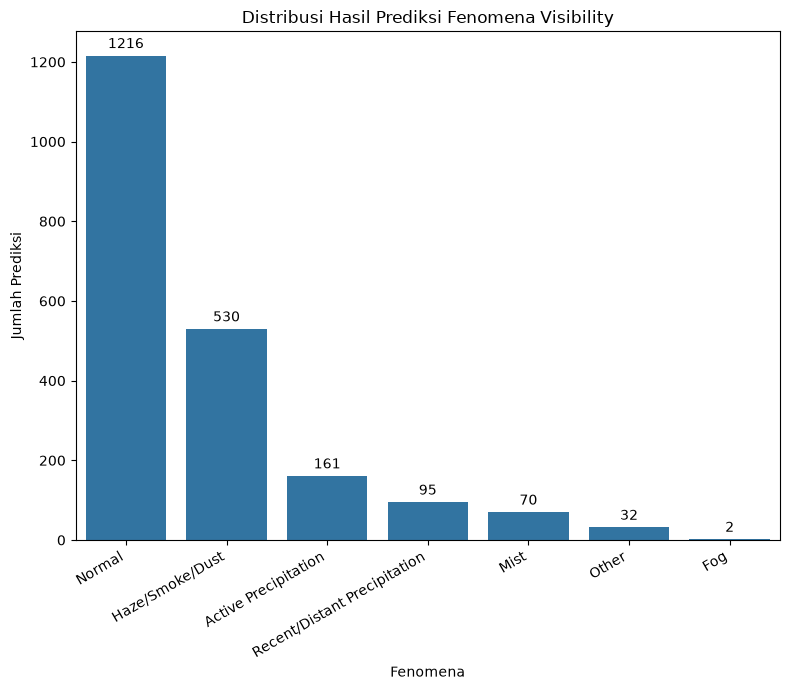

In [239]:
prediction_labels = (
    external_clean['predicted_phenomenon']
    .map({v: k for k, v in label_map.items()})
)

plt.figure(figsize=(8, 7))

ax = sns.countplot(
    x=prediction_labels,
    order=prediction_labels.value_counts().index
)

plt.title('Distribusi Hasil Prediksi Fenomena Visibility')
plt.xlabel('Fenomena')
plt.ylabel('Jumlah Prediksi')
plt.xticks(rotation=30, ha='right')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

## 13.9 Evaluation

**Confusion Matrix**

In [240]:
class_labels = list(label_map.values())
class_names = list(label_map.keys())

y_true = external_clean['phenomenon_encoded']
y_pred = external_clean['predicted_phenomenon']

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_labels
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.index.name = 'Actual'
cm_df.columns.name = 'Predicted'

display(cm_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,101,0,13,9,11,0,10
Fog,0,1,0,1,0,0,0
Haze/Smoke/Dust,26,0,285,22,4,1,8
Mist,3,1,0,36,0,0,0
Normal,16,0,218,1,1152,27,55
Other,1,0,2,0,6,3,1
Recent/Distant Precipitation,14,0,12,1,43,1,21


**Classification Report**

In [241]:
report = classification_report(
    y_true,
    y_pred,
    labels=class_labels,
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(
    report_df.style.format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

,precision,recall,f1-score,support
Active Precipitation,0.627,0.701,0.662,144
Fog,0.500,0.500,0.500,2
Haze/Smoke/Dust,0.538,0.824,0.651,346
Mist,0.514,0.900,0.655,40
Normal,0.947,0.784,0.858,1469
Other,0.094,0.231,0.133,13
Recent/Distant Precipitation,0.221,0.228,0.225,92
accuracy,0.759,0.759,0.759,1
macro avg,0.492,0.595,0.526,2106
weighted avg,0.813,0.759,0.774,2106


## 13.10 Misclassification Analysis

**Mengidentifikasi Kesalahan Prediksi**

In [242]:
misclassified = external_clean.loc[
    external_clean['phenomenon_encoded'] !=
    external_clean['predicted_phenomenon']
].copy()

In [243]:
inverse_label_map = {
    value: key for key, value in label_map.items()
}

misclassified['actual_label'] = (
    misclassified['phenomenon_encoded']
    .map(inverse_label_map)
)

misclassified['predicted_label'] = (
    misclassified['predicted_phenomenon']
    .map(inverse_label_map)
)

In [244]:
print("Jumlah prediksi salah:", len(misclassified))
print(
    "Persentase prediksi salah:",
    f"{len(misclassified) / len(external_clean) * 100:.2f}%"
)

Jumlah prediksi salah: 507
Persentase prediksi salah: 24.07%


In [245]:
misclassified[
    ['datetime_wib', 'actual_label', 'predicted_label']
].head(15)

,datetime_wib,actual_label,predicted_label
1,2026-01-01 08:00:00,Mist,Active Precipitation
4,2026-01-01 11:00:00,Normal,Recent/Distant Precipitation
12,2026-01-01 19:00:00,Normal,Other
13,2026-01-01 20:00:00,Haze/Smoke/Dust,Other
23,2026-01-02 06:00:00,Active Precipitation,Mist
29,2026-01-02 12:00:00,Recent/Distant Precipitation,Active Precipitation
30,2026-01-02 13:00:00,Normal,Recent/Distant Precipitation
31,2026-01-02 14:00:00,Normal,Recent/Distant Precipitation
32,2026-01-02 15:00:00,Normal,Recent/Distant Precipitation
35,2026-01-02 18:00:00,Haze/Smoke/Dust,Active Precipitation


**Distribusi Kesalahan Klasifikasi**

In [246]:
error_distribution = (
    misclassified
    .groupby(['actual_label', 'predicted_label'])
    .size()
    .reset_index(name='Count')
    .sort_values('Count', ascending=False)
    .reset_index(drop=True)
)

display(error_distribution)

,actual_label,predicted_label,Count
0,Normal,Haze/Smoke/Dust,218
1,Normal,Recent/Distant Precipitation,55
2,Recent/Distant Precipitation,Normal,43
3,Normal,Other,27
4,Haze/Smoke/Dust,Active Precipitation,26
5,Haze/Smoke/Dust,Mist,22
6,Normal,Active Precipitation,16
7,Recent/Distant Precipitation,Active Precipitation,14
8,Active Precipitation,Haze/Smoke/Dust,13
9,Recent/Distant Precipitation,Haze/Smoke/Dust,12


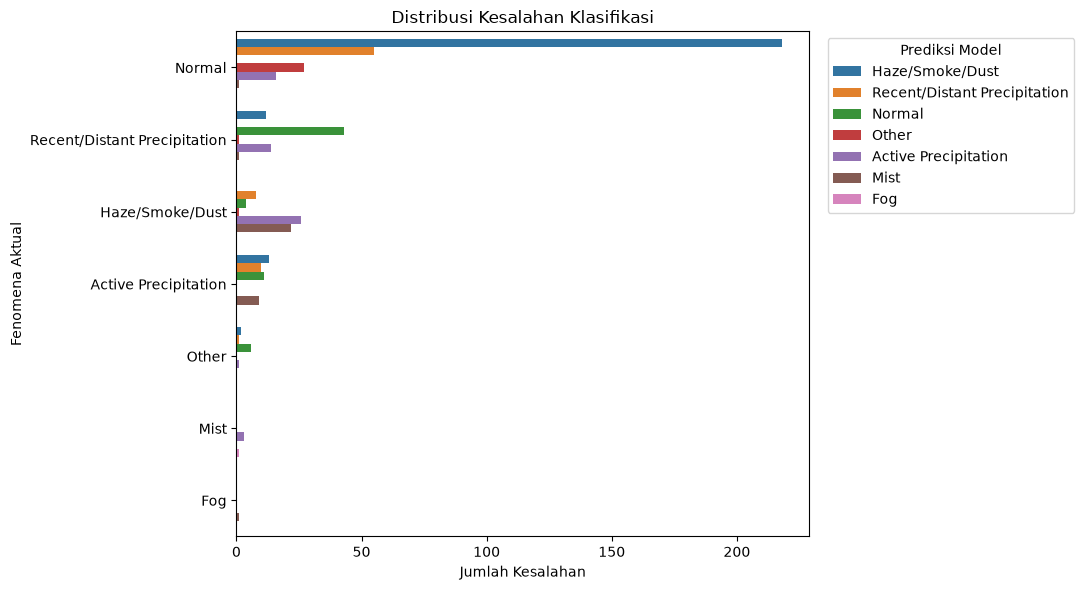

In [247]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=error_distribution,
    x='Count',
    y='actual_label',
    hue='predicted_label'
)

plt.title('Distribusi Kesalahan Klasifikasi')
plt.xlabel('Jumlah Kesalahan')
plt.ylabel('Fenomena Aktual')
plt.legend(title='Prediksi Model', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [248]:
analysis_features = [
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_1',
    'cloud_cover_oktas_m',
    'visibility_vv'
]

In [249]:
error_characteristics = (
    misclassified
    .groupby(['actual_label', 'predicted_label'])[analysis_features]
    .mean()
    .round(2)
)

display(error_characteristics)

wind_dir_deg_dd  \
actual_label                 predicted_label                                 
Active Precipitation         Haze/Smoke/Dust                        265.38   
                             Mist                                   214.44   
                             Normal                                 235.45   
                             Recent/Distant Precipitation           219.00   
Fog                          Mist                                   310.00   
Haze/Smoke/Dust              Active Precipitation                   220.38   
                             Mist                                   219.55   
                             Normal                                  60.00   
                             Other                                   60.00   
                             Recent/Distant Precipitation           275.00   
Mist                         Active Precipitation                   216.67   
                             Fog                                    240.00   
Normal                       Active Precipitation                   211.25   
                             Haze/Smoke/Dust                        171.70   
                             Mist                                   140.00   
                             Other                                   98.52   
                             Recent/Distant Precipitation           265.27   
Other                        Active Precipitation                     0.00   
                             Haze/Smoke/Dust                         45.00   
                             Normal                                 121.67   
                             Recent/Distant Precipitation            60.00   
Recent/Distant Precipitation Active Precipitation                   213.57   
                             Haze/Smoke/Dust                        198.33   
                             Mist                                   150.00   
                             Normal                                 202.56   
                             Other                                  320.00   

                                                           wind_speed_ff  \
actual_label                 predicted_label                               
Active Precipitation         Haze/Smoke/Dust                        4.15   
                             Mist                                   2.22   
                             Normal                                 4.55   
                             Recent/Distant Precipitation           3.30   
Fog                          Mist                                   2.00   
Haze/Smoke/Dust              Active Precipitation                   3.15   
                             Mist                                   1.68   
                             Normal                                 2.75   
                             Other                                  1.00   
                             Recent/Distant Precipitation           2.25   
Mist                         Active Precipitation                   2.67   
                             Fog                                    1.00   
Normal                       Active Precipitation                   3.50   
                             Haze/Smoke/Dust                        2.56   
                             Mist                                   2.00   
                             Other                                  3.04   
                             Recent/Distant Precipitation           4.16   
Other                        Active Precipitation                   0.00   
                             Haze/Smoke/Dust                        1.50   
                             Normal                                 2.83   
                             Recent/Distant Precipitation           3.00   
Recent/Distant Precipitation Active Precipitation                   3.36   
                             Haze/Smoke/Dust      

In [250]:
normal_correct = external_clean[
    (external_clean['phenomenon'] == 'Normal') &
    (external_clean['predicted_phenomenon'] == label_map['Normal'])
]

normal_misclassified = external_clean[
    (external_clean['phenomenon'] == 'Normal') &
    (external_clean['predicted_phenomenon'] == label_map['Haze/Smoke/Dust'])
]

In [251]:
comparison = pd.DataFrame({
    'Normal - Correct': normal_correct[analysis_features].mean(),
    'Normal - Predicted as Haze': normal_misclassified[analysis_features].mean()
}).round(2)

display(comparison)

,Normal - Correct,Normal - Predicted as Haze
wind_dir_deg_dd,185.33,171.70
wind_speed_ff,4.70,2.56
pressure_qff_mb_derived,1010.04,1010.69
temp_drybulb_c_tttttt,28.55,26.10
temp_dewpoint_c_tdtdtd,23.21,23.65
temp_wetbulb_c,24.71,24.29
relative_humidity_pc,73.72,86.56
cloud_low_cover_1,3.27,2.33
cloud_cover_oktas_m,6.82,6.58
visibility_vv,9.95,7.17


In [252]:
normal_comparison = external_clean[
    external_clean['phenomenon'] == 'Normal'
].copy()

normal_comparison['Prediction Status'] = (
    normal_comparison['predicted_phenomenon']
    .map({
        label_map['Normal']: 'Correct Prediction',
        label_map['Haze/Smoke/Dust']: 'Predicted as Haze/Smoke/Dust'
    })
)

In [253]:
comparison_features = [
    'relative_humidity_pc',
    'temp_drybulb_c_tttttt',
    'wind_speed_ff',
    'visibility_vv'
]

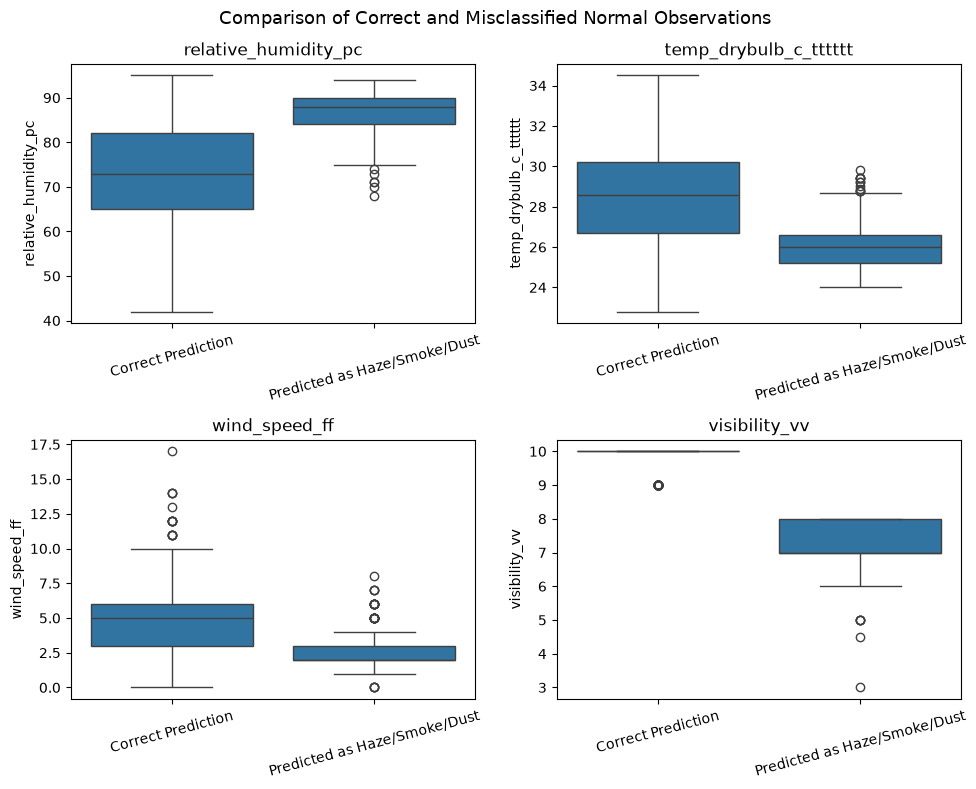

In [254]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, feature in zip(axes.flat, comparison_features):
    sns.boxplot(
        data=normal_comparison[
            normal_comparison['Prediction Status'].notna()
        ],
        x='Prediction Status',
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle(
    'Comparison of Correct and Misclassified Normal Observations',
    fontsize=13
)

plt.tight_layout()
plt.show()

**Notes:**

- **Proporsi dan Pola Kesalahan Dominan:** Dari total **2.106 observasi** eksternal, terdapat **507 data (24,07%)** yang mengalami kesalahan klasifikasi. Kesalahan paling banyak terjadi pada kelas **Normal** yang diprediksi sebagai **Haze/Smoke/Dust**, yaitu sebanyak **218 data**, diikuti oleh kelas **Normal** yang diprediksi sebagai **Recent/Distant Precipitation** (**55 data**), **Recent/Distant Precipitation** yang diprediksi sebagai **Normal** (**43 data**), serta **Normal** yang diprediksi sebagai **Other** (**27 data**).
- **Perbandingan Karakteristik `Normal` yang Benar vs Salah Prediksi (`Haze/Smoke/Dust`):** Observasi **Normal** yang salah diprediksi sebagai **Haze/Smoke/Dust** memiliki karakteristik parameter permukaan yang menyerupai kondisi pengaburan udara ringan, yaitu:
  - **Jarak pandang (`visibility_vv`)** lebih rendah dengan rata-rata **7,17 km** (dibandingkan **9,95 km** pada prediksi benar).
  - **Kelembapan relatif (`relative_humidity_pc`)** lebih tinggi dengan rata-rata **86,56%** (dibandingkan **73,72%**).
  - **Suhu udara (`temp_drybulb_c_tttttt`)** lebih rendah dengan rata-rata **26,10 °C** (dibandingkan **28,55 °C**).
  - **Kecepatan angin (`wind_speed_ff`)** lebih lemah dengan rata-rata **2,56 knot** (dibandingkan **4,70 knot**).
- **Tumpang Tindih pada Kelompok Presipitasi dan Kabut:** Kesalahan dua arah antara **Normal** dan **Recent/Distant Precipitation** terjadi karena pada saat hujan terjadi di kejauhan atau baru saja berhenti, parameter cuaca permukaan di lokasi stasiun (seperti *visibility* rata-rata **9,98 km** dan suhu **28,37 °C**) sering kali sudah kembali menyerupai kondisi normal. Selain itu, sebagian observasi **Haze/Smoke/Dust** juga tertukar ke **Active Precipitation** (**26 data**) dan **Mist** (**22 data**) ketika kelembapan udara meningkat tinggi (rata-rata **93,15%–95,05%**) disertai penurunan jarak pandang.
- **Implikasi Evaluasi:** Temuan ini menunjukkan bahwa kesalahan model umumnya terjadi pada zona transisi antarfenomena yang memiliki kemiripan karakteristik parameter cuaca permukaan, sehingga menjadi bahan pertimbangan penting untuk pengembangan fitur maupun penyempurnaan model pada tahap berikutnya.

# 14. Model Saving and Deployment Preparation

Tahap ini mempersiapkan model klasifikasi yang telah dilatih agar dapat digunakan pada implementasi website. Proses mencakup penyiapan model dan komponen pendukung, pembuatan fungsi pengolahan fitur, pengujian kesesuaian hasil pengolahan, serta penyimpanan model dalam format yang dapat digunakan kembali.

## 14.1 Preparing Model Components

Menyiapkan komponen yang diperlukan untuk implementasi model, meliputi model Random Forest terbaik (`final_rf`), daftar fitur yang digunakan (`selected_features`), dan pemetaan label fenomena (`label_map`). Komponen tersebut akan digunakan kembali dalam proses pengolahan data dan prediksi pada website.

In [255]:
selected_features = list(final_rf.feature_names_in_)

In [256]:
print("Model:", type(final_rf).__name__)
print("Jumlah fitur:", len(selected_features))
print("Selected features:", selected_features)
print("Label mapping:", label_map)

Model: RandomForestClassifier
Jumlah fitur: 13
Selected features: ['wind_speed_ff', 'wind_dir_sin', 'wind_dir_cos', 'is_calm', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'relative_humidity_pc', 'cloud_low_cover_1', 'cloud_cover_oktas_m', 'visibility_vv', 'hour_sin', 'hour_cos']
Label mapping: {'Active Precipitation': 0, 'Fog': 1, 'Haze/Smoke/Dust': 2, 'Mist': 3, 'Normal': 4, 'Other': 5, 'Recent/Distant Precipitation': 6}


## 14.2 Building Feature Engineering Function

Membuat fungsi `build_features()` untuk mengolah satu data observasi hasil decoding SYNOP menjadi 13 fitur yang dibutuhkan oleh model Random Forest. Fungsi ini menerapkan transformasi waktu ke WIB, cyclical encoding, dan pembentukan indikator angin tenang sesuai dengan proses feature engineering pada tahap pelatihan model. Hasil pengolahan disusun berdasarkan urutan fitur yang digunakan oleh model.

In [257]:
def build_features(data, input_timezone='UTC'):
    """
    Mengolah satu data observasi menjadi 13 fitur
    yang dibutuhkan oleh model Random Forest.

    Parameters
    ----------
    data : pandas.Series atau dict
        Satu baris data hasil decoding SYNOP.

    input_timezone : str
        Zona waktu timestamp input.
        Default: UTC.

    Returns
    -------
    pandas.DataFrame
        Data dengan 13 fitur sesuai urutan model.
    """

    # Mengubah input menjadi Series
    data = pd.Series(data)

    # Mengambil timestamp
    timestamp = pd.Timestamp(data['data_timestamp'])

    # Mengonversi timestamp ke WIB
    if timestamp.tzinfo is None:
        timestamp = timestamp.tz_localize(input_timezone)

    datetime_wib = timestamp.tz_convert('Asia/Jakarta')

    # Memeriksa parameter yang dibutuhkan
    required_columns = [
        'wind_speed_ff',
        'wind_dir_deg_dd',
        'pressure_qff_mb_derived',
        'temp_drybulb_c_tttttt',
        'temp_dewpoint_c_tdtdtd',
        'relative_humidity_pc',
        'cloud_low_cover_1',
        'cloud_cover_oktas_m',
        'visibility_vv'
    ]

    missing_columns = [
        col for col in required_columns
        if col not in data.index
    ]

    if missing_columns:
        raise ValueError(
            f"Kolom belum tersedia: {missing_columns}"
        )

    # Memeriksa missing value
    if data[required_columns].isna().any():
        raise ValueError(
            "Data observasi belum lengkap. "
            "Periksa kembali parameter yang kosong."
        )

    # Mengambil jam berdasarkan waktu WIB
    hour = datetime_wib.hour

    # Feature Engineering
    features = {
        'wind_speed_ff': data['wind_speed_ff'],

        'wind_dir_sin': np.sin(
            np.deg2rad(data['wind_dir_deg_dd'])
        ),

        'wind_dir_cos': np.cos(
            np.deg2rad(data['wind_dir_deg_dd'])
        ),

        'is_calm': int(data['wind_speed_ff'] == 0),

        'pressure_qff_mb_derived':
            data['pressure_qff_mb_derived'],

        'temp_drybulb_c_tttttt':
            data['temp_drybulb_c_tttttt'],

        'temp_dewpoint_c_tdtdtd':
            data['temp_dewpoint_c_tdtdtd'],

        'relative_humidity_pc':
            data['relative_humidity_pc'],

        'cloud_low_cover_1':
            data['cloud_low_cover_1'],

        'cloud_cover_oktas_m':
            data['cloud_cover_oktas_m'],

        'visibility_vv':
            data['visibility_vv'],

        'hour_sin': np.sin(
            2 * np.pi * hour / 24
        ),

        'hour_cos': np.cos(
            2 * np.pi * hour / 24
        )
    }

    # Menyesuaikan urutan fitur dengan model
    features_df = pd.DataFrame(
        [features],
        columns=selected_features
    )

    return features_df

## 14.3 Feature Consistency Testing

Melakukan pengujian terhadap fungsi `build_features()` menggunakan data observasi dari data uji (`test_df`). Hasil pengolahan dibandingkan dengan fitur asli pada `X_test` untuk memastikan kesesuaian nama, urutan, dan nilai fitur sebelum model digunakan pada tahap implementasi website.

In [258]:
# Mengambil satu data observasi dari data uji
sample = test_df.iloc[0]

# Membentuk fitur menggunakan fungsi
sample_features = build_features(
    sample,
    input_timezone='UTC'
)

# Mengambil fitur asli dari X_test
original_features = X_test.loc[[sample.name]]

# Memeriksa urutan kolom
print(
    "Urutan fitur sesuai:",
    list(sample_features.columns) == list(original_features.columns)
)

# Membandingkan nilai fitur
print(
    "Nilai fitur sesuai:",
    np.allclose(
        sample_features.to_numpy(dtype=float),
        original_features.to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-9
    )
)

# Menampilkan perbandingan
comparison = pd.DataFrame({
    'Original': original_features.iloc[0],
    'Generated': sample_features.iloc[0]
})

display(comparison)

Urutan fitur sesuai: True
Nilai fitur sesuai: True


,Original,Generated
wind_speed_ff,0.0,0.0
wind_dir_sin,0.0,0.0
wind_dir_cos,1.0,1.0
is_calm,1.0,1.0
pressure_qff_mb_derived,1010.0,1010.0
temp_drybulb_c_tttttt,26.0,26.0
temp_dewpoint_c_tdtdtd,24.5,24.5
relative_humidity_pc,91.0,91.0
cloud_low_cover_1,3.0,3.0
cloud_cover_oktas_m,6.0,6.0


## 14.4 Saving Model and Supporting Components

Pada tahap ini, model Random Forest yang telah melalui proses pelatihan dan evaluasi disimpan bersama komponen pendukung yang diperlukan dalam proses prediksi. Komponen tersebut meliputi daftar fitur yang digunakan dan pemetaan label fenomena.

Penyimpanan dilakukan menggunakan library `joblib` agar model dan komponennya dapat dimuat kembali ketika diintegrasikan ke dalam aplikasi website tanpa perlu melakukan pelatihan ulang.

In [259]:
os.makedirs('model', exist_ok=True)

In [260]:
model_components = {
    'model': final_rf,
    'selected_features': selected_features,
    'label_map': label_map
}

In [261]:
joblib.dump(model_components, 'model/visibility_rf_model.joblib')

print("Model dan komponen pendukung berhasil disimpan.")

Model dan komponen pendukung berhasil disimpan.


## 14.5 Testing Model Loading

Tahap ini dilakukan untuk memastikan model dan komponen pendukung yang telah disimpan dapat dimuat kembali dengan benar. Pengujian dilakukan menggunakan `joblib.load()` untuk memeriksa keberhasilan pemuatan model, daftar fitur, dan pemetaan label fenomena.

In [264]:
loaded_components = joblib.load('model/visibility_rf_model.joblib')

In [265]:
loaded_model = loaded_components['model']
loaded_features = loaded_components['selected_features']
loaded_label_map = loaded_components['label_map']

In [266]:
print("Model:", type(loaded_model).__name__)
print("Jumlah fitur:", len(loaded_features))
print("Urutan fitur sesuai:", loaded_features == selected_features)
print("Label mapping sesuai:", loaded_label_map == label_map)

Model: RandomForestClassifier
Jumlah fitur: 13
Urutan fitur sesuai: True
Label mapping sesuai: True


# 15. Model Prediction Simulation

Pada tahap ini, dilakukan simulasi penggunaan model Random Forest yang telah disimpan untuk mengklasifikasikan fenomena visibility berdasarkan data observasi meteorologi. Simulasi bertujuan untuk memastikan bahwa model dapat menerima data yang telah melalui proses *feature engineering*, menghasilkan prediksi kelas fenomena, serta menampilkan probabilitas prediksi untuk setiap kelas.

Tahap ini juga mencakup perbandingan hasil prediksi dengan kelas aktual pada data pengujian untuk melihat kesesuaian keluaran model dalam proses klasifikasi.

## 15.1 Simulating Model Prediction

Tahap ini dilakukan untuk menyimulasikan proses klasifikasi menggunakan model Random Forest yang telah disimpan dan dimuat kembali. Satu data observasi dari dataset pengujian digunakan sebagai masukan. Data tersebut diproses menggunakan fungsi `build_features()` untuk menghasilkan 13 fitur yang sesuai dengan kebutuhan model.

Selanjutnya, model menghasilkan prediksi kelas fenomena berdasarkan fitur tersebut. Hasil prediksi kemudian diterjemahkan kembali menjadi nama fenomena menggunakan pemetaan label yang telah ditentukan.

In [267]:
sample = test_df.iloc[0]

In [268]:
sample_features = build_features(sample, input_timezone='UTC')

In [269]:
predicted_label = loaded_model.predict(sample_features)[0]

In [270]:
inverse_label_map = {
    value: key for key, value in loaded_label_map.items()
}
predicted_phenomenon = inverse_label_map[predicted_label]

In [271]:
observation_time = (
    pd.Timestamp(sample['data_timestamp'])
    .tz_localize('UTC')
    .tz_convert('Asia/Jakarta')
)

In [272]:
print("Hasil Prediksi")
print("==============================")
print("Waktu Observasi:", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Predicted Label:", predicted_label)
print("Predicted Phenomenon:", predicted_phenomenon)

Hasil Prediksi
Waktu Observasi: 02-01-2025 00:00 WIB
Predicted Label: 2
Predicted Phenomenon: Haze/Smoke/Dust


## 15.2 Analyzing Prediction Probabilities

Tahap ini dilakukan untuk mengetahui probabilitas prediksi yang dihasilkan model Random Forest terhadap setiap kelas fenomena visibility. Probabilitas diperoleh menggunakan metode `predict_proba()` dan menunjukkan tingkat dukungan model terhadap masing-masing kelas berdasarkan data observasi yang diberikan.

Hasil probabilitas kemudian disajikan dalam bentuk tabel dan diurutkan dari nilai tertinggi hingga terendah untuk memudahkan interpretasi keluaran model.

In [273]:
prediction_probabilities = loaded_model.predict_proba(sample_features)[0]

In [274]:
probability_df = pd.DataFrame({
    'Phenomenon': [
        inverse_label_map[label]
        for label in loaded_model.classes_
    ],
    'Probability': prediction_probabilities
})

In [275]:
probability_df = probability_df.sort_values(
    by='Probability',
    ascending=False
).reset_index(drop=True)

In [276]:
probability_df['Probability (%)'] = (
    probability_df['Probability'] * 100
).round(2)

In [277]:
display(probability_df[['Phenomenon', 'Probability (%)']])

,Phenomenon,Probability (%)
0,Haze/Smoke/Dust,94.36
1,Normal,2.48
2,Recent/Distant Precipitation,1.26
3,Active Precipitation,0.84
4,Other,0.49
5,Mist,0.48
6,Fog,0.09


## 15.3 Comparing Prediction with Actual Class

Tahap ini dilakukan untuk membandingkan hasil klasifikasi model dengan kelas fenomena aktual pada data observasi yang digunakan dalam simulasi. Perbandingan dilakukan dengan melihat kesesuaian antara kelas hasil prediksi dan label sebenarnya sehingga dapat diketahui apakah model berhasil mengklasifikasikan observasi tersebut dengan benar.

In [278]:
actual_label = sample['phenomenon_encoded']
actual_phenomenon = inverse_label_map[actual_label]

In [279]:
prediction_correct = predicted_label == actual_label

In [280]:
print("Perbandingan Hasil Prediksi")
print("==============================")
print("Waktu Observasi:", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Kelas Aktual:", actual_phenomenon)
print("Kelas Prediksi:", predicted_phenomenon)
print("Hasil Klasifikasi:", "Benar" if prediction_correct else "Tidak Sesuai")

Perbandingan Hasil Prediksi
Waktu Observasi: 02-01-2025 00:00 WIB
Kelas Aktual: Haze/Smoke/Dust
Kelas Prediksi: Haze/Smoke/Dust
Hasil Klasifikasi: Benar


## 15.4 Summary of Prediction Simulation

Berdasarkan simulasi yang telah dilakukan, model Random Forest berhasil menerima data observasi yang telah melalui proses *feature engineering* dan menghasilkan prediksi kelas fenomena *visibility* beserta probabilitas untuk setiap kelas.

Pada sampel yang diuji, model memprediksi fenomena **Haze/Smoke/Dust** dengan probabilitas sebesar **94,36%**. Hasil tersebut sesuai dengan kelas aktual pada data observasi yang sama. Hal ini menunjukkan bahwa alur penggunaan model mulai dari pembentukan fitur hingga menghasilkan keluaran klasifikasi telah berjalan sesuai dengan yang diharapkan.

Simulasi ini merupakan pengujian terhadap satu sampel dan tidak digunakan sebagai pengganti evaluasi performa model secara keseluruhan.